# Brain-age research summary: cohorts, experiments, the best model and what mattered

📄 **[PDF version of this notebook](brain_age_research_summary.pdf)** (figures, tables and formulas, no
code; regenerate with `scripts/notebook_to_pdf.py notebooks/brain_age_research_summary.ipynb`).

One notebook for the whole EEG brain-age study on TUH (2026-10-05 → 10-16), in three phases:

* **Phase 1, TUAB only.** About 50 fine-tunes of LaBraM-base on the TUH Abnormal corpus (TUAB), aimed at
  memorization: schedule, regularizers, mixup/EMA, loss shape, codebook regularization, heads, training
  from scratch (`docs/age_overfitting_experiments.md`).
* **Phase 2, full TUH.** The same recipe on cohorts drawn from the whole TUH EEG corpus (TUEG, about
  60k recordings), plus data, input and head changes (`docs/data/tuh_cohort_eval_v1.csv`).
* **Phase 3, cross-validation.** 5-fold patient-grouped CV of the three strongest phase-2 configurations
  (`notebooks/tuh_cv_summary.ipynb`, `docs/data/cv5_eval_v2.csv`).

It answers four questions:
1. Which datasets and cohorts were used, and how they differ (Section 1).
2. Which experiments ran and which came out near the best (Section 2).
3. What exactly the best experiment does, step by step (Section 3).
4. What changed relative to LaBraM as published (Section 4), and which of those changes measurably
   moved the error (Section 5).

**Contents.** 0 Metrics and evaluation sets · 1 Data · 2 Experiments · 3 The best experiment ·
4 Changes versus the LaBraM recipe · 5 Which changes mattered · 6 Conclusions.

**Inputs.**
* In git: the registry, the two CSVs, `docs/data/line_removal_ab.json`, the configs,
  `docs/data/brain_age_clearml_runs.csv` (each run's ClearML experiment) and
  `scripts/submit_tuh_cohorts.sh`. Every phase-2 run's configuration is rebuilt from
  `labram/eval/research_summary.py::PHASE2` with the same config loader the trainer uses.
  `tests/test_research_summary.py` checks that catalog against the submit script.
* Optional, on the TUH data volume (`LABRAM_TUH_ROOT`, default `/data/datasets/EEG-public/TUH_EEG`):
  * the cohort manifests behind Section 1's counts;
  * the TUH recording index and NEDC's clinical sheet behind the TUEG specification (Tables 1.6–1.13);
  * the per-recording CV predictions behind the bootstraps (`LABRAM_CV_EVAL`).

  They stay out of git under the TUH data-use agreement. Without them those cells print a note and skip,
  and the outputs show only aggregate counts.

## 0. Metrics and evaluation sets

Every error is computed **per recording**. A recording's predicted age is the mean of its window
predictions (Eq. (3.7)), in years. For a set $S$ of recordings with true age $y_i$ and predicted age
$\hat y_i$:

$$ \mathrm{MAE}(S) = \frac{1}{|S|}\sum_{i\in S}\lvert \hat y_i - y_i\rvert \tag{0.1} $$

$$ R^2(S) = 1 - \frac{\sum_{i\in S}(\hat y_i - y_i)^2}{\sum_{i\in S}(y_i - \bar y_S)^2} \tag{0.2} $$

$$ \mathrm{bias}(S) = \frac{1}{|S|}\sum_{i\in S}(\hat y_i - y_i) \tag{0.3} $$

where $\bar y_S$ is the mean true age of $S$ (`labram/eval/cv_compare.py::metrics`). The effect of a
change from a baseline run $b$ to a variant run $v$ is

$$ \Delta\mathrm{MAE} = \mathrm{MAE}_v(S) - \mathrm{MAE}_b(S), \tag{0.4} $$

so **negative is better**. Section 5 defines when a $\Delta$ is larger than run-to-run noise.

**All errors are before bias correction.** Every MAE in this notebook scores the raw prediction
$\hat y_i$. The exceptions are Table 3.5, which compares raw and bias-corrected errors, and the `cal.` columns of
Tables 2.5–2.7 (a leak-free correction, Eq. (3.11)).

The **bias slope** $\beta$ measures regression to the mean, the typical failure of an age model: old
patients are predicted too young and young ones too old. It is the least-squares slope of the error
$e_i = \hat y_i - y_i$ against the true age, with population moments over $S$
(`labram/utils/regression_metrics.py`, `age_bias_slope`):

$$ \beta(S) = \frac{\operatorname{Cov}_S(y, e)}{\operatorname{Var}_S(y)} \tag{0.5} $$

* $\beta = 0$: the error does not depend on age.
* $\beta = -1$: the prediction ignores age entirely; it is a constant.
* $\beta = -0.4$: a patient 10 years older than average is predicted about 4 years too young.

**Evaluation sets.**
* **TUAB test:** TUAB's official evaluation set, 274 recordings of 251 patients (149 normal, 125
  abnormal). It is the same 274 recordings in every phase (checked in Section 1) and no training split
  contains any of its patients, so it is the one yardstick every run shares.
* **Val:** each run's own validation split. It differs between cohorts, so it compares runs only within
  a cohort.
* **CV test / TUEG out-of-fold:** each recording of the CV pool scored by the one fold model that never
  saw its patient.

**No test label in the target normalization.** The age is z-scored with the mean and sd of the
training windows only (Eq. (0.6), Table 0.1).

**Caveat.** Phases 1 and 2 compared many configurations on the TUAB test set, which makes their
best single-split numbers optimistically selected. The CV numbers (Phase 3) and the TUEG out-of-fold
error were not used to choose anything.

In [1]:
import json
import os
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

if not any(os.path.isdir(os.path.join(p, "labram")) for p in sys.path):
    sys.path.insert(0, os.path.abspath(".."))
REPO = next(p for p in sys.path if os.path.isdir(os.path.join(p, "labram")))
warnings.filterwarnings("ignore")
from labram.eval import research_summary as rs
from labram.eval import cv_compare as cc
from labram.eval.age_plots import assert_max_columns, numbered_table, panel_labels

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 90)

AGE_JSON = os.path.join(REPO, "labram/configs/defaults/finetune_tuab_age.json")
PAPER_JSON = os.path.join(REPO, "labram/configs/defaults/finetune_tuab_paper.json")
REGISTRY = os.path.join(REPO, "docs/age_overfitting_experiments.md")
COHORT_CSV = os.path.join(REPO, "docs/data/tuh_cohort_eval_v1.csv")
CV_CSV = os.path.join(REPO, "docs/data/cv5_eval_v2.csv")
AB_JSON = os.path.join(REPO, "docs/data/line_removal_ab.json")
CLEARML_CSV = os.path.join(REPO, "docs/data/brain_age_clearml_runs.csv")
SPLITS_CSV = os.path.join(REPO, "docs/data/brain_age_run_splits.csv")
TUH = os.environ.get("LABRAM_TUH_ROOT", "/data/datasets/EEG-public/TUH_EEG")
CV_PREDS = os.path.join(os.environ.get("LABRAM_CV_EVAL", os.path.join(TUH, "_state/cohort_runs/cv_eval")),
                        "cv_preds.json")
HAVE_TUH = os.path.isdir(os.path.join(TUH, "cohorts"))
HAVE_PREDS = os.path.exists(CV_PREDS)

reg = rs.registry_master_table(REGISTRY)
cml = rs.load_clearml_runs(CLEARML_CSV)      # run -> ClearML experiment name and link
run_splits = pd.read_csv(SPLITS_CSV)          # run x split -> recordings, patients, windows, digest
split_sig = rs.split_signature(run_splits)    # run -> train/val/test recording digests
coh = pd.read_csv(COHORT_CSV)
cv = pd.read_csv(CV_CSV)
print(f"registry: {len(reg)} phase-1 runs; cohort CSV: {coh.model.nunique()} phase-2 runs; "
      f"CV CSV: {cv.exp.nunique()} experiments x {cv.fold.nunique()} folds")
print(f"TUH data volume: {'found' if HAVE_TUH else 'not found (Section 1 counts skipped)'}; "
      f"per-recording CV predictions: {'found' if HAVE_PREDS else 'not found (bootstraps skipped)'}")

registry: 45 phase-1 runs; cohort CSV: 22 phase-2 runs; CV CSV: 4 experiments x 5 folds
TUH data volume: found; per-recording CV predictions: found


### Table 0.1. The age normalization uses training ages only

Training regresses a z-scored age, and predictions are mapped back to years before any metric
(`labram/data/window_selection.py::_train_target_stats`, `losses/regression.py`):

$$ z = \frac{y - \mu}{\sigma}, \qquad \hat y = \mu + \sigma\,\hat z, \qquad
   \mu = \frac{1}{N}\sum_{w \in \mathrm{train}} y_w, \quad
   \sigma^2 = \frac{1}{N-1}\sum_{w \in \mathrm{train}} (y_w - \mu)^2 \tag{0.6} $$

where $w$ runs over the $N$ **selected training windows** of the run (after trimming), $y_w$ is the age
of the window's recording, and $\hat z$ is the model output. If $\mu$ or $\sigma$ included a test
recording, the test ages would leak into training and into every test prediction.

The check (`scripts/check_target_norm_leak.py`, `docs/data/target_norm_leak_check.csv`) rebuilds each
training setup exactly as the trainer does (cohort, CV fold, window selection) twice. The first build is
as recorded; the second has every **test** recording's age shifted by +40 years. Columns:
* `train` / `test recordings` and `train ∩ test recordings` (must be 0);
* `mean` / `std`: $\mu$, $\sigma$ of Eq. (0.6) as the run uses them, in years;
* `mean` / `std, test ages +shift`: the same after the test ages were shifted. They must not change;
* `= train windows' own stats`: $\mu$, $\sigma$ equal the training windows' own mean and sample sd;
* `test targets moved by`: the median change of the test targets, 40, confirming the shift took effect;
* `normalization uses test ages`: "no" when the two (mean, std) pairs are identical.

Phase 1 is checked on the local TUAB v3.0.1 copy (the phase-1 runs used v3.0.0, with the same split and
code). The CV rows check fold 0 in both CV schemes. The other folds use the same code on other
recordings.


In [2]:
t01 = pd.read_csv(os.path.join(REPO, "docs/data/target_norm_leak_check.csv")).set_index("setup")
assert (t01["normalization uses test ages"] == "no").all() and (t01["train ∩ test recordings"] == 0).all()
display(numbered_table(t01, "0.1", "The age normalization uses training ages only"))


,train recordings,test recordings,train ∩ test recordings,mean,std,"mean, test ages +shift","std, test ages +shift",= train windows' own stats,test targets moved by,normalization uses test ages
setup,,,,,,,,,,
phase 1: TUAB (D recipe),2145,274,0,48.88,17.82,48.88,17.82,True,40.00,no
phase 2: cohort all_both_v3 (Exp4*),25613,274,0,52.34,17.59,52.34,17.59,True,40.00,no
"phase 3: CV fold 0, test = fold (cvbase/cvctrl/cvaug)",17607,5663,0,52.49,17.28,52.49,17.28,True,40.00,no
"phase 3: CV fold 0, test = TUAB held out (cvaugval)",23372,274,0,52.74,17.45,52.74,17.45,True,40.00,no


## 1. Data: every dataset and cohort

All data comes from the TUH EEG corpus. TUAB (TUH Abnormal, about 3k recordings with a normal/abnormal
label) is a subset of TUEG (the full TUH EEG corpus, about 60k recordings). The age label is parsed from
each EDF header (`labram/data/tuh_metadata.py`). Every dataset uses the same signal format:
* 23 referential channels at 200 Hz in µV, 0.1–75 Hz band-pass;
* 10 s windows;
* the first and last 60 s of each recording dropped;
* evaluation on the first 5 minutes after the trim (`labram/data/window_selection.py`).

The datasets differ in which recordings they contain, how mains interference is removed, and how
patients are split.

**Reading order.**
* Table 1.1: the two **raw corpora**, TUAB and TUEG, as downloaded.
* Table 1.2: why each removed recording was removed.
* Table 1.3: how each training dataset is built from them, one inclusion rule at a time, with the
  recordings and patients each rule removes.
* Tables 1.4–1.5: the resulting datasets and their splits; Figure 1.1: the final training set by source
  (TUAB / TUEG / total) and status.
* Tables 1.6–1.13 and Figure 1.2: a closer look at TUEG.

**Lineage.**
* `TUAB v3.0.0` (phase 1) → `TUAB v3.0.1 interp` (phase-2 control): same recordings and split, mains
  removed by 50 + 60 Hz spectrum interpolation instead of a 50 Hz notch.
* `normal_TUEG_v1`, `normal_both_v1`: normal recordings only (TUEG alone; TUAB + TUEG).
* `all_both_v1` → `v2` → `v3`: every recording (normal, abnormal, unlabelled), with TUAB patients kept
  in their TUAB split.
  * `v2` gives TUEG one patient split shared by every cohort, so validation is comparable across
    cohorts.
  * `v3` adds the TUEG recordings that lack only the T1/T2 electrodes.
* `v3_compact` / `v3_cvcompact`: byte-for-byte subsets of `v3` that store only the windows a run reads
  (`dataset_maker/make_compact_cohort.py`). `cvcompact` keeps both training and evaluation windows of
  every recording, so any CV fold can use any recording.

Tables 1.6–1.13 and Figure 1.2 at the end of this section specify TUEG itself: size, subsets, labels
and age.

All cohorts are built by `dataset_maker/make_cohort_dataset.py`, which drops every TUEG recording of a
TUAB-test patient and asserts that no patient is in two splits.

### Table 1.1. Raw data: TUAB and TUEG, and what the final cohort selects

One row per part of the raw data, split by status (`rs.raw_summary`). TOTAL counts every recording
once:
* **TUAB train**, **TUAB eval (test)**: the two official splits of TUAB v3.0.1 (2,993 recordings),
  with TUAB's own normal / abnormal label.
* **TUEG (not in TUAB)**: the rest of TUEG v2.0.2. Every TUAB recording is also in TUEG, so these
  rows hold only what TUEG adds. Its status comes from NEDC's clinical report sheet; recordings without
  a sheet entry have **no label**.
* **TOTAL**: all of TUEG, 70,830 recordings, each counted once.

Columns, left to right:
* `patients`, `recordings`: the raw counts. A recording is one EDF file, a "case". A patient with
  recordings of different status counts in each status row, so the status rows' patients add up to
  more than the subtotal.
* `readable EDF, ≥ 60 s`: the recordings converted to the npy format (Section "step process" below).
* `age known`: of those, the ones with a valid age in the EDF header (TUH redacts 90+).
* `T1/T2 missing (selected)`: selected recordings that lack only the T1/T2 electrodes. They are kept,
  and the model leaves the two channels out per sample.
* `selected recordings`, `selected patients`: what the final cohort `all_both_v3` keeps. That is the
  dataset of the best models: train 25,613 + val 3,422 + test 274 = 29,309 recordings.
* `removed`: `recordings` − `selected recordings`. Table 1.2 gives the reason for each removed
  recording, and Table 1.3 follows the rules step by step for every dataset.

Phase 1 trains on TUAB only and selects differently; Table 1.3 gives that flow too.

In [3]:
TUEG_INDEX = os.path.join(TUH, "index/tuh_index.parquet")
TUEG_SHEET = os.path.join(TUH, "index/nedc/metadata_v12.xlsm.xlsx")
HAVE_TUEG = os.path.exists(TUEG_INDEX) and os.path.exists(TUEG_SHEET)
if HAVE_TUEG:
    tueg = rs.tueg_recordings(TUEG_INDEX, TUEG_SHEET)
    with open(os.path.join(TUH, "tueg/v2.0.2/processed_npy_interp50-60_float16/manifest.json")) as f:
        converted = [r["stem"] for r in json.load(f)["recordings"]]
    final = pd.read_parquet(os.path.join(TUH, "cohorts/all_both_v3/cohort.parquet"))
    t11 = rs.raw_summary(tueg, converted, final).set_index(["part", "status"])
    display(numbered_table(t11, "1.1", "Raw data: TUAB and TUEG, and what the final cohort selects", precision=0))
else:
    print("TUH recording index / clinical sheet not found: set LABRAM_TUH_ROOT to show Tables 1.1-1.3.")


### Table 1.2. Why each raw recording was removed

Table 1.1's `removed` column, broken down by reason for the final cohort `all_both_v3`
(`rs.removal_reasons`). Every raw recording counts once, under the **first** rule it fails, in the order
the builder applies them (`dataset_maker/make_cohort_dataset.py`). The rows sum to the `raw` row, and
`selected` matches Table 1.1. The rules:
* **EDF shorter than 60 s** / **EDF unreadable**: never converted to npy. One unreadable TUEG EDF has
  none of the 23 channels.
* **age unknown**: no valid age in the EDF header. TUH redacts ages of 90 and over.
* **age outside the cohort's range**: the TUEG cohorts use 18–89 years, so children and teenagers are
  out, including TUAB's.
* **recording shorter than the minimum length**: under 5 minutes. Too little EEG is left after the 60 s
  trims for the 5-minute evaluation.
* **channels other than the allowed ones missing**: the recording lacks a channel other than T1/T2,
  e.g. A1/A2 in the `*_a` montages. Recordings lacking only T1/T2 are kept.
* **patient is in the TUAB test set**: all other recordings of the 251 test patients are kept out of
  training and validation.
* **over the per-patient cap**: at most 10 train/val recordings per patient, drawn with a fixed seed.
  * It removes recordings, not patients: every patient with a usable recording keeps up to 10.
  * Some patients were recorded hundreds of times.
  * The cap counts a patient's TUAB and TUEG recordings together. TUAB patients who also have many
    TUEG recordings can therefore lose TUAB recordings to the draw.

`patients` counts the patients with at least one recording removed for that reason. A patient can
appear under several reasons.

In [4]:
if HAVE_TUEG:
    final_manifest = json.load(open(os.path.join(TUH, "cohorts/all_both_v3/manifest.json")))
    t12_reasons = rs.removal_reasons(tueg, converted, final, final_manifest,
                                     os.path.join(TUH, "tuab/v3.0.1/edf/processed_npy/age_split.json"))
    display(numbered_table(t12_reasons, "1.2", "Why each raw recording was removed", precision=0))

### How the datasets are built: the step process and the data split

**Steps, in order.** Table 1.3 counts each one.
1. **Index.** Both corpora are scanned into one recording index, one row per EDF
   (`dataset_maker/tuh_index.py`). Age, sex and the TUAB label come from the EDF headers and folders;
   the report finding comes from NEDC's clinical sheet (`dataset_maker/tuh_clinical.py`).
2. **Convert** (`dataset_maker/make_TUH_npy.py`). Every readable EDF of at least 60 s becomes one npy
   file:
   * the 23 model channels in a fixed order; a missing channel is zero-filled and flagged in a
     channel mask;
   * 0.1–75 Hz band-pass and mains removal (50 + 60 Hz spectrum interpolation);
   * resampled to 200 Hz, in µV.
3. **Select per dataset** (`dataset_maker/make_cohort_dataset.py`):
   * age 18–89 years;
   * recording at least 5 minutes long;
   * channel rule: all 23 channels, or in v3 only T1/T2 may be missing;
   * for the `normal_*` cohorts only: report-normal, no neurological diagnosis, no sedating
     medication.
4. **Protect the test set.** Every recording of a patient in TUAB's eval split is removed from
   training and validation. TUAB's eval split itself (274 recordings with a known age) is the test set
   of every dataset.
5. **Split by patient**, never by recording:
   * TUAB patients keep the split of phase 1: TUAB's train split divided into train and a seeded 20 %
     val, patient-disjoint;
   * TUEG patients: `v1` draws a seeded 10 % patient val per cohort. `v2` / `v3` use one shared patient
     split for all cohorts (`dataset_maker/tueg_patient_split.py`), so a model can be validated on
     another cohort's val without patient leakage.

   The builder asserts that no patient is in two splits.
6. **Cap per patient.** At most 10 train/val recordings per patient, drawn with a fixed seed, so that
   patients recorded hundreds of times do not dominate.
7. **Windows.** Each training recording contributes at most 20 minutes of 10 s windows. Val and test
   score the first 5 minutes after 60 s trims at both ends (Section 0).
8. **Phase 3, cross-validation.** The train + val of `all_both_v3` (29,035 recordings) is split into 5
   patient-grouped folds. Fold $k$ tests, fold $k+1$ validates, and the other three train. The TUAB
   test set stays outside every fold.

### Table 1.3. From the raw corpora to the training datasets: inclusion flow

Each row is the set of recordings left after one more inclusion rule. Columns as in Table 1.1, plus
`removed`, the recordings that rule took out. The rows are replayed from each dataset's recorded build
parameters with the builder's own functions:
* `rs.tuab_flow` for TUAB (`data/age_splits.py`, `make_TUAB.py`);
* `rs.cohort_flow` for the TUEG cohorts (`dataset_maker/make_cohort_dataset.py`).

Each flow's final counts are checked against the dataset's split files, so the table is exact.

The datasets:
* **TUAB (phase 1):** TUAB only. Ages 1–89, all 23 channels. TUAB's train split is divided
  patient-disjointly into train and val; its eval split is the test set.
* **TUEG cohorts (phase 2–3):** built from the TUEG npy export.
  * Shared rules (first block): readable EDF of at least 60 s, age 18–89, recording at least 5 minutes.
  * Per-cohort rules (later blocks): channel completeness and, for the `normal_*` cohorts, the normal
    filter (report-normal, no neurological diagnosis, no sedating medication).
  * Then every recording of a TUAB-test patient is removed, so no test patient is ever trained on.
  * At most 10 train/val recordings are kept per patient.
  * The test set is always TUAB's eval split.
  * `all_both_v1` and `v2` contain the same recordings and differ only in how TUEG patients are split
    into train and val. `all_both_v3` is the cohort of the best models, and its train + val
    (29,035 recordings) is the CV pool of phase 3.

In [5]:
if HAVE_TUEG:
    blocks = {("TUAB (phase 1)", ""): rs.tuab_flow(
        tueg, os.path.join(TUH, "tuab/v3.0.1/edf/legacy_v3.0.0_processed/age_split.json"))}
    shared = None
    for name in ("normal_tueg_v1", "normal_both_v1", "all_both_v1", "all_both_v3"):
        f = rs.cohort_flow(tueg, json.load(open(os.path.join(TUH, "cohorts", name, "manifest.json"))),
                           os.path.join(TUH, "tuab/v3.0.1/edf/processed_npy/age_split.json"))
        if shared is None:
            shared = f.iloc[:4]
            blocks[("TUEG cohorts", "shared rules")] = shared
        label = rs.display_name(name) + (" = v2 (same recordings)" if name == "all_both_v1" else "")
        blocks[("TUEG cohorts", label)] = f.iloc[4:]
    t12 = pd.concat({k: v.set_index("step") for k, v in blocks.items()}, names=["dataset", "cohort", "step"])
    display(numbered_table(t12, "1.3", "Inclusion flow from the raw corpora to the datasets", precision=0))

### Table 1.4. The training datasets (cohorts): contents, rules and splits

One row per dataset. Names show the corpora in capitals (TUAB, TUEG); the directories on disk under
`$LABRAM_TUH_ROOT/cohorts/` use the same names in lower case (e.g. `normal_tueg_v1`).

| column | meaning |
|---|---|
| `phase` | the phase that used the dataset |
| `contents` | which recordings it holds |
| `line removal` | how mains interference is removed (from the dataset's `manifest.json`) |
| `rules` | inclusion rules: `age` range in years; `≥ min` minimum recording length in minutes; `≤ k/patient` at most *k* train/val recordings per patient; `T1/T2 may be missing` |
| `size (train / val / test)` | recordings per split, from the dataset's `age_split.json` (`rs.split_sizes`); the CV runs split train + val into 5 folds |
| `TUEG split` | how TUEG patients are split; TUAB patients always keep their TUAB split |
| `used by` | the runs of Tables 2.2–2.7 trained on it |

In [6]:
DATASETS = [
    ("TUAB v3.0.0", "1", "tuab/v3.0.1/edf/legacy_v3.0.0_processed", "TUAB, all recordings (normal + abnormal)",
     "phase-1 runs (Table 2.2)"),
    ("TUAB v3.0.1 interp", "2", "tuab/v3.0.1/edf/processed_npy_interp50-60", "TUAB, all recordings", "Control"),
    ("normal_TUEG_v1", "2", "cohorts/normal_tueg_v1", "TUEG normal, patients outside TUAB; no test split", "Exp2"),
    ("normal_both_v1", "2", "cohorts/normal_both_v1", "TUAB normal + TUEG normal", "Exp1, Exp1b, Exp1t, Exp1f"),
    ("all_both_v1", "2", "cohorts/all_both_v1", "TUAB + TUEG, every recording (normal / abnormal / no label)",
     "Exp3, Exp3b, Exp3q, Exp3c"),
    ("all_both_v2", "2", "cohorts/all_both_v2", "as v1, TUEG patients on the shared split",
     "Exp3v2, Exp3cond, Exp3clscond"),
    ("all_both_v3", "2", "cohorts/all_both_v3", "v2 + TUEG recordings missing only T1/T2",
     "Exp4drop, Exp4base, Exp4ctrl, Exp4aug, Exp4aug15"),
    ("all_both_v3_compact", "2", "cohorts/all_both_v3_compact", "v3, only the windows Exp4base reads", "Exp4basec"),
    ("all_both_v3_cvcompact", "3", "cohorts/all_both_v3_cvcompact",
     "v3, training + evaluation windows of every recording (CV pool = train + val)", "cvbase, cvctrl, cvaug"),
]


def manifest(path):
    p = os.path.join(TUH, path, "manifest.json")
    return json.load(open(p)) if os.path.exists(p) else {}


def rules(m):
    c = m.get("cohort", {})
    if not c:
        return "age 1–89 (TUAB)"
    r = [f"age {c['min_age']}–{c['max_age']}", f"≥ {c['min_minutes']:g} min", f"≤ {c['max_per_subject']}/patient"]
    if c.get("allow_missing"):
        r.append("/".join(c["allow_missing"]) + " may be missing")
    return ", ".join(r)


rows = []
for name, phase, path, contents, used in DATASETS:
    m = manifest(path) if HAVE_TUH else {}
    lr = m.get("line_removal") or ("notch:50" if "legacy" in path else "–")
    c = m.get("cohort", {})
    split = ("shared patient split v2" if c.get("patient_split") else
             ("seeded 10 % val" if c else "TUAB: seeded 20 % val, official test"))
    size = "–"
    if HAVE_TUH and os.path.exists(os.path.join(TUH, path, "age_split.json")):
        n = rs.split_sizes(os.path.join(TUH, path, "age_split.json"))
        size = " / ".join(f"{n[s]:,}" for s in ("train", "val", "test"))
        if phase == "3":
            size += f" (CV pool {n['train'] + n['val']:,})"
    rows.append({"dataset": name, "phase": phase, "contents": contents, "line removal": lr,
                 "rules": rules(m) if HAVE_TUH else "–", "size (train / val / test)": size,
                 "TUEG split": split, "used by": used})
table_1_1 = pd.DataFrame(rows)
numbered_table(table_1_1.set_index("dataset"), "1.4", "The training datasets (cohorts): contents, rules and splits")

,phase,contents,line removal,rules,size (train / val / test),TUEG split,used by
dataset,,,,,,,
TUAB v3.0.0,1,"TUAB, all recordings (normal + abnormal)",notch:50,age 1–89 (TUAB),"2,145 / 556 / 274","TUAB: seeded 20 % val, official test",phase-1 runs (Table 2.2)
TUAB v3.0.1 interp,2,"TUAB, all recordings","interp:50,60",age 1–89 (TUAB),"2,145 / 556 / 274","TUAB: seeded 20 % val, official test",Control
normal_TUEG_v1,2,"TUEG normal, patients outside TUAB; no test split","interp:50,60","age 18–89, ≥ 5 min, ≤ 10/patient","3,763 / 395 / 0",seeded 10 % val,Exp2
normal_both_v1,2,TUAB normal + TUEG normal,"interp:50,60","age 18–89, ≥ 5 min, ≤ 10/patient","5,450 / 843 / 274",seeded 10 % val,"Exp1, Exp1b, Exp1t, Exp1f"
all_both_v1,2,"TUAB + TUEG, every recording (normal / abnormal / no label)","interp:50,60","age 18–89, ≥ 5 min, ≤ 10/patient","20,368 / 2,905 / 274",seeded 10 % val,"Exp3, Exp3b, Exp3q, Exp3c"
all_both_v2,2,"as v1, TUEG patients on the shared split","interp:50,60","age 18–89, ≥ 5 min, ≤ 10/patient","20,470 / 2,803 / 274",shared patient split v2,"Exp3v2, Exp3cond, Exp3clscond"
all_both_v3,2,v2 + TUEG recordings missing only T1/T2,"interp:50,60","age 18–89, ≥ 5 min, ≤ 10/patient, T1/T2 may be missing","25,613 / 3,422 / 274",shared patient split v2,"Exp4drop, Exp4base, Exp4ctrl, Exp4aug, Exp4aug15"
all_both_v3_compact,2,"v3, only the windows Exp4base reads","interp:50,60","age 18–89, ≥ 5 min, ≤ 10/patient, T1/T2 may be missing","25,613 / 3,422 / 274",shared patient split v2,Exp4basec
all_both_v3_cvcompact,3,"v3, training + evaluation windows of every recording (CV pool = train + val)","interp:50,60","age 18–89, ≥ 5 min, ≤ 10/patient, T1/T2 may be missing","25,613 / 3,422 / 274 (CV pool 29,035)",shared patient split v2,"cvbase, cvctrl, cvaug"


### Table 1.5. Size and composition per split

For each dataset and split:
* `recordings` and `patients`;
* `from TUAB`: recordings that are also in TUAB;
* `normal` / `abnormal` / `no label`: the recording's report status (TUEG recordings without a
  normal/abnormal report have no label);
* `age mean` and `age sd`: the true age's mean and sample standard deviation (years).

Computed from each dataset's `cohort.parquet` / `manifest.json`, or from `age_split.json` +
`age_metadata.json` for the TUAB-only datasets
(`labram/eval/research_summary.py::cohort_summary`, `tuab_split_summary`).

In [7]:
summaries, test_stems = {}, {}
if HAVE_TUH:
    for name, _, path, _, _ in DATASETS:
        d = os.path.join(TUH, path)
        if os.path.exists(os.path.join(d, "cohort.parquet")):
            c = pd.read_parquet(os.path.join(d, "cohort.parquet"))
            summaries[name] = rs.cohort_summary(c, manifest(path))
            test_stems[name] = set(c.stem[c.split == "test"])
        else:
            summaries[name] = rs.tuab_split_summary(os.path.join(d, "age_split.json"),
                                                    os.path.join(d, "age_metadata.json"))
            files = json.load(open(os.path.join(d, "age_split.json")))["files"].get("test", [])
            test_stems[name] = {os.path.basename(f).rsplit("_", 1)[0] for f in files}
    table_1_2 = pd.concat(summaries, names=["dataset", "_"]).droplevel("_").set_index("split", append=True)
    display(numbered_table(table_1_2, "1.5", "Size and composition per split", precision=1))
else:
    print("TUH data volume not found: set LABRAM_TUH_ROOT to show Table 1.5.")

In [8]:
if HAVE_TUH:
    ref = test_stems["TUAB v3.0.0"]
    same = {k: (v == ref) for k, v in test_stems.items() if v}
    print(f"TUAB test: {len(ref)} recordings; identical in every dataset with a test split: {all(same.values())}")
    print({k: v for k, v in same.items()})

TUAB test: 274 recordings; identical in every dataset with a test split: True
{'TUAB v3.0.0': True, 'TUAB v3.0.1 interp': True, 'normal_both_v1': True, 'all_both_v1': True, 'all_both_v2': True, 'all_both_v3': True, 'all_both_v3_compact': True, 'all_both_v3_cvcompact': True}


**Reading Table 1.5.**
* **Scale:** training grows from 2,145 TUAB recordings (phase 1) to 25,613 recordings of about 12k
  patients (`all_both_v3`).
* **Composition:** in the `all_both` cohorts about half the training recordings are abnormal and about
  7 % have no label.
* **Normal-only cohorts:** `normal_*` hold only normal recordings, but their test split is still the full
  TUAB test set, abnormal recordings included.
* **Test set:** the 274 TUAB test recordings are identical across datasets (the check above), so every
  TUAB test number in Sections 2–5 is on the same recordings.

### Figure 1.1. Composition and age of the training set

The training set of the final cohort `all_both_v3`, the one the best models use: its train split,
25,613 recordings. It is split by source:
* **TUAB:** recordings that are in TUAB;
* **TUEG:** the TUEG recordings that are not in TUAB;
* **Total:** both.

Status is the recording's normal / abnormal / no-label status (Eq. (1.2)). The other datasets of
Table 1.4 are subsets or reshuffles of the same recordings, so they are not drawn again. Table 1.5 gives
each dataset's counts per split.
* (a) Training recordings per source, stacked by status. Each segment shows its count, and the bar's
  label gives the total and the number of patients.
* (b) Distribution of true age (years) per source, as a density (step histogram, 2-year bins).
* (c) TUAB by status, as in (b).
* (d) TUEG by status, as in (b).

Each legend gives $n$ (recordings), the mean ± sample standard deviation of age and its median.

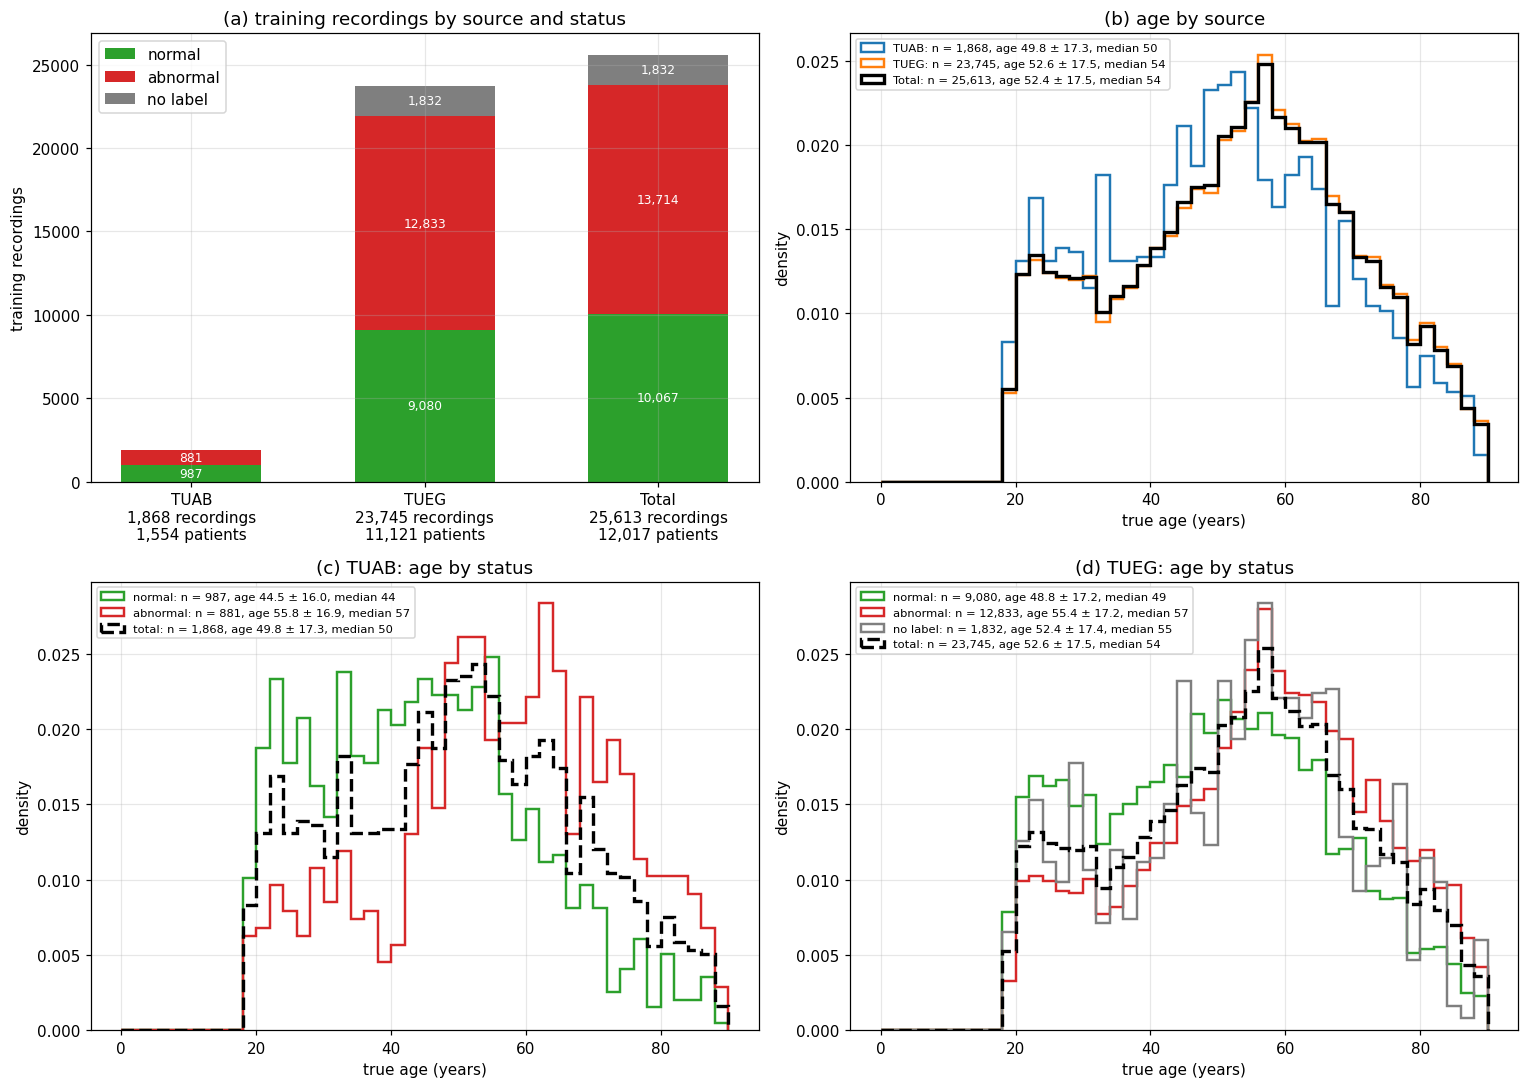

In [9]:
if HAVE_TUH and HAVE_TUEG:
    tr = pd.read_parquet(os.path.join(TUH, "cohorts/all_both_v3/cohort.parquet")).query("split == 'train'").copy()
    tr["status"] = tr.stem.map(tueg.drop_duplicates("stem").set_index("stem").status)
    tr["source"] = np.where(tr.corpora.str.contains("tuab"), "TUAB", "TUEG")
    SC = {"normal": "tab:green", "abnormal": "tab:red", "no label": "tab:gray"}
    SRC = {"TUAB": "tab:blue", "TUEG": "tab:orange", "Total": "k"}
    groups = {"TUAB": tr[tr.source == "TUAB"], "TUEG": tr[tr.source == "TUEG"], "Total": tr}

    def lab(name, d):
        return f"{name}: n = {len(d):,}, age {d.age.mean():.1f} ± {d.age.std(ddof=1):.1f}, median {d.age.median():.0f}"

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    ax = axes[0, 0]
    x = np.arange(len(groups))
    bottom = np.zeros(len(groups))
    for status, col in SC.items():
        vals = np.array([(g.status == status).sum() for g in groups.values()])
        ax.bar(x, vals, bottom=bottom, color=col, label=status, width=0.6)
        for xi, (v, b) in enumerate(zip(vals, bottom)):
            if v:
                ax.text(xi, b + v / 2, f"{v:,}", ha="center", va="center", fontsize=8, color="w")
        bottom += vals
    ax.set_xticks(x, [f"{k}\n{len(g):,} recordings\n{g.subject.nunique():,} patients" for k, g in groups.items()])
    ax.set_ylabel("training recordings")
    ax.set_title("training recordings by source and status")
    ax.legend(loc="upper left")
    bins = np.arange(0, 92, 2)
    ax = axes[0, 1]
    for name, d in groups.items():
        ax.hist(d.age, bins=bins, density=True, histtype="step", lw=2.2 if name == "Total" else 1.6,
                color=SRC[name], label=lab(name, d))
    ax.set_title("age by source")
    for ax, src_name in ((axes[1, 0], "TUAB"), (axes[1, 1], "TUEG")):
        d = groups[src_name]
        for status, col in SC.items():
            s = d[d.status == status]
            if len(s):
                ax.hist(s.age, bins=bins, density=True, histtype="step", lw=1.6, color=col, label=lab(status, s))
        ax.hist(d.age, bins=bins, density=True, histtype="step", lw=2.2, color="k", ls="--", label=lab("total", d))
        ax.set_title(f"{src_name}: age by status")
    for ax in (axes[0, 1], axes[1, 0], axes[1, 1]):
        ax.set_xlabel("true age (years)")
        ax.set_ylabel("density")
        ax.legend(fontsize=7.5, loc="upper left")
    fig.tight_layout()
    panel_labels(list(axes.ravel()))
    assert_max_columns(fig)
    plt.show()
else:
    print("TUH data volume not found: Figure 1.1 skipped.")


**TUEG, the source corpus.** Every cohort above draws from TUEG v2.0.2, the full TUH EEG corpus
(`$LABRAM_TUH_ROOT/tueg/v2.0.2`). Tables 1.6–1.13 and Figure 1.2 specify it from two files:
* the TUH recording index, one row per EDF over all TUH corpora (`index/tuh_index.parquet`,
  `dataset_maker/tuh_index.py`);
* NEDC's clinical sheet, one row per session, joined on patient + session
  (`index/nedc/metadata_v12.xlsm.xlsx`, `dataset_maker/tuh_clinical.py`).

`labram/eval/research_summary.py::tueg_recordings` builds the joined table. For a set $S$ of the
$N = |\mathrm{TUEG}|$ recordings, with recording $i$ lasting $d_i$ seconds:

$$ H(S) = \frac{1}{3600}\sum_{i\in S} d_i, \qquad \%(S) = 100\,\frac{\lvert S\rvert}{N} \tag{1.1} $$

A recording's **status** is the TUAB folder label where the recording is in TUAB. Otherwise it is
the report finding of the clinical sheet: abnormal when the sheet's "abnormal due to" field is filled.
Recordings whose session is not in the sheet have no label
(`dataset_maker/make_cohort_dataset.py::label_of`, the label the `all_both` cohorts use):

$$ \mathrm{status}_i = \begin{cases} \text{TUAB label} & i \in \mathrm{TUAB} \\
   \text{abnormal if the report gives a cause, else normal} & i \notin \mathrm{TUAB},\ \text{session in sheet} \\
   \text{no label} & \text{otherwise} \end{cases} \tag{1.2} $$

Ages are in years, from the EDF header. TUH writes 999 for patients aged 90 or older (a HIPAA
redaction), and those recordings count as age-unknown. Age statistics use the recordings with a
known age $a_i$: mean $\bar a$, sample standard deviation and quartiles $Q_1$, median, $Q_3$:

$$ \bar a = \frac{1}{n}\sum_{i=1}^{n} a_i, \qquad s_a = \sqrt{\frac{1}{n-1}\sum_{i=1}^{n}(a_i-\bar a)^2} \tag{1.3} $$

Data volume required.

### Table 1.6. TUEG at a glance: all recordings and the selected ones

One row per quantity (`rs.tueg_overview`), in two columns:
* `all TUEG`: every TUEG recording, 70,830, TUAB included;
* `selected (all_both_v3)`: the recordings the final cohort keeps, train + val + test (Tables 1.1–1.2).

Rows:
* `size`: recordings, patients, sessions and hours (Eq. (1.1)).
  * A **session** is one visit of a patient (`<patient>_sNNN`). It can hold several recordings (EDF
    files `t000`, `t001`, …), so there are more recordings than sessions.
  * The last size row splits the selected sessions into train / val / test.
* `recording`: length, year, sampling rate and montage. The year range omits a few EDF headers with
  impossible dates.
* `channels`: whether the recording has all 23 channels the models read.
* `patient`: sex and age (Eq. (1.3)), counted over recordings, so a patient with several
  recordings counts several times.

In [10]:
TUEG_INDEX = os.path.join(TUH, "index/tuh_index.parquet")
TUEG_SHEET = os.path.join(TUH, "index/nedc/metadata_v12.xlsm.xlsx")
HAVE_TUEG = os.path.exists(TUEG_INDEX) and os.path.exists(TUEG_SHEET)
if HAVE_TUEG:
    tueg = tueg if "tueg" in globals() else rs.tueg_recordings(TUEG_INDEX, TUEG_SHEET)
    final = pd.read_parquet(os.path.join(TUH, "cohorts/all_both_v3/cohort.parquet"))
    sel = tueg[tueg.stem.isin(set(final.stem))]
    t16 = pd.DataFrame({"all TUEG": rs.tueg_overview(tueg).set_index(["group", "quantity"]).value,
                        "selected (all_both_v3)": rs.tueg_overview(sel).set_index(["group", "quantity"]).value})
    per_split = " / ".join(
        f"{tueg[tueg.stem.isin(set(final.stem[final.split == s]))][['subject', 'session']].drop_duplicates().shape[0]:,}"
        for s in ("train", "val", "test"))
    row = pd.DataFrame({"all TUEG": ["–"], "selected (all_both_v3)": [per_split]},
                       index=pd.MultiIndex.from_tuples([("size", "sessions in train / val / test")]))
    k = list(t16.index).index(("size", "sessions")) + 1
    t16 = pd.concat([t16.iloc[:k], row, t16.iloc[k:]])
    t16.index.names = ["group", "quantity"]
    display(numbered_table(t16, "1.6", "TUEG at a glance: all recordings and the selected ones"))
else:
    print("TUH recording index / clinical sheet not found: set LABRAM_TUH_ROOT to show Tables 1.6-1.13.")

### Table 1.7. Subsets of TUEG

The other TUH corpora are subsets of TUEG: the same EDF files, each corpus adding its own label. One
recording can be in several of them, so the rows overlap (`rs.tueg_subsets`). The last four rows are
the subsets the brain-age cohorts select from:
* `TUEG only`: in no other corpus;
* `in the NEDC clinical sheet`: has a report status (Eq. (1.2));
* `adult age (18–89 y)`: the age range of the cohorts;
* `normative`: the pool of the `normal_*` cohorts (`dataset_maker/tuh_clinical.py::normative_mask`).

Columns:
* `label counts (recordings)`: the subset's label per category, where it is per-recording and
  categorical:
  * TUAB: normal / abnormal;
  * TUEP: epilepsy / no epilepsy, a patient-level diagnosis;
  * clinical sheet: the report finding;
  * `normative`: the status (Eq. (1.2)).
  TUSZ, TUAR and TUSL annotate *events* inside a recording (seizures, artifacts, slowing) rather than
  one category per recording; their annotation files are not on the data volume, hence "–". Age is
  numeric.
* `recordings`, `% of TUEG` and `hours` (Eq. (1.1)), and `patients`.

The `normative` subset holds 75 recordings that are report-normal but in TUAB's *abnormal* folder.
The `normal_*` cohorts drop these too (`make_cohort_dataset.py::select`). TUEV is not listed: none
of its recordings is in TUEG v2.0.2.

In [11]:
if HAVE_TUEG:
    display(numbered_table(rs.tueg_subsets(tueg).set_index("subset"), "1.7", "Subsets of TUEG", precision=1))

,label it carries,label counts (recordings),recordings,% of TUEG,patients,hours
subset,,,,,,
in TUAB,normal / abnormal (TUAB folder),"normal 1,521 / abnormal 1,472",2993,4.2,2329,1141.0
in TUSZ,seizure events,–,8140,11.5,675,1480.7
in TUEP,epilepsy / no epilepsy (patient),"epilepsy 2,244 / no epilepsy 564",2808,4.0,200,635.5
in TUAR,artifact events,–,310,0.4,213,95.2
in TUSL,slowing events,–,112,0.2,38,26.8
TUEG only,–,–,57836,81.7,13448,24024.5
in the NEDC clinical sheet,"report finding, 15 diagnosis flags, medications","report normal 26,846 / abnormal 33,426",60272,85.1,14508,24956.2
adult age (18–89 y),age,–,68077,96.1,14025,25795.6
normative,"report-normal, no neurological diagnosis, not sedated, 18–89 y","normal 14,268 / abnormal 75",14343,20.2,4773,4569.7


### Table 1.8. TUEG status labels and age per label

One row per status (Eq. (1.2)) and label source (`rs.tueg_status`):
* `TUAB folder`: TUAB's normal/abnormal label;
* `NEDC report`: the clinical sheet's finding;
* `all`: both sources;
* `total`: all of TUEG.

Columns:
* `recordings`, `% of TUEG` (Eq. (1.1));
* `patients`: a patient whose recordings differ in status counts under each status, so the rows sum to
  more than the total;
* `age n`: recordings with a known age;
* `age mean`, `age sd` (Eq. (1.3)), and `age Q1`, `age median`, `age Q3` in years.

Where TUAB and the report both label a session, they agree on about 95 % of its recordings.

In [12]:
if HAVE_TUEG:
    t15 = rs.tueg_status(tueg)
    t15 = t15[["status", "source", "recordings", "% of TUEG", "patients", "age n", "age mean", "age sd",
               "age Q1", "age median", "age Q3"]].set_index(["status", "source"])
    display(numbered_table(t15, "1.8", "TUEG status labels and age per label", precision=1))

### Figure 1.2. TUEG age distribution per status and in total

True age (years) of the TUEG recordings with a known age ($n$ = `age n` of Table 1.8), in 2-year bins,
per status (Eq. (1.2)) and for all of TUEG:
* (a) Recordings per bin, stacked by status. The stack's outline is the total.
* (b) The same distributions as densities (each integrates to 1), so their shapes compare despite the
  different group sizes. The vertical ticks mark each group's median.

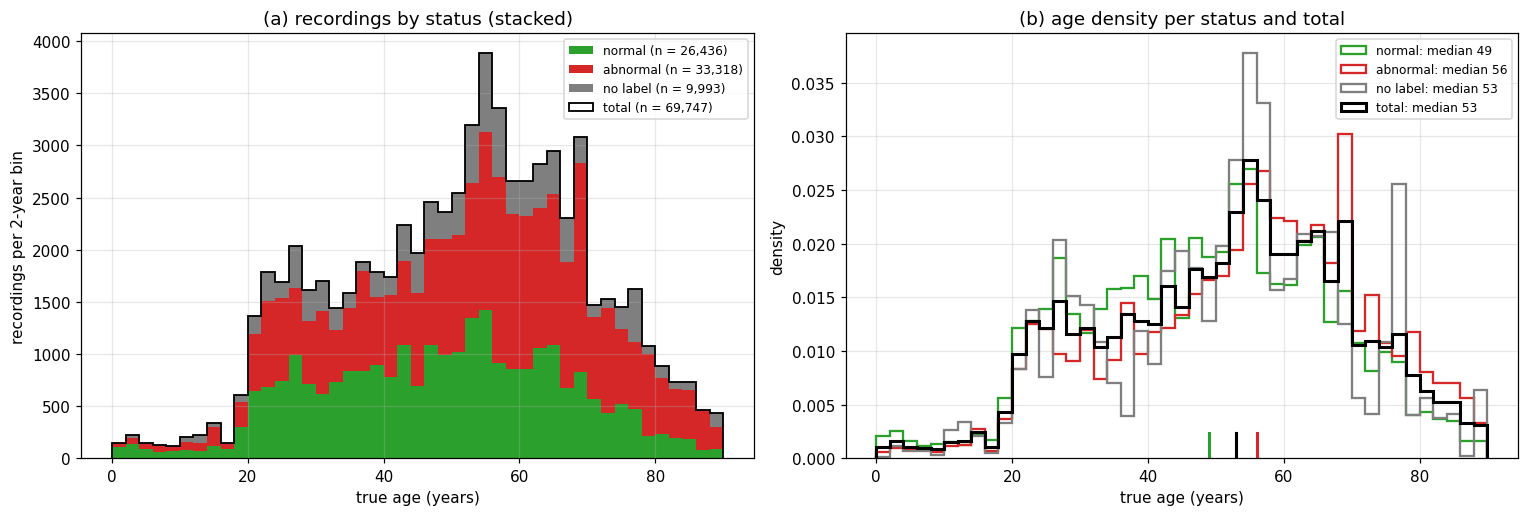

In [13]:
if HAVE_TUEG:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
    bins = np.arange(0, 92, 2)
    colors = {"normal": "tab:green", "abnormal": "tab:red", "no label": "tab:gray", "total": "k"}
    groups = {s: tueg.age[tueg.status == s].dropna() for s in rs.STATUS}
    axes[0].hist([groups[s] for s in rs.STATUS], bins=bins, stacked=True, color=[colors[s] for s in rs.STATUS],
                 label=[f"{s} (n = {len(groups[s]):,})" for s in rs.STATUS])
    axes[0].hist(tueg.age.dropna(), bins=bins, histtype="step", color="k", lw=1.2,
                 label=f"total (n = {tueg.age.notna().sum():,})")
    axes[0].set_xlabel("true age (years)")
    axes[0].set_ylabel("recordings per 2-year bin")
    axes[0].legend(fontsize=8)
    axes[0].set_title("recordings by status (stacked)")
    groups["total"] = tueg.age.dropna()
    for s, a in groups.items():
        axes[1].hist(a, bins=bins, density=True, histtype="step", lw=2.0 if s == "total" else 1.5,
                     color=colors[s], label=f"{s}: median {a.median():.0f}")
        axes[1].axvline(a.median(), ymin=0, ymax=0.06, color=colors[s], lw=2)
    axes[1].set_xlabel("true age (years)")
    axes[1].set_ylabel("density")
    axes[1].legend(fontsize=8)
    axes[1].set_title("age density per status and total")
    fig.tight_layout()
    panel_labels(axes)
    assert_max_columns(fig)
    plt.show()

### Table 1.9. TUEG diagnosis flags

The clinical sheet's 15 diagnosis flags and two derived flags over the TUEG recordings in the sheet,
most frequent first (`rs.tueg_diagnoses`):
* `any neurological diagnosis`: seizure (clinical or electrographic), epilepsy, stroke, Parkinson's,
  Alzheimer's, TBI, dementia or MS;
* `sedating medication`: an anaesthetic, benzodiazepine, barbiturate or opioid on the medication list.

**How the flags relate to the status label.** Table 1.10 gives where each field comes from, and
Table 1.11 explains, per kind of flag, why a flagged recording is not necessarily abnormal. The flags are **not** the abnormal label, and they are
**not one-hot**:
* **Independent of the status.** Each flag is the patient's diagnosis as recorded in the clinical
  sheet. The normal / abnormal status (Eq. (1.2)) is the neurologist's reading of *this* EEG. A flagged
  recording can be normal: an epilepsy patient often has a normal EEG between seizures. The `normal` /
  `abnormal` columns show the split for every flag, and many abnormal recordings carry no flag at all
  (Table 1.12).
* **Multi-hot.** Every flag is its own yes/no column, so a recording can carry several at once, or
  none (Table 1.12). The condition vector of the `path_label` runs (Eq. (3.6)) encodes them the same way.

Columns:
* `recordings` and `patients` with the flag;
* `normal` / `abnormal`: those recordings by status (Eq. (1.2));
* `% of sheet`: Eq. (1.1) relative to the sheet's recordings instead of $N$;
* `age mean`: Eq. (1.3), in years;
* `% abnormal`: the share with status abnormal (Eq. (1.2)).

The last row, **Total**, counts every TUEG recording in the sheet, flagged or not. The flags are
multi-hot and many recordings carry none, so the flag rows do not add up to it.

The 14 pathology groups of the condition vector (Eq. (3.6)) come from these flags.

In [14]:
if HAVE_TUEG:
    display(numbered_table(rs.tueg_diagnoses(tueg).set_index("flag"), "1.9", "TUEG diagnosis flags", precision=1))

,recordings,patients,normal,abnormal,% of sheet,age mean,% abnormal
flag,,,,,,,
sedating medication,23067,4727,9135,13932,38.3,52.3,60.4
any neurological diagnosis,11560,1736,3901,7659,19.2,51.1,66.3
Clinical seizure,6980,1092,2922,4058,11.6,48.5,58.1
Epilepsy,4660,306,1991,2669,7.7,47.0,57.3
Electrographic seizure,3015,66,328,2687,5.0,54.5,89.1
Stroke,2590,539,405,2185,4.3,61.3,84.4
Substance abuse / dependence,2083,725,592,1491,3.5,45.7,71.6
TBI,720,202,147,573,1.2,48.6,79.6
Bipolar disorder,502,240,243,259,0.8,42.7,51.6


### Table 1.10. Where the labels come from

Every status and flag in this notebook comes from human-written clinical records. None is computed
from the EEG signal by an algorithm; the only signal-derived features in the repo are our own
(`labram/features/`). The NEDC sheet (`metadata_v12`, sheet `TUEG`, one row per session) has review
columns (`Reviewed spell check`, `Reviewed medication`, `Reviewed abnormal due`), so NEDC staff
evidently extracted its fields from each session's EEG report and reviewed them. The documentation on
disk does not state this explicitly.

| field | where it comes from | what it describes | level |
|---|---|---|---|
| status, TUAB recordings | TUAB's normal / abnormal folders | the neurologist's reading of this EEG: the report's impression, curated into TUAB | recording |
| status, other TUEG recordings | NEDC sheet `abnormal due to`: filled = abnormal, empty = normal; session not in the sheet = no label | the neurologist's reading of this EEG, i.e. why the report calls it abnormal | session (its recordings share it) |
| diagnosis flags (15) | NEDC sheet, one yes/no column per diagnosis | the patient's clinical background (history, reason for the EEG), not the EEG | session |
| medications | NEDC sheet `Major Medications` | drugs the patient was taking | session |
| FIRDA / OIRDA / TIRDA / GPD / LPD | NEDC sheet | EEG patterns the neurologist saw in the signal: signal findings, read by a human | session |

A clinical EEG report usually holds both kinds of information:
* **the clinical history and medications**, from the referral: the source of the diagnosis flags;
* **the neurologist's description and impression of the recording**: the source of the status.

The two can therefore disagree: a patient with epilepsy in the history can have a normal EEG
(Table 1.11).

### Table 1.11. Why a diagnosis flag is not always abnormal

A flag describes the patient. The status describes whether *this* 20–30-minute EEG shows a specific
abnormality (slowing, epileptiform discharges, asymmetry). `% abnormal` is the share of the flag's
recordings with status abnormal (Table 1.9).

| kind of flag | % abnormal | why |
|---|---|---|
| **EEG findings and dementias**: electrographic seizure, Alzheimer's, dementia | 89, 98, 79 | Electrographic seizures are seen on the EEG itself. Dementia causes persistent diffuse slowing. Alzheimer's comes from only 6 patients. |
| **structural brain injury**: stroke, TBI | 84, 80 | A lesion shows on the EEG when it is large or cortical. Small, deep or old lesions can leave a normal EEG. |
| **episodic conditions**: epilepsy, clinical seizure | 57, 58 | Seizures come and go. Between seizures, a single routine EEG of an epilepsy patient is often normal. "Clinical seizure" also covers events that turned out non-epileptic (e.g. syncope or psychogenic attacks). |
| **substance use**: substance abuse / dependence | 72 | Intoxication, withdrawal and the drugs given for them can slow or otherwise change the EEG. |
| **psychiatric / developmental**: depression, schizophrenia, anxiety, ADHD, bipolar | 36, 32, 40, 40, 52 | These conditions usually do not change the resting EEG. When it is abnormal, medication or another condition is a frequent cause. |
| **other**: multiple sclerosis, Parkinson's | 46, 22 | MS lesions lie mostly in white matter, and the EEG is often normal. Parkinson's has only 9 recordings. |

Two further reasons the match is loose:
* **Different levels.** The flags are per session, while the status comes from TUAB's label for TUAB
  recordings and from the report otherwise.
* **Noisy labels.** Both are noisy clinical records. TUAB's label and the report finding disagree on
  about 5 % of shared recordings (Table 1.8).

### Table 1.12. Diagnosis flags per recording

How many of the 15 diagnosis flags each TUEG recording in the clinical sheet carries
(`rs.flags_per_recording`), with those recordings by status (Eq. (1.2)) and as a share of the sheet's
recordings. A count above 1 shows that the flags are multi-hot. The count-0 row shows how many normal
and abnormal recordings have no recorded diagnosis.

In [15]:
if HAVE_TUEG:
    display(numbered_table(rs.flags_per_recording(tueg), "1.12", "Diagnosis flags per recording", precision=1))

,recordings,normal,abnormal,% of sheet
diagnosis flags per recording,,,,
0,46407,22102,24305,77.0
1,8307,2799,5508,13.8
2,3582,1404,2178,5.9
3,1624,338,1286,2.7
4,316,99,217,0.5
5,33,33,0,0.1
6,3,0,3,0.0


### Table 1.13. Shared diagnosis flags and status: pairwise counts

Over the 60,272 TUEG recordings in the clinical sheet, entry (row, column) is the number of recordings
that carry **both** the row's and the column's item (`rs.flag_matrix`). The items are the status
(`normal`, `abnormal`, Eq. (1.2)) and the 15 diagnosis flags, most frequent first. The diagonal is each
item's total (Table 1.9). The matrix is symmetric. `normal` × `abnormal` is 0, because a recording has
one status. Flag names are shortened: `el.` / `cl. seizure` = electrographic / clinical seizure,
`substance` = substance abuse or dependence, `MS` = multiple sclerosis.

In [16]:
if HAVE_TUEG:
    fm = rs.flag_matrix(tueg)
    display(numbered_table(fm, "1.13", "Shared diagnosis flags and status: pairwise counts", precision=0))

,normal,abnormal,cl. seizure,epilepsy,el. seizure,stroke,substance,TBI,bipolar,dementia,depression,schizophrenia,anxiety,Alzheimer's,MS,ADHD,Parkinson's
normal,26775,0,2922,1991,328,405,592,147,243,62,137,130,110,3,58,47,7
abnormal,0,33497,4058,2669,2687,2185,1491,573,259,231,76,61,72,163,50,31,2
cl. seizure,2922,4058,6980,3222,1486,676,324,200,27,61,58,63,90,1,0,2,0
epilepsy,1991,2669,3222,4660,1660,510,104,60,7,46,37,99,43,0,0,0,0
el. seizure,328,2687,1486,1660,3015,549,18,27,9,153,1,77,0,153,0,0,0
stroke,405,2185,676,510,549,2590,81,134,32,43,7,91,17,0,0,0,0
substance,592,1491,324,104,18,81,2083,41,41,2,57,9,67,0,5,3,0
TBI,147,573,200,60,27,134,41,720,2,1,4,0,4,0,4,1,0
bipolar,243,259,27,7,9,32,41,2,502,0,7,19,12,0,4,5,0
dementia,62,231,61,46,153,43,2,1,0,293,2,6,2,160,0,0,0


### Figure 1.3. Shared diagnosis flags and status: share of the row

The counts of Table 1.13 as shares of the row's total:

$$ s(a, b) = 100\,\frac{n(a \wedge b)}{n(a)} \tag{1.4} $$

where $n(a \wedge b)$ is the number of recordings carrying both $a$ and $b$. Read along a row: for
example, the `epilepsy` row gives the % of epilepsy recordings that are normal, abnormal, or also carry
each other flag. The matrix is not symmetric, because rows are normalized by their own totals. Cells
are annotated with the rounded %. The diagonal is 100 %.

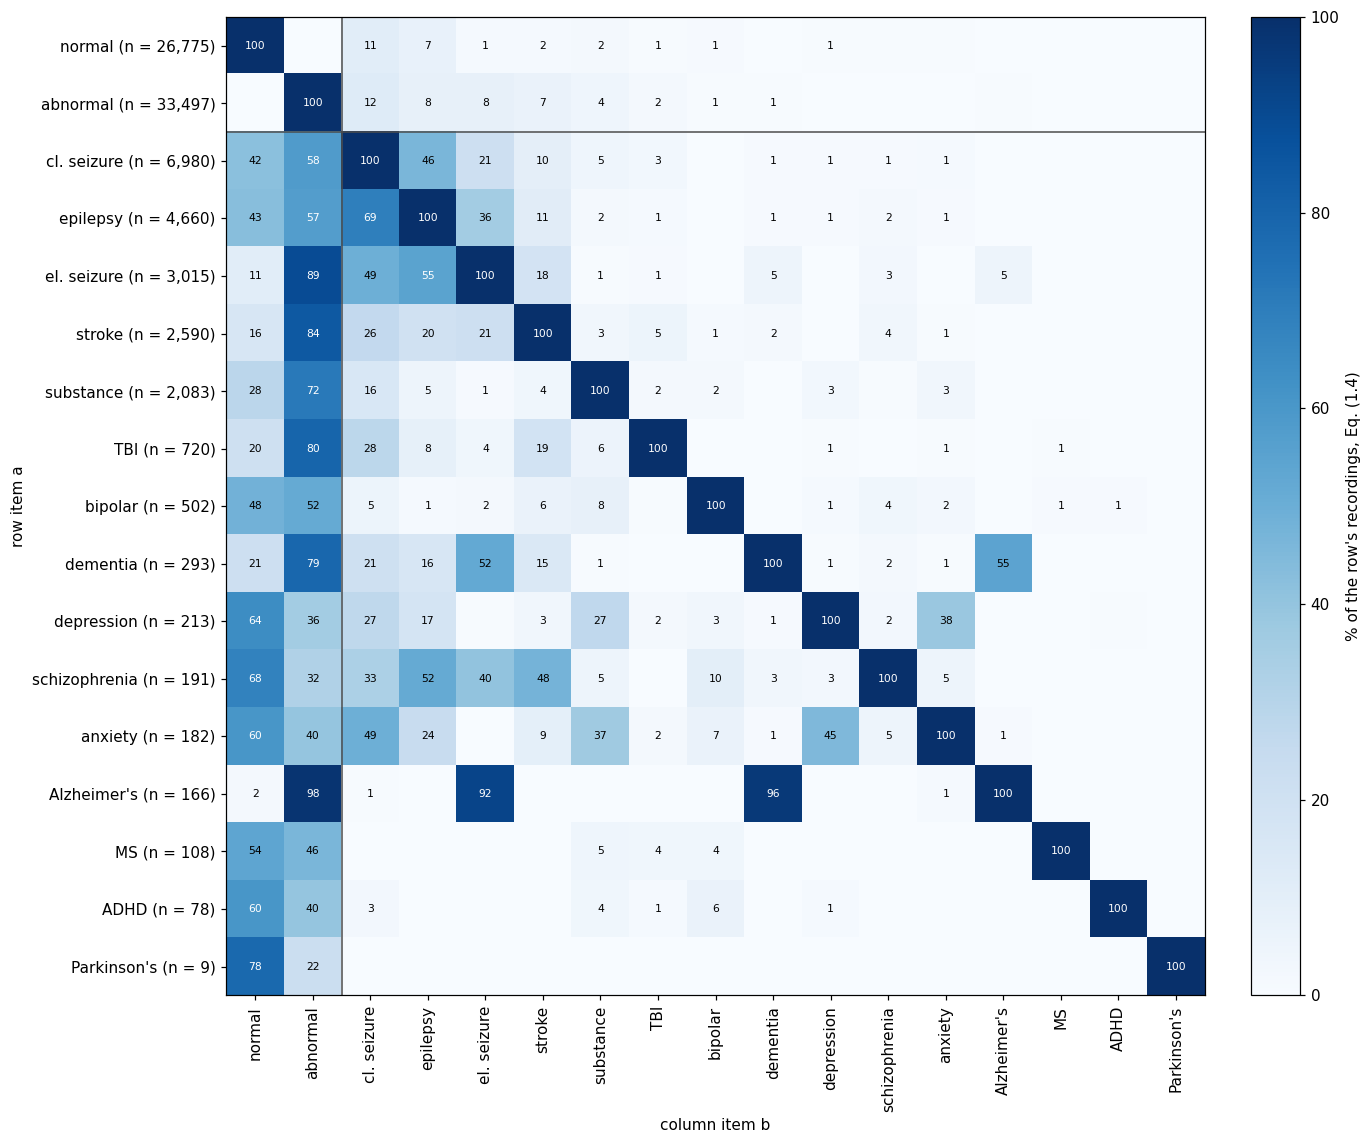

In [17]:
if HAVE_TUEG:
    share = 100 * fm.div(pd.Series(np.diag(fm), index=fm.index), axis=0)
    fig, ax = plt.subplots(figsize=(12.5, 10.5))
    im = ax.imshow(share.to_numpy(), cmap="Blues", vmin=0, vmax=100)
    ax.set_xticks(range(len(share)), share.columns, rotation=90)
    ax.set_yticks(range(len(share)), [f"{r} (n = {fm.loc[r, r]:,})" for r in share.index])
    for r in range(len(share)):
        for c in range(len(share)):
            v = share.iat[r, c]
            if v >= 0.5:
                ax.text(c, r, f"{v:.0f}", ha="center", va="center", fontsize=7, color="w" if v > 55 else "k")
    for k in (1.5,):
        ax.axhline(k, color="0.3", lw=1)
        ax.axvline(k, color="0.3", lw=1)
    ax.grid(False)
    ax.set_xlabel("column item b")
    ax.set_ylabel("row item a")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="% of the row's recordings, Eq. (1.4)")
    fig.tight_layout()
    assert_max_columns(fig)
    plt.show()

### Figures 1.4–1.5. Age per diagnosis flag

True age (years) of the TUEG recordings in the clinical sheet that carry each flag. Each panel is a
histogram in 5-year bins, stacked by status: green normal, red abnormal. Its title gives the number of
recordings and patients and the median age.

Counts are **recordings**, and the title gives the patients. A spike usually means one or a few
patients recorded many times: electrographic seizure has 46 recordings per patient on average.
Recordings with an unknown age are left out, so `n` can be slightly below Table 1.9.
* Figure 1.4: the neurological flags, panels (a)–(i), and (j) the recordings with **no** diagnosis
  flag as a reference.
* Figure 1.5: the psychiatric and other flags, panels (a)–(f).

In [18]:
FLAG_GROUPS = {
    "1.4": ("neurological flags", ["dx_electrographic_seizure", "dx_clinical_seizure", "dx_epilepsy", "dx_stroke",
                                   "dx_tbi", "dx_dementia", "dx_alzheimers", "dx_parkinsons", "dx_ms", None]),
    "1.5": ("psychiatric and other flags", ["dx_substance", "dx_bipolar", "dx_depression", "dx_schizophrenia",
                                            "dx_anxiety", "dx_adhd"]),
}


def flag_age_figure(number):
    title, cols = FLAG_GROUPS[number]
    sheet = tueg[tueg.in_sheet]
    flagged = sheet[list(rs.FLAG_SHORT)].fillna(False).astype(bool)
    rows = (len(cols) + 1) // 2
    fig, axes = plt.subplots(rows, 2, figsize=(12.5, 2.8 * rows), sharex=True)
    bins = np.arange(0, 96, 5)
    for ax, col in zip(axes.ravel(), cols):
        m = ~flagged.any(axis=1) if col is None else flagged[col]
        d = sheet[m & sheet.age.notna()]
        ax.hist([d.age[d.status == "normal"], d.age[d.status == "abnormal"]], bins=bins, stacked=True,
                color=["tab:green", "tab:red"], label=["normal", "abnormal"])
        name = "no diagnosis flag" if col is None else rs.FLAG_SHORT[col]
        ax.set_title(f"{name}: n = {len(d):,} ({d.subject.nunique():,} patients), median {d.age.median():.0f} y",
                     fontsize=9)
        ax.set_ylabel("recordings")
        ax.legend(fontsize=7)
    for ax in axes.ravel()[len(cols):]:
        ax.remove()
    for ax in axes[-1]:
        ax.set_xlabel("true age (years)")
    fig.tight_layout()
    panel_labels([a for a in axes.ravel()[:len(cols)]])
    assert_max_columns(fig)
    plt.show()

#### Figure 1.4. Age per diagnosis flag: neurological flags

As described above; panels (a)–(i) one neurological flag each, (j) recordings with no flag.

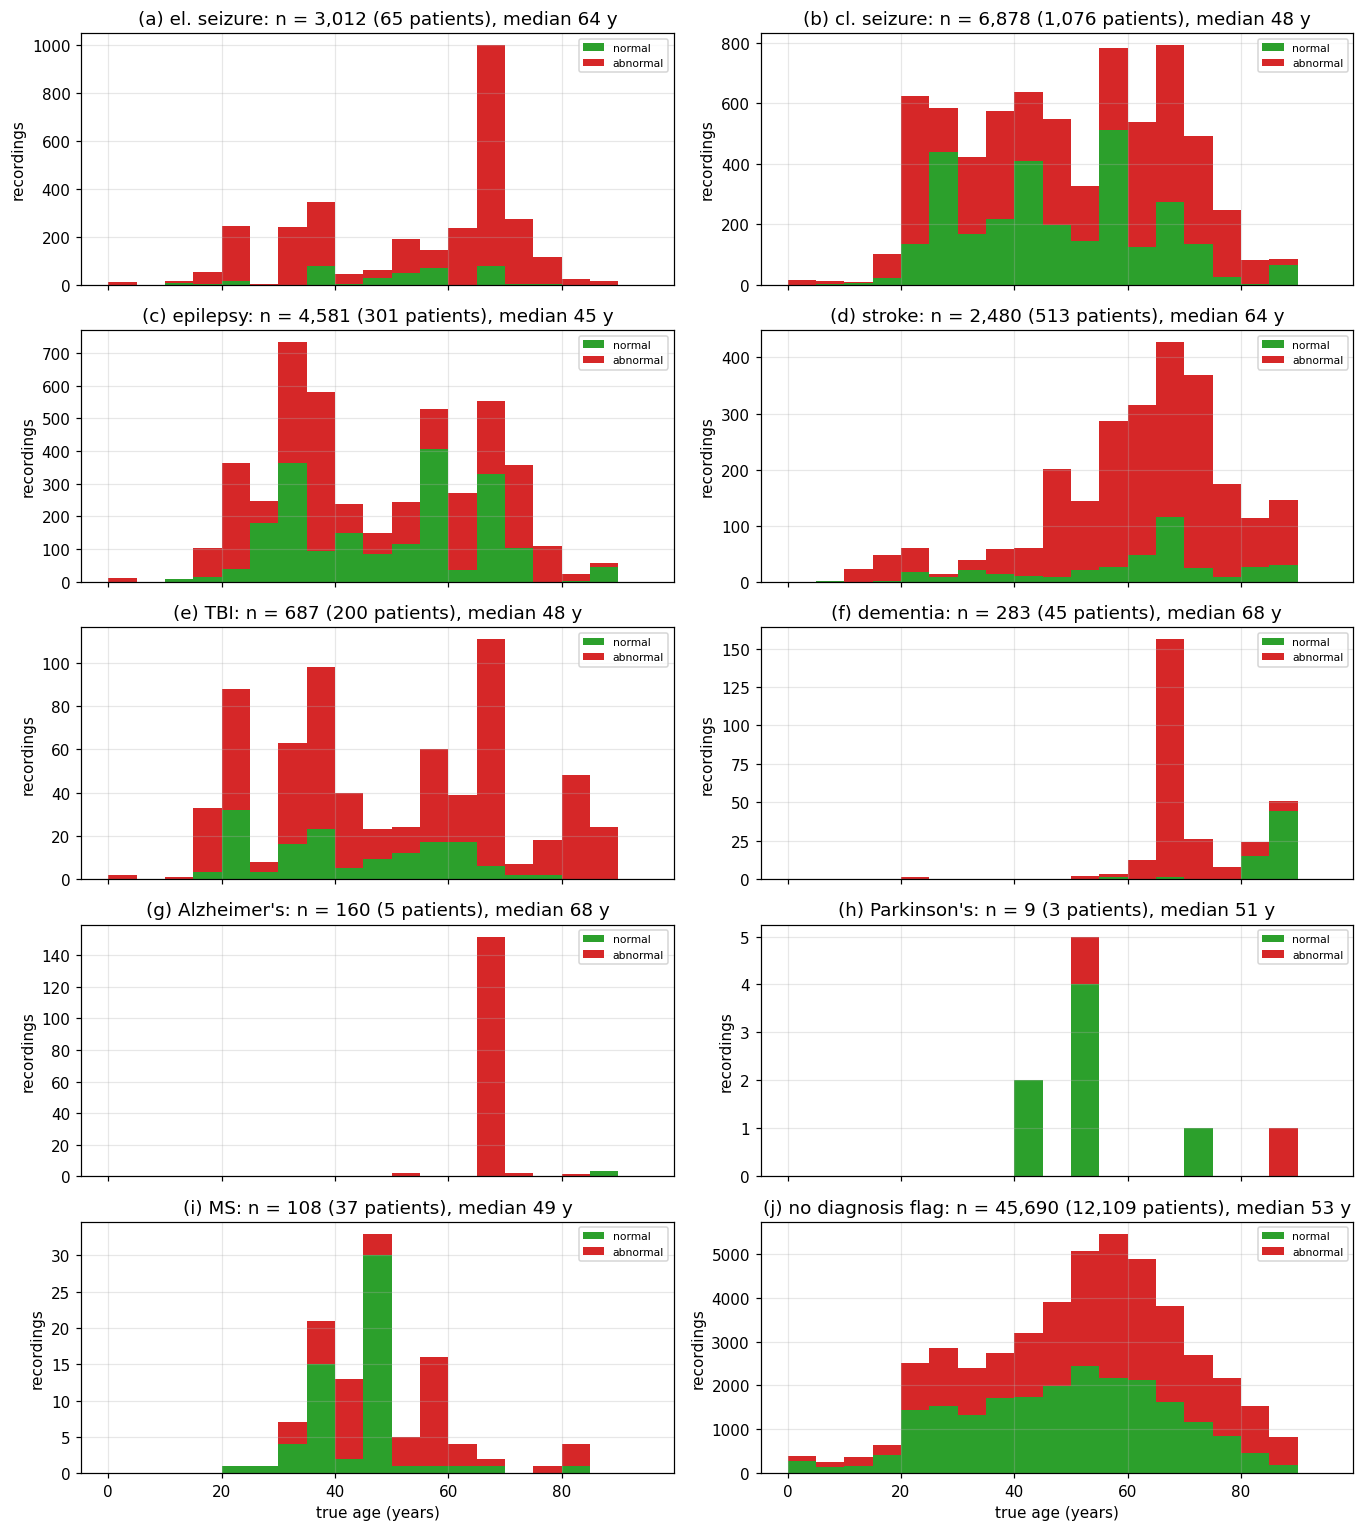

In [19]:
if HAVE_TUEG:
    flag_age_figure("1.4")

#### Figure 1.5. Age per diagnosis flag: psychiatric and other flags

As described above; panels (a)–(f) one flag each.

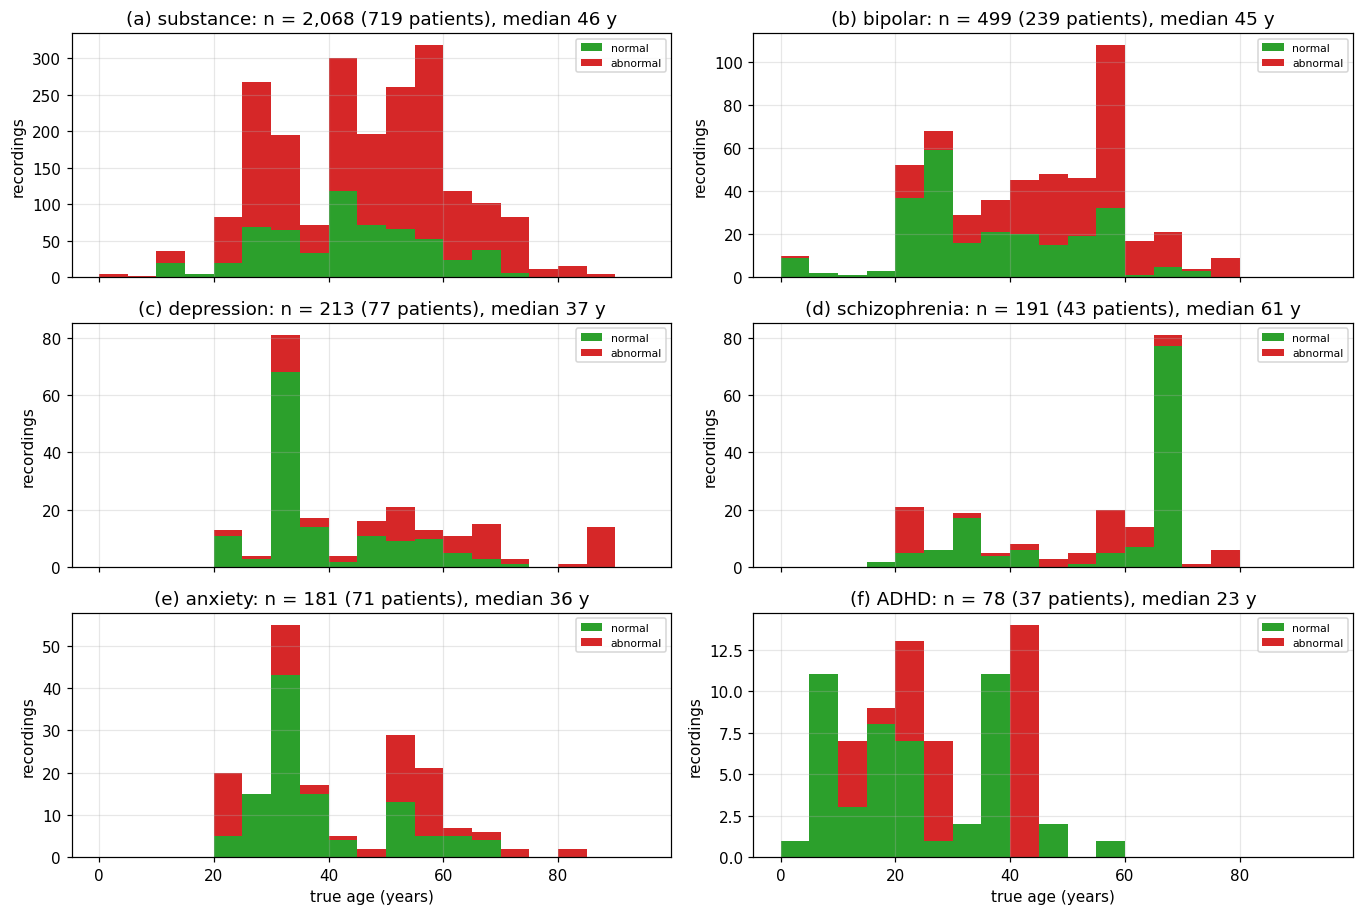

In [20]:
if HAVE_TUEG:
    flag_age_figure("1.5")

**Reading Table 1.13 and Figures 1.3–1.5.**
* **Seizure flags cluster.** 69 % of epilepsy recordings are also flagged clinical seizure, and 55 % of
  electrographic-seizure recordings are also flagged epilepsy. The three flags describe one patient
  group from different angles: the diagnosis, the reported event and the EEG finding.
* **Status follows the kind of flag** (the `normal` / `abnormal` columns of Figure 1.3, as in
  Table 1.9). Electrographic seizure, Alzheimer's and stroke are mostly abnormal. Psychiatric flags are
  mostly normal.
* **Small flags come from few patients.** Alzheimer's has 166 recordings from 6 patients. Almost all of
  them also carry dementia (160) and electrographic seizure (153), so its co-occurrences describe those
  6 patients rather than Alzheimer's disease in general (Table 1.9 gives patients per flag).
* **Psychiatric flags overlap each other,** and in this hospital population often co-occur with
  neurological flags too. 38 % of depression recordings also carry anxiety. Schizophrenia recordings
  carry epilepsy in 52 % and stroke in 48 % of cases, and anxiety recordings carry clinical seizure in
  49 %. Few patients carry each psychiatric flag, so these shares rest on few patients.
* **Age differs strongly by flag** (Figures 1.4–1.5). Dementia and Alzheimer's sit at 65–90 years,
  and stroke and electrographic seizure peak in the 60s. ADHD sits mostly under 40 (median 23).
  Epilepsy, clinical seizure, bipolar and substance use are spread over adulthood.
* **Abnormal versus normal age within a flag.** For 10 of the 15 flags the abnormal recordings are
  older (median), most clearly for depression (55 vs 33), anxiety (50 vs 31) and bipolar (52 vs 32).
  Epilepsy is the opposite (37 vs 50), and so is schizophrenia (58 vs 66). Stroke shows no difference.
  Dementia and Alzheimer's have their normal recordings at the oldest ages, from a handful of patients.


**Reading Tables 1.6–1.13 and Figure 1.2.**
* **Size:** TUEG holds about 70.8k recordings (27k hours) of about 15k patients. The cohorts use 25k–29k
  of them, after the age, length, channel and per-patient rules of Table 1.3.
* **Recordings per patient:** most patients have a single recording, but a few long-monitored patients
  have hundreds. This is why the cohorts cap train/val recordings per patient and every split is by
  patient.
* **Labels:** only 4 % of TUEG is in TUAB. The status of nearly all other recordings comes from the NEDC
  report: about half are abnormal, and 14 % have no label (Table 1.8).
* **Age:** abnormal recordings are older than normal ones by about 5 years in mean and 7 in median
  (Table 1.8, Figure 1.2(b)). A model trained on mixed statuses can therefore partly read age from
  pathology, which is one reason Section 5 reports normal and abnormal test recordings separately.

## 2. Experiments

**Phase 1 (TUAB only)** starts from scenario **D**, the default `finetune_tuab_age.json` (Table 2.1
lists how it differs from LaBraM's own fine-tuning recipe):
* LaBraM-base with a **common average reference (CAR)** on the input (Eq. (3.1));
* Huber loss on the z-scored age;
* lr $10^{-4}$, 15 epochs.

**CAR** re-references the EEG. At every time sample it subtracts the mean over all channels from each
channel, so every channel is measured against the average of all electrodes instead of the recording's
own reference. This removes what all electrodes share: the activity of the reference electrode(s) and
noise common to every channel. It also puts the two TUH montages on one reference, average reference
(`tcp_ar`, about 80 % of the recordings) and linked ears (`tcp_le`). LaBraM as published feeds the
signal on each recording's own reference. CAR is the only part of the LaBraM++ input block D uses: there is no per-patch
z-scoring (Table 2.1). In Table 5.2, row P1 tests it.

**E2** shortens it to 4 epochs / 1 warmup epoch, and **M1** = E2 + mixup $\alpha = 0.4$. Every
**phase-2** run is M1 plus the change named in its row (`labram/eval/research_summary.py::M1`).
**Phase 3** cross-validates the three strongest phase-2 configurations.

**Loss.** Every run trains on a loss from the family of Eqs. (2.1)–(2.11) below, and Tables 2.2, 2.5 and 2.7 name
each run's loss in their `loss` column.

**ClearML.** Tables 2.2, 2.5, 2.6, 2.7 and 2.9 link every run to its ClearML experiment; the link text is the
experiment's name in ClearML (`docs/data/brain_age_clearml_runs.csv`, written from the ClearML server
by `labram/eval/research_summary.py::fetch_clearml_runs`). A CV run links to the ClearML project that
holds its five fold experiments.

### Table 2.1. Base configuration D versus the LaBraM fine-tuning recipe

Every configuration field on which LaBraM's TUAB fine-tuning recipe as published and the base
configuration D differ:
* `LaBraM paper`: `labram/configs/defaults/finetune_tuab_paper.json`, the normal/abnormal fine-tune of
  LaBraM-base from the paper and the README;
* `D`: `labram/configs/defaults/finetune_tuab_age.json` as is, without overrides.

Both are rebuilt by `rs.resolve_config` and compared by `labram/eval/research_summary.py::config_diff`.
Excluded:
* bookkeeping fields (paths, logging, infrastructure);
* classification-only fields a regression run never reads (`INERT_FOR_REGRESSION`, e.g. label smoothing);
* fields of a section that is off in both.

`group` is the part of the pipeline and `meaning` what the change does. Every other field is the
paper's: LaBraM-base from `labram-base.pth`, batch 64, AdamW with weight decay 0.05, layer decay 0.65,
drop path 0.1, mean pooling, cosine schedule. Changes that live in the data rather than the
configuration (mains-interference removal, splits, labels) are in Table 4.2; how the best configuration
differs from the paper's recipe is Table 4.1.

In [21]:
BASE_MEANING = {
    "data.dataset": ("task", "age regression on TUAB (age from the EDF header) instead of normal/abnormal"),
    "model.task": ("task", "scalar regression head, Huber loss on the z-scored age (Eqs. (3.2), (3.4))"),
    "data.data_format": ("data", "storage only: one float32 npy per recording, windows bit-identical to the pickles"),
    "labram_plus.enabled": ("input", "LaBraM++ input block on: common average reference, CAR (Eq. (3.1))"),
    "labram_plus.z_score_patches": ("input", "LaBraM++ block with CAR only, no per-patch z-scoring"),
    "data.trim_start_sec": ("windows", "drop the first 60 s of every recording"),
    "data.trim_end_sec": ("windows", "drop the last 60 s of every recording"),
    "data.eval_minutes": ("windows", "score each recording on its first 5 minutes after the trim"),
    "evaluation.agg_windows": ("scoring", "one prediction per recording = mean of its windows (Eq. (3.7))"),
    "optimizer.lr": ("optimizer", "peak lr 1e-4 instead of 5e-4"),
    "optimizer.warmup_epochs": ("schedule", "2 warmup epochs instead of 5"),
    "trainer.epochs": ("schedule", "15 epochs instead of 50"),
}
base_d = rs.resolve_config(AGE_JSON)
paper = rs.resolve_config(PAPER_JSON)
t2_1 = rs.config_diff(paper, base_d, ("LaBraM paper", "D"), ignore=rs.NON_SCIENTIFIC + rs.INERT_FOR_REGRESSION)
missing = sorted(set(t2_1.field) - set(BASE_MEANING))
assert not missing, f"annotate these fields in BASE_MEANING: {missing}"
t2_1["group"] = t2_1.field.map(lambda f: BASE_MEANING[f][0])
t2_1["meaning"] = t2_1.field.map(lambda f: BASE_MEANING[f][1])
order = ["task", "data", "input", "windows", "scoring", "optimizer", "schedule"]
t2_1 = t2_1.sort_values("group", key=lambda g: g.map(order.index), kind="stable").set_index(["group", "field"])
numbered_table(t2_1, "2.1", "Base configuration D versus the LaBraM fine-tuning recipe")

**Loss functions.** The loss is what the optimizer minimizes on every training batch. LaBraM as
published fine-tunes TUAB as a binary normal/abnormal classifier. The head emits one logit $s$ per
window with label $c \in \{0, 1\}$, and the loss is the binary cross-entropy (`nn.BCEWithLogitsLoss`,
`labram/losses/classification.py`):

$$ \ell_{\mathrm{BCE}}(s, c) = -\big[c \log \sigma(s) + (1-c)\log(1-\sigma(s))\big], \qquad \sigma(s) = \frac{1}{1+e^{-s}} \tag{2.1} $$

For brain age the head instead emits a scalar $\hat z$ per 10 s window. The target is the z-scored age
$z = (y-\mu)/\sigma$ (Eq. (3.2), with $\mu$ and $\sigma$ from the training windows). The batch loss
averages a per-window loss $\ell$ of the residual over the $B$ windows of the batch
(`labram/losses/regression.py::build_regression_criterion`):

$$ \mathcal L = \frac{1}{B}\sum_{b=1}^{B} \ell(r_b), \qquad r_b = \hat z_b - z_b \tag{2.2} $$

**Per-window loss.** The default for D and every later run unless stated otherwise is the **Huber**
loss with $\delta = 1$. It is quadratic for small residuals and linear for large ones, so a few
recordings with a wrong or extreme age do not dominate the gradient. DX2 uses $\delta = 2$:

$$ \ell_\delta(r) = \begin{cases} \tfrac12 r^2 & \lvert r\rvert \le \delta \\ \delta\,(\lvert r\rvert - \tfrac12\delta) & \text{otherwise} \end{cases} \tag{2.3} $$

D2 uses the **L1** loss, the absolute error, which directly matches the MAE of Eq. (0.1):

$$ \ell_1(r) = \lvert r\rvert \tag{2.4} $$

**Mixup (M1 and every phase-2 run).** Each window $b$ of a batch is blended with a partner window
$\pi(b)$ drawn from the same batch, usually from another recording with a different age. $\pi$
permutes the **samples of the batch** (`torch.randperm` over the batch dimension), not the channels.
The two windows are averaged point by point, channel with the same channel and time sample with the
same time sample, and their targets with the same weight. For example, $\lambda = 0.7$ blends a
30-year-old's window with a 70-year-old's into target $0.7 \cdot 30 + 0.3 \cdot 70 = 42$. One
$\lambda \sim \mathrm{Beta}(0.4, 0.4)$ is drawn per batch, usually near 0 or 1, so one window dominates. The loss
of Eq. (2.2) is computed on the blended targets (`labram/train/mixup.py::mixup_batch`). A channel
missing from either partner (T1/T2 in the `channel_drop` runs) is zeroed rather than blended:

$$ \bar x_b = \lambda x_b + (1-\lambda)\,x_{\pi(b)}, \qquad \bar z_b = \lambda z_b + (1-\lambda)\,z_{\pi(b)} \tag{2.5} $$

Plain mixup draws the partner $\pi(b)$ uniformly at random. **C-Mixup** (M1c) prefers partners of similar
age, so the blended target stays plausible. With $\sigma_m = 5$ years:

$$ P\big(\pi(b) = j\big) \propto \exp\!\Big(-\frac{(y_b - y_j)^2}{2\sigma_m^2}\Big), \quad j \ne b \tag{2.6} $$

**Soft labels (M4).** The head emits a softmax $p_k$ over age bins with centres $c_k$ = 1, 2, …, 89 years.
The target is a Gaussian $q_k$ around the true age with $\sigma_s = 2.5$ years, the loss is the KL
divergence, and the prediction is the expected age (`SoftLabelRegressionLoss`). Centres and $\sigma_s$ are
z-scored like $z$:

$$ \begin{aligned} q_k &= \frac{\exp\!\big(-(c_k - z)^2 / 2\sigma_s^2\big)}{\sum_{k'}\exp\!\big(-(c_{k'} - z)^2 / 2\sigma_s^2\big)}, \qquad \ell_{\mathrm{KL}} = \sum_k q_k \log\frac{q_k}{p_k}, \\ \hat z &= \sum_k p_k\, c_k \end{aligned} \tag{2.7} $$

**Age-balanced loss (B1, B2).** Rare ages (children, the very old) are up-weighted.
$\rho_k$ is the density of training windows in 1-year age bin $k$, smoothed by a Gaussian with
$\sigma = 2$ years. The weight is $\rho^{-1/2}$ (B1) or $\rho^{-1}$ (B2), capped at 10× the smallest weight and
normalized to mean 1 over the training windows (`age_balance_weights`, `BalancedRegressionLoss`):

$$ \mathcal L = \frac{1}{B}\sum_{b} w_{k(y_b)}\,\ell_\delta(r_b), \qquad w_k \propto \rho_k^{-1/2}\ \text{or}\ \rho_k^{-1} \tag{2.8} $$

**Codebook regularization: the spectral reconstruction and quantization terms (DX1, DX4, DX4b
only).** LaBraM's tokenizer (VQNSP) was pre-trained to encode each 1 s patch into a codeword and to
decode from it the patch's Fourier amplitude and phase. These runs reuse its quantizer and decoder,
frozen, on top of the fine-tuned encoder. Extra loss terms then penalize the encoder if its patch tokens
drift away from what the frozen decoder can read back (`model.codebook_reg`,
`labram/losses/codebook_regularized.py`). The age head still reads the mean patch token, as in D.

For each patch token $n$ (one channel × one 1 s patch of 200 samples):
* $\tilde A_{n,k}$: the std-normalized FFT amplitude of the patch at frequency bin $k$ (bin $k$ = $k$ Hz);
* $\hat A_{n,k}$: the decoder's reconstruction of it;
* $h_n$: the encoder token;
* $e_n$: its nearest codeword; $\mathrm{sg}$ is stop-gradient.

The terms are averaged over all tokens (and bins or feature dimensions) of the batch:

$$ \begin{aligned} \mathcal L &= \mathcal L_\delta + w_A\,\mathcal L_{\mathrm{amp}} + w_P\,\mathcal L_{\mathrm{phase}} + w_Q\,\mathcal L_{\mathrm{q}}, \\ \mathcal L_{\mathrm{amp}} &= \operatorname{mean}_{n,\,k \le K}\big(\hat A_{n,k} - \tilde A_{n,k}\big)^2, \\ \mathcal L_{\mathrm q} &= \beta_q\,\operatorname{mean}_{n}\,\big(\mathrm{sg}(e_n) - h_n\big)^2, \qquad \beta_q = 1 \end{aligned} \tag{2.9} $$

$\mathcal L_{\mathrm{phase}}$ is the same MSE on the std-normalized FFT phase. $K$ is the number of
frequency bins kept: `loss.freq_fraction` × 200. The weights each run used, from its ClearML
configuration (`model.codebook_reg.*_weight`):

* **DX1:** $w_A = 1$, $w_P = 0$, $w_Q = 0$, so amplitude reconstruction only. `freq_fraction` = 0.5 keeps
  $K = 100$ bins, 0–99 Hz. That is the whole non-redundant half of the spectrum: for a real signal, the
  upper 100 bins mirror the lower ones.
* **DX4:** $w_A = 0$, $w_P = 0$, $w_Q = 1$, so the quantization (commitment) term only. No reconstruction.
* **DX4b:** as DX4 with $w_Q = 50$.
* **Phase** ($w_P$) is 0 in all three. The phase reconstruction loss was never applied in any
  fine-tune of this study.
* **Every other run** has `model.codebook_reg.enabled=false`. The model then has no quantizer or decoder,
  and all three terms are absent. The `loss.amplitude_weight` / `phase_weight` / `embedding_weight`
  fields that read 1.0 in every run's ClearML configuration belong to the VQNSP tokenizer's own
  training and are never read by a fine-tune.

None of the three helped. Compared with D, the test MAE changes by +0.24 (DX1), +0.14 (DX4) and +0.36
(DX4b), all worse but all within seed noise, τ = 0.38 (Eq. (5.2)). Table 5.2 tests DX1 and DX4 in rows P17
and P18.

**Multi-task (MT1).** A second output predicts the normal/abnormal label $c$ with the BCE of Eq. (2.1),
weighted 0.5 (`MultiTaskAgeCriterion`). Selection still uses the age MAE:

$$ \mathcal L = \mathcal L_\delta + 0.5\,\frac{1}{B}\sum_b \ell_{\mathrm{BCE}}(s_b, c_b) \tag{2.10} $$

**Channel-dropout consistency (Exp4aug, Exp4aug15, cvaug).** With probability 0.2 per batch, 1–2 of the
T1/T2 channels are dropped from every sample. The age loss is computed on that dropped pass. The
feature $f$ the head reads should not change: it is pulled towards the feature $f^{\mathrm{full}}$ of a
frozen all-channels pass, with $\lambda = 0.1$, over the samples $A$ that lost a channel and the feature
dimensions $d = 1..D$ (`labram/train/channel_drop.py`):

$$ \mathcal L = \mathcal L_\delta^{\mathrm{drop}} + \lambda\,\frac{1}{\lvert A\rvert D}\sum_{b\in A}\sum_{d=1}^{D}\big(f^{\mathrm{full}}_{b,d} - f^{\mathrm{drop}}_{b,d}\big)^2 \tag{2.11} $$

Here $\mathcal L_\delta$ is Eq. (2.2) with the Huber loss of Eq. (2.3). Changes that do not touch the loss
(EMA evaluation, layer decay, dropout, heads, input conditioning) keep Huber $\delta = 1$, with mixup
wherever the run's `loss` column says so.

### Table 2.2. Phase 1: TUAB-only runs

The experiment registry's master table (`docs/age_overfitting_experiments.md`, Table 12.1).

Columns:
* `ClearML`: the run's ClearML experiment, linked by its name.
* `family` and `change`: the question the run belongs to, and what it changes relative to D unless it
  names another run. Abbreviations:
  * CAR common average reference; ep epochs; lr learning rate;
  * ld layer decay; dp drop path; drop dropout; wd weight decay; clip gradient clipping at norm 1;
  * EMA evaluation with an exponential moving average of the weights;
  * LoRA r16 low-rank adapters of rank 16 instead of full fine-tuning;
  * CLS the class token; MLP a two-layer head.
* `loss`: the run's training loss, read from its ClearML configuration (Eqs. (2.2)–(2.11)).
* `train recs`: the number of training recordings, from the run's recorded `data_split.json`
  (`docs/data/brain_age_run_splits.csv`). It is the same 2,145 for every phase-1 run (the check below the
  table); only the windows per recording differ (A: whole recordings; C: 30 s windows).
* `val` / `test`: MAE (Eq. (0.1), years) at the epoch with the lowest validation MAE. Phase 1 is
  **TUAB only**, in training and evaluation:
  * `val`: TUAB's validation split, 556 recordings (291 normal, 265 abnormal);
  * `test`: TUAB's official evaluation set, 274 recordings.
* `Norm` / `Ab`: the same TUAB test MAE restricted to its 149 normal and 125 abnormal recordings.
* `β`: the bias slope of Eq. (0.5) on the 274 TUAB test recordings. Every model regresses towards
  the mean age. The fine-tuned runs sit between −0.46 and −0.33, and the from-scratch runs S1–S3 at
  −0.49 to −0.52. The collapsed runs (C2, C2-head, C2-last, DX3, F2; test MAE above 13) reach −0.8
  to −1.0, meaning they predict almost a constant age.
* `e*/E`: the selected epoch $e^\star$ and the number of epochs $E$.

**Same data split in every run.** Every run records the recordings of its train, val and test splits
(the `data_split` artifact of its ClearML experiment), saved here as SHA-1 digests of the sorted
recording lists (`docs/data/brain_age_run_splits.csv`, `rs.split_fingerprint`, regenerated by
`rs.fetch_run_splits`). The check below the table compares them: all phase-1 runs train, validate and
test on identical recordings, with no patient in two splits. Only the number of windows differs, where
the run changes the windows: A scores whole recordings, and C uses 30 s windows. Phase 2's `Control`
uses the same split.

**Why some `Norm` / `Ab` are missing ("–").** The per-cohort test metrics were added to the trainer on
2026-10-07 06:47 UTC (commit `62b159d`). 16 of the 21 runs without them started before that. The
other five (E2, DX3, E1, E1c, E2c) are SageMaker jobs started 07:06–08:30 the same day whose job code
did not include the change yet. All 21 logged only the overall val/test MAE. They saved no per-recording predictions, so the split
by status cannot be recomputed from their logs; it needs a new inference pass of their checkpoints.
Their `test` column is on the same 274 recordings as everyone else's. Table 2.4 fills these gaps: it re-scores every run's saved
checkpoint, so `Norm` / `Ab` exist there for all of them.

The pre-study baseline (LaBraM fine-tuned with the original recipe adapted to regression) scored val
8.31 / test 9.04 (`docs/age_training_scenario_D.md`, Section 1).

In [22]:
train_recs = run_splits[run_splits.split == "train"].set_index("run").recordings
train_pats = run_splits[run_splits.split == "train"].set_index("run").patients


def k_size(recs, pats):
    """Training size as '<recordings>K / <patients>K' (thousands, 2 decimals)."""
    if recs != recs or pats != pats:          # NaN
        return "–"
    return f"{recs / 1000:.2f}K / {pats / 1000:.2f}K"


t21 = reg.assign(ClearML=reg.run.map(cml.link), loss=reg.run.map(rs.run_loss), train_recs=reg.run.map(train_recs),
                 epochs_=[f"{b:.0f}/{e:.0f}" for b, e in zip(reg.best_epoch, reg.epochs)])
t21 = t21[["run", "ClearML", "family", "change", "loss", "train_recs", "val", "test", "test_normal", "test_abnormal", "beta",
           "epochs_"]].rename(columns={"test_normal": "Norm", "test_abnormal": "Ab", "beta": "β", "epochs_": "e*/E", "train_recs": "train recs"})
display(numbered_table(t21.set_index("run"), "2.2", "Phase 1 runs"))

# split check: identical train/val/test recording lists (digests) across the phase-1 runs
p1 = list(reg.run)
groups = split_sig.loc[p1].groupby(split_sig.loc[p1]).groups
assert len(groups) == 1, f"phase-1 runs differ in their split: {dict(groups)}"
n = run_splits[run_splits.run == "D"].set_index("split")
win = run_splits[run_splits.run.isin(p1)].pivot(index="run", columns="split", values="windows")
odd = win[(win != win.loc["D"]).any(axis=1)].index.tolist()
same = sorted(r for r in split_sig.index if r not in p1 and split_sig[r] == split_sig["D"])
print(f"Split check: all {len(p1)} phase-1 runs use the same recordings: train {n.recordings['train']:,} "
      f"({n.patients['train']:,} patients), val {n.recordings['val']} ({n.patients['val']}), "
      f"test {n.recordings['test']} ({n.patients['test']}). Window counts differ only for {', '.join(odd)}. "
      f"Same split outside phase 1: {', '.join(same)}.")

,ClearML,family,change,loss,train recs,val,test,Norm,Ab,β,e*/E
run,,,,,,,,,,,
A,age_A_ep15_lr1e-4_fullrec_20261005_043322_643,Evaluation protocol,B with whole-recording val/test,Huber δ 1 (2.3),2145,8.29,9.03,–,–,-0.46,2/12
B,age_B_eval5min_20261005_064356_435,Evaluation protocol,"CAR off, 15 ep, lr 1e-4, 5-min eval (pre-D baseline)",Huber δ 1 (2.3),2145,8.40,8.91,–,–,-0.43,2/6
D,age_D_eval5min_car_20261005_013250_973,Baseline,B + CAR (finetune_tuab_age.json),Huber δ 1 (2.3),2145,7.77,8.30,–,–,-0.40,1/15
D-npy,age_D_eval5min_car_npy_file_20261006_185443_758,Baseline (repro),D on the npy format,Huber δ 1 (2.3),2145,7.77,8.30,–,–,-0.40,1/15
D-cohorts,age_D_npy_cohorts_20261007_064710_242,Baseline (repro),"D, local, cohort metrics",Huber δ 1 (2.3),2145,7.77,8.31,6.57,10.38,-0.40,1/15
E2,age_E2_npy_ep4_warm1_20261007_070635_244,Schedule,"D, 4 ep / 1 warmup",Huber δ 1 (2.3),2145,7.68,8.25,–,–,-0.37,3/4
L1,age_L1_ep12_mixup_ema_20261009_095540_331,Schedule,M12 on 12 ep / 2 warmup,"Huber δ 1 + mixup (2.3, 2.5)",2145,7.51,8.47,6.65,10.63,-0.42,3/12
C2,age_C2_eval5min_regularized_20261005_012652_087,Classic regularizers,"B + ld 0.5, dp 0.2, drop 0.1, wd 0.1, clip 1",Huber δ 1 (2.3),2145,12.47,13.52,–,–,-0.81,14/15
DX3,age_DX3_npy_regularized_20261007_070603_726,Classic regularizers,D + C2 bundle,Huber δ 1 (2.3),2145,12.83,14.90,–,–,-1.00,0/15


Split check: all 45 phase-1 runs use the same recordings: train 2,145 (1,650 patients), val 556 (412), test 274 (251). Window counts differ only for A, C. Same split outside phase 1: Control.


### Table 2.3. Phase 1 short list: one row per configuration, relative to D

Table 2.2 condensed to the 41 distinct configurations, each described and measured against D
(`rs.phase1_short_list`).
* **Same results merged:** D-npy (the npy data format) and D-cohorts (a local rerun that also logs the
  cohort metrics) reproduce D exactly, so they are one row. D's `Norm` / `Ab` come from D-cohorts.
* **Seeds averaged:** MT1 + MT1-seed1 and S2 + S2-seed1 are the same configuration run twice; their row
  is the mean.
* **Every other configuration is kept**, grouped by family as in Table 2.2.

Columns:
* `change vs D`: what the configuration changes relative to D. `4/1 ep` is E2's schedule (4 epochs,
  1 warmup) instead of D's 15 / 2; `no CAR` means without the common average reference.
* `val`, `test`, `Norm`, `Ab`, `β`, `e*/E`: as in Table 2.2.
* `train recs / patients`: training recordings / training patients, in thousands (K = 1,000):
  2.15K / 1.65K, i.e. 2,145 recordings of 1,650 patients, for every phase-1 configuration (Table 2.2).
* `Δ val`, `Δ test`: Eq. (0.4) against D (val 7.77, test 8.30); negative is better.
* `vs D`: `better` / `worse` when $\lvert\Delta\,\text{test}\rvert$ exceeds the single-run noise threshold
  τ = 0.38 (Eq. (5.2)), otherwise `n.s.`. τ is conservative for the seed-averaged rows.
* `runs`: the runs merged into the row.

In [23]:
_, _sd = rs.seed_noise(AB_JSON)
t2_short = rs.phase1_short_list(reg, rs.pair_threshold(_sd["test_mae"]))
t2_short["train recs / patients"] = [k_size(train_recs.get(c, float("nan")), train_pats.get(c, float("nan")))
                                     for c in t2_short.config]
t2_short = t2_short[["family", "config", "change vs D", "train recs / patients", "val", "Δ val", "test", "Δ test", "vs D", "Norm", "Ab", "β", "e*/E",
           "runs"]].set_index(["family", "config"])
display(numbered_table(t2_short, "2.3", "Phase 1 short list: one row per configuration, relative to D"))

**Reading Table 2.3.**
* **Nothing in phase 1 beats D on test beyond noise.** The lowest test MAEs (E1c 8.13, M2 8.17, M1c 8.23)
  are 0.07–0.17 years below D, well inside τ.
* **What clearly hurts** (`worse`):
  * dropping the common average reference: A, B, C and D2 are all without CAR;
  * the strong regularizer bundle and dropout, which collapse the model (C2, DX3, F2, and C2-head /
    C2-last);
  * LoRA instead of full fine-tuning (M3);
  * training from scratch (S1–S3).
* **Everything else is n.s.**: schedule, mixup / EMA, loss shape, codebook terms, heads, clipping and
  cropping all land within ±0.37 years of D on test.
* **Validation tells a slightly different story.** The mixup / EMA runs gain 0.2–0.3 years on val, the
  largest val gains of phase 1, which is why M1 was carried into phase 2. Their test gain is not
  significant. Section 5 tests each change against its own baseline.

### Table 2.4. Phase 1 re-evaluated in eval mode: train, val and test

Every phase-1 run's saved best checkpoint was scored again, **without any training**, on its train, val
and test splits:
* **Code and jobs:** `scripts/eval_runs.py`, launched as SageMaker jobs by `scripts/submit_eval_runs.py`.
* **What a job does:** download the run's checkpoint from S3, rebuild the model and data from the run's own
  `run_config.yaml` on the TUAB v3.0.0 data it trained on, and predict every window in eval mode (no
  dropout, no mixup).
* **Results:** `docs/data/phase1_reeval_metrics.csv` and `docs/data/phase1_reeval_split_check.csv`. The
  per-recording predictions stay outside git under the TUH data-use agreement.

All 45 runs are re-scored. Their val and test MAE reproduce the registry (Table 2.2) to within 0.01
years. Rows are merged as in Table 2.3: same-result runs and seed repeats are averaged, and `runs` counts
them. Metrics are recording-level (Section 0):
* **train**: scored on the run's own evaluation budget per recording (the first 5 minutes after the
  trim, like val and test), so the three splits compare directly.
* **train (all windows)**: MAE over every training window, as the model saw them in training.

The generalization gap is

$$ \mathrm{gap} = \mathrm{MAE}_{\text{test}} - \mathrm{MAE}_{\text{train}} \tag{2.12} $$

where a large gap is memorization. `split = recorded` is ✓ when every merged run's rebuilt train, val
and test recordings are exactly those of its recorded `data_split.json`.

Columns: MAE (Eq. (0.1), years) and $R^2$ (Eq. (0.2)) per split; `test Norm` / `test Ab` over the 149
normal and 125 abnormal test recordings.

In [24]:
reeval_m = pd.read_csv(os.path.join(REPO, "docs/data/phase1_reeval_metrics.csv"))
reeval_c = pd.read_csv(os.path.join(REPO, "docs/data/phase1_reeval_split_check.csv"))
t24 = rs.reeval_short_list(reeval_m, reeval_c, reg).set_index(["family", "config"])
assert (t24["split = recorded"] == "✓").all(), "a re-evaluated split differs from its recorded data_split.json"
display(numbered_table(t24, "2.4", "Phase 1 re-evaluated in eval mode: train, val and test"))

**Reading Table 2.4.**
* **The splits are verified.** All 45 runs rebuild exactly their recorded train (2,145), val (556) and
  test (274) recordings, so every phase-1 comparison is on the same data.
* **The stored results are reproduced.** Re-scoring the saved checkpoints gives the logged val / test
  MAE to within 0.01 years. The duplicates merged in Table 2.3 (D, D-npy, D-cohorts) also agree on train.
* **Memorization is common.** Most fine-tuned configurations reach a train MAE of 3–6 years against
  8.1–8.7 on test, a gap of about 2–5.5 years (Eq. (2.12)).
  * The extreme cases fit the training recordings almost perfectly yet do not improve test: H2
    (layer decay 0.85: train 1.5, test 8.5), M3 (LoRA: 1.6 vs 9.2), D2 (L1: 1.8 vs 9.3) and M4
    (soft labels: 2.3 vs 8.6).
  * The smallest gaps among the working runs belong to the D-schedule runs with clipping or cropping
    (E1c 1.9, D-clip1 2.2), and to D itself (2.3). All three select an early epoch (`e*/E` in Table 2.3).
* **The collapsed runs underfit, they do not overfit.** C2, DX3, F2, C2-head and C2-last have $R^2 \le 0.15$
  on train as well as test. They predict about the mean age for everyone.
* **Normal / abnormal for every run.** On test, $R^2$ is 0.62–0.75 on normal recordings and only
  0.31–0.47 on abnormal ones for every configuration that did not collapse. Abnormal recordings stay the hard group
  throughout phase 1.

In [25]:
# CV helpers shared by Tables 2.5–2.8: per-fold statistics, the fold-model ensemble on the TUAB
# test set (Eq. (3.8)), its leak-free calibrated version (Eq. (3.11)) and the training size of a fold model.
cv_exps = ("cvbase", "cvctrl", "cvaug", "cvaugval")
CV3 = cv_exps[:3]      # the in-pool-test-fold CV runs: Section 3's config diff, Table 3.4 and agreement analysis
EEG_ONLY = ("patch_tokens", "cls_token")      # feature spaces without labels or features (Eq. (2.13))


def fold_stats(exp, split, source, cohort="all"):
    # mean, sample sd and count over fold models of the per-fold MAE (Eq. (0.1))
    s = cv[(cv.exp == exp) & (cv.split == split) & (cv.source == source) & (cv.cohort == cohort)]
    s = s.drop_duplicates("fold")
    return s.MAE.mean(), s.MAE.std(ddof=1), len(s)


preds = cc.long_frame(cc.load_predictions(CV_PREDS)) if HAVE_PREDS else None
STATUS = {}
if HAVE_TUH:
    _lab = json.load(open(os.path.join(TUH, "tuab/v3.0.1/edf/processed_npy/age_metadata.json")))["recordings"]
    STATUS = {s: r["label"] for s, r in _lab.items()}       # TUAB recording -> normal / abnormal


def ensemble(exp, split="heldout"):
    # median over the 5 fold models per recording (Eq. (3.8)), with the TUAB status
    e = cc.ensemble(preds[preds.exp == exp], split, "median")
    e["status"] = e.stem.map(STATUS)
    return e


def ens_mae(exp, cohort="all"):
    e = ensemble(exp)
    if cohort != "all":
        e = e[e.status == cohort]
    return float(e.err.abs().mean())


# Leak-free calibration of the ensemble's TUAB test predictions, Eq. (3.11): age ~ a * prediction + b,
# fitted on each experiment's out-of-fold predictions of normal recordings and applied to the test
# prediction alone -- no TUAB test recording or true age is used (Table 3.6).
psets = rs.prediction_sets(preds, tueg) if preds is not None and HAVE_TUEG else None
CORR = rs.recalibrated_test(psets, fit_status=("normal",)) if psets is not None else None
# (a, b) of Eq. (2.14) per CV experiment, fitted on its out-of-fold normal recordings
CAL_AB = {} if psets is None else {
    exp: rs.recalibration_fit(g.pred, g.true)
    for exp, g in psets[psets.set.isin(rs.PREDICTION_SETS[1:]) & (psets.status == "normal")].groupby("exp")}


def corr_mae(exp, cohort="all"):
    if CORR is None:
        return np.nan
    g = CORR[CORR.exp == exp]
    g = g if cohort == "all" else g[g.status == cohort]
    return float(g.err.abs().mean())


fold_train, fold_pats = {}, {}
if preds is not None:
    _vt = preds[preds.split.isin(["val", "test"])].groupby(["exp", "fold", "split"]).stem.nunique().unstack()
    # a val-only CV (rs.CV_OOF_SPLIT) has no in-pool test fold: its models train on 4 of the 5 folds
    fold_train = (29035 - _vt.val - _vt.get("test", 0).fillna(0)).groupby("exp").mean().to_dict()
    # training patients per fold model: the pool's patients minus those of its val and test folds
    _pool = preds[preds.split == preds.exp.map(lambda e: rs.CV_OOF_SPLIT.get(e, "test"))].drop_duplicates(["exp", "stem"])
    _pat = lambda stems: {s.split("_")[0] for s in stems}
    fold_pats = {}
    for (exp, fold), g in preds[preds.split.isin(["val", "test"])].groupby(["exp", "fold"]):
        out = _pat(_pool[_pool.exp == exp].stem) - _pat(g.stem)
        fold_pats.setdefault(exp, []).append(len(out))
    fold_pats = {e: float(np.mean(v)) for e, v in fold_pats.items()}


### What the age head reads: the feature space (patch tokens, class token, pathology labels)

Tables 2.5–2.9 have a `feature space` column. It says which vector the linear age head reads, so EEG-only
runs and runs given clinical labels are not compared unawares. Let $t_{c,a} \in \mathbb R^{200}$ be the
final-layer token of channel $c$ and 1-s patch $a$ ($C$ channels, $A$ patches per window), and $t_{\mathrm{cls}}$
the class token, both after the final LayerNorm (`labram/models/neural_transformer.py`):

$$ \begin{aligned}
h_{\mathrm{patch}} &= \frac{1}{C A}\sum_{c=1}^{C}\sum_{a=1}^{A} t_{c,a}, \qquad h_{\mathrm{cls}} = t_{\mathrm{cls}} \\
c &= \begin{bmatrix} s \\ p \end{bmatrix} \in \{0,1\}^{3+14} \\
\hat z &= w^\top h + b \qquad (\text{EEG only}) \\
\hat z &= w^\top \begin{bmatrix} h \\ W_c\,c \end{bmatrix} + b, \quad W_c \in \mathbb R^{32\times 17} \qquad (\text{with path label})
\end{aligned} \tag{2.13} $$

* **`patch_tokens`**: $h = h_{\mathrm{patch}}$, the mean over all patch tokens. This is LaBraM's default
  (`model.use_mean_pooling=true`).
* **`cls_token`**: $h = h_{\mathrm{cls}}$, the class token, which attends to every patch token in each layer
  (`model.use_mean_pooling=false`).
* **`+ path_label`**: the head also reads the recording's clinical **pathology-label vector** $c$, through
  a learned 32-d projection $W_c$ (`model.session_features=head`). How $c$ is built
  (`dataset_maker/make_condition_features.py`, saved per cohort as `conditions_v1.npz`, loaded by
  `labram/data/session_features.py`):
  1. **Status $s$, one-hot over 3:** normal / abnormal / not available. It is the TUAB folder label for a
     TUAB recording. For a TUEG session in the NEDC clinical sheet it is the report finding: "abnormal due
     to" filled → abnormal, empty → normal. Otherwise it is not available (Eq. (1.2)).
  2. **Pathology $p$, multi-hot over 14:** one entry per diagnosis group of the NEDC sheet (Table 1.9):
     clinical seizure, electrographic seizure, epilepsy, stroke, TBI, substance use, bipolar, anxiety,
     depression, schizophrenia, dementia (with Alzheimer's), multiple sclerosis, and other (Parkinson's,
     ADHD, under 50 recordings each). Entry 0 is "healthy or not available": it is set when no diagnosis
     is flagged or the session is not in the sheet. Several entries can be 1 at once.
  3. **Concatenate** $c = [s; p]$, 17 numbers. They are categorical, so nothing is standardized. In training,
     mixup blends $c$ along with the EEG and the age (Eq. (3.3)).

  The labels are inputs, not the target. They hold no age, so they leak no age. But a `path_label` model
  needs the recording's clinical status and diagnoses at prediction time, also on TUAB test. It is
  therefore not an EEG-only model. Its MAEs compare with the EEG-only rows only with that in mind.
* **`+ feat_tokens`** (Exp1t): the top-10 handcrafted EEG features enter as extra tokens, standardized on
  the cohort's training split. **`features only (no EEG)`** (Exp1f): an MLP on handcrafted features alone.


### Table 2.5. Phase 2: TUH cohort runs

One row per run of `docs/data/tuh_cohort_eval_v1.csv`, from `labram/eval/research_summary.py::PHASE2`:
* `exp`: the run, linked to its ClearML experiment (click the name);
* `cohort` (Table 1.4) and `train recs / patients`, its training recordings and patients, both in
  thousands with two decimals (2.15K / 1.65K = 2,145 recordings of 1,650 patients; the run's recorded
  split, `docs/data/brain_age_run_splits.csv`); `epochs` / `warmup`;
* `feature space`: what the age head reads (Eq. (2.13)): `patch_tokens`, `cls_token`, and `+ path_label`
  when it also receives the recording's status and pathology vector;
* `parent` and `change`: the run it is compared with in Section 5 and what differs;
* `loss`: the training loss (Eqs. (2.2)–(2.11)). Every phase-2 run is M1, Huber + mixup; the T1/T2
  dropout runs add the consistency term.

Metrics:
* `test all` / `normal` / `abnormal`: MAE (Eq. (0.1)) on the **TUAB test set only**, all 274 recordings
  and its 149 normal / 125 abnormal ones. The phase-2 runs train on TUEG too, but none of them is
  tested on TUEG recordings: TUAB test is the one set every run shares (Section 0).
* `R² normal`: Eq. (0.2) on the normal TUAB test recordings;
* `TUEG val v2`: MAE on the TUEG part of the shared v2 validation split (2,325 recordings no v2/v3
  model trained on), available only for runs scored on it. It is the only TUEG number in the table.
  Each run's own validation split is not shown, because it differs from cohort to cohort.
* **The last three rows are phase 3**, for comparison on the same TUAB test set: each 5-fold CV
  experiment (Table 2.7) as the median of its 5 fold models (`ens.`, Eq. (3.8)). Their `train recs /
  patients` is the mean over the fold models (3 of the 5 folds of the 29,035-recording pool), and their
  `R² normal` is the ensemble's.
* `cal. all` / `cal. normal` / `cal. abnormal`: the TUAB test MAE after a **leak-free age calibration**,
  and `cal. a / b` its two coefficients. Per experiment $r$ it takes three steps.
  1. **Fit set** $F_r$: normal recordings that $r$ never trained on and that are not TUAB test. For a
     single-split run (every row above the CV rows) these are the normal recordings of its **own
     validation split**. For a CV row they are its out-of-fold predictions of normal recordings (each
     recording predicted by the fold model whose in-pool test fold held it out, Table 3.5).
  2. **Fit** the least-squares line from predicted to true age over $F_r$, with $\hat y_j$ the run's
     recording-level prediction and $y_j$ the true age (years):

$$ \begin{aligned} (a_r, b_r) &= \arg\min_{a,b} \sum_{j \in F_r} \big(y_j - a\,\hat y_j - b\big)^2, \qquad
   a_r = \frac{\operatorname{Cov}_{F_r}(\hat y, y)}{\operatorname{Var}_{F_r}(\hat y)}, \quad
   b_r = \bar y_{F_r} - a_r\,\bar{\hat y}_{F_r} \\
   \hat y^{\,\mathrm{cal}}_i &= a_r\,\hat y_i + b_r, \qquad
   \mathrm{MAE}^{\mathrm{cal}}(S) = \frac{1}{|S|}\sum_{i \in S}\big\lvert \hat y^{\,\mathrm{cal}}_i - y_i\big\rvert \end{aligned} \tag{2.14} $$

  3. **Apply** it to each TUAB test prediction $\hat y_i$ and score the result with Eq. (0.1) on
     $S$ = all, normal or abnormal TUAB test recordings.

  The TUAB test true age $y_i$ appears only in the final MAE, exactly as in every raw MAE. It is never
  used to fit $a_r$, $b_r$. The check below the table confirms that no fit set shares a recording or a
  patient with TUAB test. Eq. (2.14) is Eq. (3.11) of Section 3. Caveat for the single-split runs: their
  validation split also chose the best epoch, so their fit set was used once for model selection. It
  still holds no test data. The single-split numbers come from re-scoring each run's checkpoint on its
  val and test splits (`scripts/eval_runs.py`; `docs/data/phase2_calibration.csv`). The re-score
  reproduces every run's raw test MAE within 0.01 except Exp3q (7.37 vs 7.34): it applies Exp3q's
  signal-quality filter to the test windows (8,210 of 8,220), which the table's number did not. Exp2's
  cohort has no test split, so it is scored on the same 274 TUAB test recordings through `normal_both_v1`,
  with its own training statistics. Table 3.5 gives the
  other corrections, including the gap correction that uses the test ages.
* No `β`: the cohort evaluation (`docs/data/tuh_cohort_eval_v1.csv`) stores MAE, RMSE and R² but not
  the bias slope, so $\beta$ is reported for phase 1 only.

**Same split or not.** The check below the table groups the runs by their recorded train/val/test
recordings, as for Table 2.2:
* Runs on the same cohort share one split. Exp1f's `normal_both_v1_meta` holds the same recordings as
  `normal_both_v1`, and `all_both_v3_compact` the same as `all_both_v3`.
* **Exp3q is the exception** within `all_both_v1`. Its signal-quality filter drops windows beyond
  ±800 µV and windows with a flat channel, and recordings left without windows drop out. That leaves
  19,815 instead of 20,368 train recordings and 2,836 instead of 2,905 val recordings, and its test
  loses 10 windows but keeps all 274 recordings.
* Splits differ across cohorts by design (Table 1.4): `v1`, `v2` and `v3` assign TUEG patients
  differently, so their val MAEs do not compare.
* **Exp4anymiss** trains on `all_both_v3_anymiss` (`dataset_maker/extend_cohort.py`). That is `all_both_v3`
  plus 2,003 training recordings of 545 training patients that lack A1/A2 or other channels: 1,115
  without A1/A2, 876 without A1/A2/T1/T2, and 12 others. Its val and test recordings are identical to
  Exp4aug15's (same digests in `docs/data/brain_age_run_splits.csv`), so its own split differs only in
  training.
* **Exp4noear** uses Exp4anymiss's cohort and split (identical train, val and test digests) with A1, A2, T1 and
  T2 removed from every recording (`data.drop_channels`, 19 channels), no channel augmentation, and 8 / 2
  epochs. It was trained locally.
* **Exp4noearEEG** is Exp4noear without the status / pathology input (`model.session_features=off`), an
  EEG-only model. It used the same split and was trained on SageMaker.
* Every run with a test split tests on the same 274 TUAB recordings. Exp2 (`normal_TUEG_v1`) has no
  test split.

In [26]:
def cohort_metric(model, split, source, cohort, col="MAE"):
    s = coh[(coh.model == model) & (coh.split == split) & (coh.source == source) & (coh.cohort == cohort)]
    return float(s[col].iloc[0]) if len(s) else np.nan


# Eq. (2.14) for the single-split runs: fitted on each run's own val (normal recordings), applied to its
# TUAB test predictions (rs.split_run_calibration on scripts/eval_runs.py output; docs/data/phase2_calibration.csv).
P2_CAL = pd.read_csv(os.path.join(REPO, "docs/data/phase2_calibration.csv")).set_index("run")
assert (P2_CAL[["fit ∩ test recordings", "fit ∩ test patients"]] == 0).all().all(), "a val fit set touches TUAB test"


def cal_cols(name):
    if name not in P2_CAL.index:
        return {"cal. all": np.nan, "cal. normal": np.nan, "cal. abnormal": np.nan, "cal. a / b": "–"}
    c = P2_CAL.loc[name]
    return {"cal. all": c["cal. all"], "cal. normal": c["cal. normal"], "cal. abnormal": c["cal. abnormal"],
            "cal. a / b": f"{c.a:.2f} / {c.b:.1f}"}


rows = []
for e in rs.PHASE2:
    if e.name not in set(coh.model):
        continue
    rows.append({"run": e.name, "ClearML": cml.link.get(e.name, "–"), "cohort": rs.display_name(e.cohort), "train recs / patients": k_size(train_recs.get(e.name, np.nan), train_pats.get(e.name, np.nan)), "epochs": f"{e.epochs} / {e.warmup}",
                 "feature space": rs.feature_space(e.name), "parent": e.parent, "change": e.change, "loss": rs.run_loss(e.name),
                 "test all": cohort_metric(e.name, "test", "TUAB", "all"),
                 "normal": cohort_metric(e.name, "test", "TUAB", "normal"),
                 "abnormal": cohort_metric(e.name, "test", "TUAB", "abnormal"),
                 "R² normal": cohort_metric(e.name, "test", "TUAB", "normal", "R2"),
                 "TUEG val v2": cohort_metric(e.name, "val_v2", "TUEG", "all"), **cal_cols(e.name)})
P2_RUNS = [r["run"] for r in rows]
# Phase 3 for comparison: the median of each CV experiment's 5 fold models on the same TUAB test set,
# raw and calibrated (Eq. (2.14), fitted on the out-of-fold predictions).
for exp in cv_exps:
    e = rs.EXPERIMENTS[exp]
    ens = ensemble(exp) if preds is not None and STATUS else None
    norm = ens[ens.status == "normal"] if ens is not None else None
    rows.append({"run": f"{exp} (CV ens.)", "ClearML": cml.link.get(exp, "–"), "cohort": rs.display_name(e.cohort),
                 "train recs / patients": k_size(fold_train.get(exp, np.nan), fold_pats.get(exp, np.nan)),
                 "epochs": f"{e.epochs} / {e.warmup}", "feature space": rs.feature_space(exp), "parent": e.parent,
                 "change": e.change, "loss": rs.run_loss(exp),
                 "test all": ens_mae(exp) if ens is not None else np.nan,
                 "normal": ens_mae(exp, "normal") if ens is not None else np.nan,
                 "abnormal": ens_mae(exp, "abnormal") if ens is not None else np.nan,
                 "R² normal": rs.age_fit_metrics(norm.pred, norm.true)["R²"] if ens is not None else np.nan,
                 "TUEG val v2": np.nan,
                 "cal. all": corr_mae(exp), "cal. normal": corr_mae(exp, "normal"),
                 "cal. abnormal": corr_mae(exp, "abnormal"),
                 "cal. a / b": "{:.2f} / {:.1f}".format(*CAL_AB[exp]) if exp in CAL_AB else "–"})
t22 = pd.DataFrame(rows).set_index("run")
# Shown with the run name as its ClearML link instead of a separate ClearML column.
_t25 = t22[["cohort", "train recs / patients", "feature space", "test all", "normal", "abnormal", "R² normal", "TUEG val v2",
            "cal. all", "cal. normal", "cal. abnormal", "cal. a / b", "epochs", "parent", "change", "loss"]].copy()
_t25.index = [rs.clearml_link(n, cml.url.get(n.split(" (")[0], "")) for n in t22.index]
_t25.index.name = "exp"
display(numbered_table(_t25, "2.5", "Phase 2 runs"))
print(f"Calibration fit sets (val, normal recordings) of the single-split runs: "
      f"{P2_CAL['fit recordings'].min():,}–{P2_CAL['fit recordings'].max():,} recordings; shared with TUAB test: "
      f"{P2_CAL['fit ∩ test recordings'].max()} recordings, {P2_CAL['fit ∩ test patients'].max()} patients.")
_d = (P2_CAL["test all"] - t22.loc[P2_CAL.index, "test all"]).abs()
print(f"Re-scored raw TUAB test MAE vs the table: max difference {_d.max():.2f} years "
      f"({', '.join(f'{r} {v:+.2f}' for r, v in _d[_d > 0.015].items()) or 'none above 0.015'}).")

# split check: runs grouped by identical train/val/test recording lists
p2 = [n for n in P2_RUNS if n in split_sig.index]
for sig, runs in split_sig.loc[p2].groupby(split_sig.loc[p2]).groups.items():
    print(f"same split: {', '.join(runs)}  (cohort {', '.join(sorted({rs.display_name(rs.EXPERIMENTS[r].cohort) for r in runs}))})")
tests = {s.split("/")[2] for s in split_sig.loc[p2] if s.split("/")[2] != "-"}
print(f"TUAB test recordings identical in every phase-2 run with a test split: {tests == {split_sig['D'].split('/')[2]}}")

,cohort,train recs / patients,feature space,test all,normal,abnormal,R² normal,TUEG val v2,cal. all,cal. normal,cal. abnormal,cal. a / b,epochs,parent,change,loss
exp,,,,,,,,,,,,,,,,
Control,TUAB_v3.0.1_interp50-60,2.15K / 1.65K,patch_tokens,8.23,6.42,10.39,0.75,9.29,8.12,6.30,10.29,1.09 / -3.8,4 / 1,,M1 on TUAB only (the TUAB baseline of phase 2),"Huber δ 1 + mixup (2.3, 2.5)"
Exp1,normal_both_v1,5.45K / 3.00K,patch_tokens,8.03,5.99,10.47,0.78,8.68,7.96,5.95,10.36,1.01 / 0.4,4 / 1,Control,train on normal recordings only: TUAB normal + TUEG normal,"Huber δ 1 + mixup (2.3, 2.5)"
Exp2,normal_TUEG_v1,3.76K / 2.15K,patch_tokens,8.00,6.06,10.31,0.78,8.75,7.91,5.95,10.25,1.10 / -2.0,4 / 1,Exp1,TUEG normal only (no TUAB in training),"Huber δ 1 + mixup (2.3, 2.5)"
Exp1b,normal_both_v1,5.45K / 3.00K,patch_tokens,8.11,6.09,10.52,0.77,8.66,8.15,6.13,10.54,0.96 / 2.0,10 / 3,Exp1,10 epochs / 3 warmup instead of 4 / 1,"Huber δ 1 + mixup (2.3, 2.5)"
Exp1t,normal_both_v1,5.45K / 3.00K,patch_tokens + feat_tokens,8.80,7.17,10.73,0.70,–,9.00,7.35,10.97,0.93 / 2.9,4 / 1,Exp1,classical EEG features as extra transformer tokens,"Huber δ 1 + mixup (2.3, 2.5)"
Exp1f,normal_both_v1_meta,5.45K / 3.00K,features only (no EEG),8.13,6.21,10.41,0.77,–,8.21,6.28,10.51,0.93 / 2.9,4 / 1,Exp1,"classical EEG features only, MLP head, no EEG encoder","Huber δ 1 + mixup (2.3, 2.5)"
Exp3,all_both_v1,20.37K / 9.07K,patch_tokens,7.26,5.57,9.28,0.80,–,7.23,5.53,9.26,1.03 / -1.6,4 / 1,Control,"add every TUEG recording (normal, abnormal, unlabelled): ~10x training data","Huber δ 1 + mixup (2.3, 2.5)"
Exp3b,all_both_v1,20.37K / 9.07K,patch_tokens,7.70,6.17,9.51,0.75,–,7.48,5.96,9.29,1.06 / -2.3,10 / 3,Exp3,10 epochs / 3 warmup instead of 4 / 1,"Huber δ 1 + mixup (2.3, 2.5)"
Exp3q,all_both_v1,19.82K / 8.97K,patch_tokens,7.34,5.69,9.31,0.79,–,7.29,5.67,9.22,1.03 / -1.4,4 / 1,Exp3,drop windows beyond ±800 µV or with a flat channel,"Huber δ 1 + mixup (2.3, 2.5)"


Calibration fit sets (val, normal recordings) of the single-split runs: 291–1,388 recordings; shared with TUAB test: 0 recordings, 0 patients.
Re-scored raw TUAB test MAE vs the table: max difference 0.03 years (Exp3q +0.03).
same split: Exp1, Exp1b, Exp1t, Exp1f  (cohort normal_both_v1, normal_both_v1_meta)
same split: Exp3v2, Exp3cond, Exp3clscond  (cohort all_both_v2)
same split: Control  (cohort TUAB_v3.0.1_interp50-60)
same split: Exp4drop, Exp4base, Exp4basec, Exp4ctrl, Exp4aug, Exp4aug15  (cohort all_both_v3, all_both_v3_compact)
same split: Exp4anymiss, Exp4noear, Exp4noearEEG  (cohort all_both_v3_anymiss)
same split: Exp3q  (cohort all_both_v1)
same split: Exp3, Exp3b, Exp3c  (cohort all_both_v1)
same split: Exp2  (cohort normal_TUEG_v1)
TUAB test recordings identical in every phase-2 run with a test split: True


### Table 2.6. Phase 2 and CV: the best runs (normal < 5.8, abnormal < 9.8)

The rows of Table 2.5 whose raw TUAB test MAE (Eq. (0.1)) is below **5.8 years on normal** and below **9.8
years on abnormal** recordings, sorted by `test all`. The columns are those of Table 2.5. `exp` links to
ClearML, and `feature space` is defined by Eq. (2.13). The `cal.` columns are the leak-free calibration
of Eq. (2.14).


In [27]:
best = t22[(t22.normal < 5.8) & (t22.abnormal < 9.8)].sort_values("test all")
t26b = best[["cohort", "train recs / patients", "feature space", "test all", "normal", "abnormal", "R² normal",
             "cal. all", "cal. normal", "cal. abnormal"]].copy()
t26b.index = [rs.clearml_link(n, cml.url.get(n.split(" (")[0], "")) for n in best.index]
t26b.index.name = "exp"
display(numbered_table(t26b, "2.6", "Phase 2 and CV: the best runs"))


,cohort,train recs / patients,feature space,test all,normal,abnormal,R² normal,cal. all,cal. normal,cal. abnormal
exp,,,,,,,,,,
cvctrl (CV ens.),all_both_v3_cvcompact,17.42K / 8.13K,cls_token + path_label,7.10,5.31,9.23,0.82,6.98,5.19,9.11
Exp4aug15,all_both_v3,25.61K / 12.02K,cls_token + path_label,7.17,5.38,9.29,0.81,7.00,5.17,9.18
Exp4anymiss,all_both_v3_anymiss,27.62K / 12.19K,cls_token + path_label,7.21,5.47,9.30,0.82,7.13,5.36,9.24
cvaugval (CV ens.),all_both_v3_cvcompact,23.23K / 10.84K,cls_token + path_label,7.22,5.36,9.44,0.82,7.04,5.16,9.28
cvaug (CV ens.),all_both_v3_cvcompact,17.42K / 8.13K,cls_token + path_label,7.23,5.43,9.37,0.81,7.11,5.30,9.28
Exp3clscond,all_both_v2,20.47K / 9.09K,cls_token + path_label,7.25,5.36,9.51,0.81,7.18,5.27,9.45
Exp3,all_both_v1,20.37K / 9.07K,patch_tokens,7.26,5.57,9.28,0.80,7.23,5.53,9.26
Exp4drop,all_both_v3,25.61K / 12.02K,patch_tokens + path_label,7.28,5.26,9.68,0.82,7.10,5.04,9.55
Exp3cond,all_both_v2,20.47K / 9.09K,patch_tokens + path_label,7.28,5.39,9.53,0.81,7.15,5.30,9.35


### Table 2.7. Phase 3: five-fold cross-validation

* **Folds:** the pool is `all_both_v3_cvcompact` train + val (29,035 recordings), split into 5
  patient-disjoint folds, the same partition for every experiment. Two schemes:
  * `cvbase`, `cvctrl`, `cvaug`: for fold $k$, test = fold $k$, val = fold $k+1 \bmod 5$, and the other
    three folds train.
  * `cvaugval` (val-only, `cross_validation.test_set=held_out`): it is `cvaug` with val = fold $k$ and the
    other **four** folds training, with no in-pool test fold, so its `CV test` reads "–".

  The TUAB test set is in no fold, so each of the 5 fold models also scores it.
* **`exp`:** the CV experiment, linked to the ClearML project holding its five fold experiments
  (click the name).
* **`train recs / patients`:** training recordings / patients of a fold model, mean over the 5 folds, in
  thousands (each fold model trains on 3 of the 5 folds; `cvaugval` on 4).
* **`loss`:** the training loss (Eqs. (2.2)–(2.11)).
* **Per-fold columns:** mean ± sample sd over the 5 fold models of the MAE (Eq. (0.1)) on:
  * `CV val`: the fold's own val;
  * `CV test`: the fold's own test;
  * `TUAB test`, with `normal` and `abnormal`.
* **`ens.`:** the TUAB test MAE of the median of the 5 models' predictions (Eq. (3.8)). It needs the
  per-recording predictions.
* **`cal.`:** the same ensemble's TUAB test MAE after the leak-free bias correction of Eq. (3.11), all /
  normal / abnormal. The line age ≈ a · prediction + b is fitted on the experiment's own out-of-fold
  predictions of normal recordings (the CV test folds, never TUAB test), then applied to each test
  prediction alone, so no TUAB test true age is used (Table 3.6). Table 3.5 compares it with the other
  corrections.

Source: `docs/data/cv5_eval_v2.csv`.

In [28]:
rows = []
for exp in cv_exps:
    r = {"exp": rs.clearml_link(exp, cml.url.get(exp, "")),       # the name links to its ClearML project
         "train recs / patients": k_size(fold_train.get(exp, np.nan), fold_pats.get(exp, np.nan)),
         "feature space": rs.feature_space(exp), "loss": rs.run_loss(exp)}
    for label, split, source, cohort in (("CV val", "val", "all", "all"), ("CV test", "test", "all", "all"),
                                         ("TUAB test", "heldout", "TUAB", "all"),
                                         ("normal", "heldout", "TUAB", "normal"),
                                         ("abnormal", "heldout", "TUAB", "abnormal")):
        m, sd, k = fold_stats(exp, split, source, cohort)
        r[label] = f"{m:.2f} ± {sd:.2f}" if k else "–"      # a val-only CV has no in-pool test fold
    if preds is not None and STATUS:
        r["ens. TUAB test"] = ens_mae(exp)
        r["ens. normal"] = ens_mae(exp, "normal")
        r["ens. abnormal"] = ens_mae(exp, "abnormal")
        r["cal. TUAB test"] = corr_mae(exp)
        r["cal. normal"] = corr_mae(exp, "normal")
        r["cal. abnormal"] = corr_mae(exp, "abnormal")
    rows.append(r)
t23 = pd.DataFrame(rows).set_index("exp")
numbered_table(t23, "2.7", "Five-fold cross-validation")

,train recs / patients,feature space,loss,CV val,CV test,TUAB test,normal,abnormal,ens. TUAB test,ens. normal,ens. abnormal,cal. TUAB test,cal. normal,cal. abnormal
exp,,,,,,,,,,,,,,
cvbase,17.42K / 8.13K,patch_tokens,"Huber δ 1 + mixup (2.3, 2.5)",8.16 ± 0.11,8.18 ± 0.15,7.49 ± 0.09,5.81 ± 0.10,9.50 ± 0.11,7.44,5.75,9.46,7.28,5.58,9.31
cvctrl,17.42K / 8.13K,cls_token + path_label,"Huber δ 1 + mixup (2.3, 2.5)",8.09 ± 0.12,8.08 ± 0.13,7.28 ± 0.14,5.53 ± 0.08,9.37 ± 0.25,7.10,5.31,9.23,6.98,5.19,9.11
cvaug,17.42K / 8.13K,cls_token + path_label,"Huber δ 1 + mixup + 0.1 consistency (2.3, 2.5, 2.11)",8.06 ± 0.13,8.06 ± 0.15,7.33 ± 0.17,5.55 ± 0.17,9.44 ± 0.18,7.23,5.43,9.37,7.11,5.30,9.28
cvaugval,23.23K / 10.84K,cls_token + path_label,"Huber δ 1 + mixup + 0.1 consistency (2.3, 2.5, 2.11)",7.90 ± 0.14,–,7.26 ± 0.10,5.41 ± 0.17,9.48 ± 0.09,7.22,5.36,9.44,7.04,5.16,9.28


**Reading Tables 2.5–2.7: bias correction.**
* **Raw, the CV ensembles are on par with the best single runs.** Their raw TUAB test MAE is 7.10–7.44,
  against 7.17–7.42 for the phase-2 runs on the same cohort (Exp4*), although each fold model trains
  on 17.4K (`cvaugval`: 23.2K) instead of 25.6K recordings.
* **The leak-free correction gains 0.1 years.** Calibrated, the ensembles reach 6.98–7.28 overall,
  5.16–5.58 on normal and 9.11–9.31 on abnormal recordings: 0.09–0.20 years better than raw on every
  cohort. cvctrl stays the best (6.98).
* **No test label is used.** The `cal.` columns are fitted on out-of-fold predictions and applied to the
  prediction alone (Table 3.6). The much lower "corrected" numbers of the literature, e.g. Gemein et al.'s
  6.60 / 12.85, use a correction applied with the test recordings' true ages. Table 3.5 lists ours of that
  kind (†) for comparison only.
* **Four folds instead of three (`cvaugval` vs `cvaug`, Table 2.7).** Training each fold model on 23.2K
  instead of 17.4K recordings improves the single model a little: the fold-mean TUAB test MAE goes from
  7.33 to 7.26 and the fold-to-fold sd from 0.17 to 0.10. The ensemble barely moves, from 7.23 to 7.22
  (7.18 with each fold's last-epoch checkpoint instead of the one val picked,
  `docs/data/cv5_eval_cvaugval_final.csv`). Calibrated, it reaches 7.04 overall and 5.16 on normal
  recordings, the lowest normal MAE of any CV run. All these differences are within the fold-to-fold sd.
  More data per model helps each model, but five models already average most of the gain away.
* **Missing-channel recordings and any-channel dropout (`Exp4anymiss` vs `Exp4aug15`, same val and test).**
  Exp4anymiss adds 2,003 training recordings with missing channels (mostly A1/A2) and, from epoch 4, drops
  any 1–3 channels from 20 % of the batches (`channel_drop.start_epoch`). Its validation MAE is slightly
  lower (7.58 vs 7.63), its TUEG val v2 MAE too (7.75 vs 7.91), and its TUAB test MAE about the same (raw
  7.21 vs 7.17; normal 5.47 vs 5.38, abnormal 9.30 vs 9.29; calibrated 7.13 vs 7.00). All of these
  differences are within the epoch-to-epoch noise. The model now also covers recordings without A1/A2
  and other channels, at no measurable cost on full-channel recordings.
* **Without the ear and anterior temporal channels (`Exp4noear` vs `Exp4anymiss`, same split).** Dropping
  A1, A2, T1 and T2 (19 channels, no channel augmentation, 8 / 2 epochs) costs about 0.2 years. Raw TUAB
  test goes from 7.21 to 7.41 (normal 5.47 → 5.55, abnormal 9.30 → 9.64), calibrated from 7.13 to 7.31,
  validation from 7.58 to 7.84, and TUEG val v2 from 7.75 to 8.02. Most of the loss is on abnormal
  recordings. The comparison is not clean: Exp4noear trained for 8 epochs with a schedule that decays
  over 8, against Exp4anymiss's 13 epochs (15 / 5, early-stopped). At the same epoch (7), the two are about
  level (test 7.41 vs 7.47, validation 7.84 vs 7.70). A 15-epoch run would separate the channels' effect
  from the schedule's.
* **Without the status / pathology input (`Exp4noearEEG` vs `Exp4noear`, both 19 channels and 8 epochs,
  same split).** Taking the labels away changes little. Validation is 7.81 vs 7.84 and TUEG val v2 7.99 vs
  8.02. TUAB test is 7.48 vs 7.41: normal recordings get worse (5.75 vs 5.55) and abnormal ones better
  (9.54 vs 9.64). Calibrated, it is 7.45 vs 7.31. These differences are of the order of the run-to-run
  noise. With these 19 channels, the status / pathology vector adds no measurable accuracy.
* **As an EEG-only model.** At 7.48 on TUAB test (calibrated 7.45), Exp4noearEEG trails the best EEG-only
  runs only a little: Exp3 7.26 (`all_both_v1`, 23 channels), Exp4base 7.36 (23 channels, T1/T2 left out
  where missing), and the cvbase ensemble 7.44. Losing A1/A2/T1/T2 together with the shorter 8-epoch
  schedule costs about 0.1–0.2 years against them, mostly on normal recordings.


### Table 2.8. From D to the best model: short list

The path from the base configuration D to the best models, one row per distinct configuration,
all scored on the same 274 TUAB test recordings:
* **D:** the phase-1 reference. D-npy and D-cohorts reproduce it on another data format or scoring
  path with the same results (Table 2.3).
* **M1:** the phase-1 configuration carried into phase 2 (lowest validation MAE).
* **Every phase-2 run** (Table 2.5). One duplicate is merged: Exp4basec is Exp4base trained again on a
  compact copy of the same data with the same split, so its row is the mean of the two.
* **The four CV configurations** (Table 2.7), each as the mean over its 5 fold models and as the 5-model
  median ensemble.

Columns:
* `phase` and `config`.
* `cohort` (Table 1.4) and `train recs / patients`: the run's training recordings / training patients, in
  thousands (K = 1,000). For a CV row this is the mean over its 5 fold models, each of which trains on 3
  of the 5 folds (17,239–17,607 recordings).
* `feature space` (Eq. (2.13)): what the head reads. A row is EEG-only when it is `patch_tokens` or
  `cls_token`, without `path_label`.
* `change`: what the run changes relative to its parent (Table 2.5).
* `test`, `Norm`, `Ab`: TUAB test MAE (Eq. (0.1)) over all, normal and abnormal recordings.
* `Δ test vs D`: Eq. (0.4) against D (8.30); negative is better.
* `note`: merged runs.

`◆` marks the lowest `test` among the EEG-only rows of each phase.

In [29]:
rows = []
d_row = rs.phase1_short_list(reg, 0.38).set_index("config")
for name, phase, cohort, change in (("D", "1", "TUAB v3.0.0", "base configuration (Table 2.1)"),
                                    ("M1", "1", "TUAB v3.0.0", "4 / 1 epochs + mixup 0.4 (carried into phase 2)")):
    r = d_row.loc[name]
    rows.append({"phase": phase, "config": name, "cohort": cohort, "train recs": train_recs.get(name, np.nan),
                 "train pats": train_pats.get(name, np.nan),
                 "feature space": rs.feature_space(name), "change": change, "test": r.test, "Norm": r.Norm, "Ab": r.Ab,
                 "note": r.runs})
MERGE2 = {"Exp4base": ("Exp4basec",)}
skip = {x for v in MERGE2.values() for x in v}
for n in P2_RUNS:
    if n in skip:
        continue
    group = [n, *MERGE2.get(n, ())]
    g = t22.loc[group]
    rows.append({"phase": "2", "config": n, "cohort": g.cohort.iloc[0], "train recs": train_recs.get(n, np.nan),
                 "train pats": train_pats.get(n, np.nan),
                 "feature space": rs.feature_space(n), "change": rs.EXPERIMENTS[n].change, "test": g["test all"].mean(),
                 "Norm": g["normal"].mean(), "Ab": g["abnormal"].mean(),
                 "note": f"mean of {', '.join(group)} (same data, compact copy)" if len(group) > 1 else ""})
for exp in cv_exps:
    base = {"phase": "3", "cohort": rs.display_name(rs.EXPERIMENTS[exp].cohort),
            "train recs": fold_train.get(exp, np.nan), "train pats": fold_pats.get(exp, np.nan),
            "feature space": rs.feature_space(exp), "change": rs.EXPERIMENTS[exp].change}
    rows.append({**base, "config": f"{exp} (fold mean)",
                 **{k: fold_stats(exp, "heldout", "TUAB", c)[0] for k, c in (("test", "all"), ("Norm", "normal"), ("Ab", "abnormal"))},
                 "note": "mean of 5 fold models"})
    if preds is not None and STATUS:
        rows.append({**base, "config": f"{exp} (ensemble)", "test": ens_mae(exp), "Norm": ens_mae(exp, "normal"),
                     "Ab": ens_mae(exp, "abnormal"), "note": "median of 5 fold models"})
t26 = pd.DataFrame(rows)
t26["train recs / patients"] = [k_size(r, p) for r, p in zip(t26["train recs"], t26["train pats"])]
t26["Δ test vs D"] = t26.test - t26.loc[t26.config == "D", "test"].iloc[0]
for ph, g in t26[t26["feature space"].isin(EEG_ONLY)].groupby("phase"):
    k = g.test.idxmin()
    t26.loc[k, "config"] = "◆ " + t26.loc[k, "config"]
t26 = t26[["phase", "config", "cohort", "train recs / patients", "feature space", "change", "test", "Δ test vs D", "Norm", "Ab", "note"]]
display(numbered_table(t26.set_index(["phase", "config"]), "2.8", "From D to the best model: short list"))

**Reading Table 2.8.**
* **Phase 1 (TUAB, 2,145 training recordings) stays at about 8.3 test MAE.** No phase-1 change beats D
  beyond noise (Table 2.3).
* **More data is the big step.** Adding every TUEG recording (Exp3, about 20k training recordings)
  takes the test MAE to about 7.3, roughly 1 year better than D. The step is largest on abnormal
  recordings.
* **Everything after that moves the test MAE by a few tenths:** cohort versions, channel handling,
  condition vectors, epochs.
* **The lowest test MAE overall is the `cvctrl` 5-model ensemble (7.10)**, although each of its fold models
  trains on fewer recordings (about 17.4k) than the single-split v3 runs (25.6k).
* **EEG-only:** the single-split Exp3 (7.26) scores below the `cvbase` ensemble (7.44). But phase-2
  single runs were compared on the test set itself (Section 0), so their numbers are optimistic, and
  `cvbase` is the unselected estimate.

### Figure 2.1. TUAB test MAE of every run

Every run's TUAB test MAE (Eq. (0.1), years), in the order the runs were made, left to right. Dotted
vertical lines separate phase 1 (Table 2.2), phase 2 (Table 2.5) and the CV runs (Table 2.7).
* (a) All 274 test recordings.
* (b) The 149 normal test recordings.
* (c) The 125 abnormal test recordings.

The 21 phase-1 runs without cohort metrics (Table 2.2) have no point in (b) or (c).

**Legend.**
* **Colour = phase:** blue phase 1 (TUAB only), orange phase 2 (TUH cohorts), green phase 3
  (cross-validation).
* **Fill = what the head sees:**
  * filled marker: an EEG-only model;
  * hollow marker: the head also receives the recording's status and pathology vector (Eq. (3.6)), so
    the model is not EEG-only and its MAE is not comparable with published results.
* **Shape:**
  * circle: one model;
  * green circle with bars: the mean ± sample sd over the 5 CV fold models;
  * green star: the median ensemble of those 5 models (Eq. (3.8));
  * triangle: a collapsed run whose MAE is above the panel's top edge (11 years in (a) and (b), 14 in
    (c)). It is drawn at the edge so the axis stays readable; its true value is in Table 2.2.
* **Published results, black horizontal lines.** Both are the best published TUAB brain-age models.
  Their training data and splits differ from ours, so the lines are reference points, not a matched
  comparison.
  * Dashed: Gemein et al. 2024, a TCN ensemble trained on TUEG normal recordings only. On TUAB's
    evaluation set it scores 6.60 on normal recordings (b) and 12.85 on abnormal ones (c), **after**
    their age-bias correction, which is applied with the test recordings' true ages; their raw normal
    MAE was 6.48. Our points are raw. Table 3.5 gives our numbers after the same kind of correction
    (marked †) and after a leak-free one. Their
    abnormal error comes from a model that never saw an abnormal recording; ours do.
  * Dotted: Engemann et al. 2022, the best earlier result, 7.75 on TUAB normal recordings (b)
    (10-fold cross-validation).
  * Panel (a) has no line: neither paper reports one MAE over all TUAB recordings.

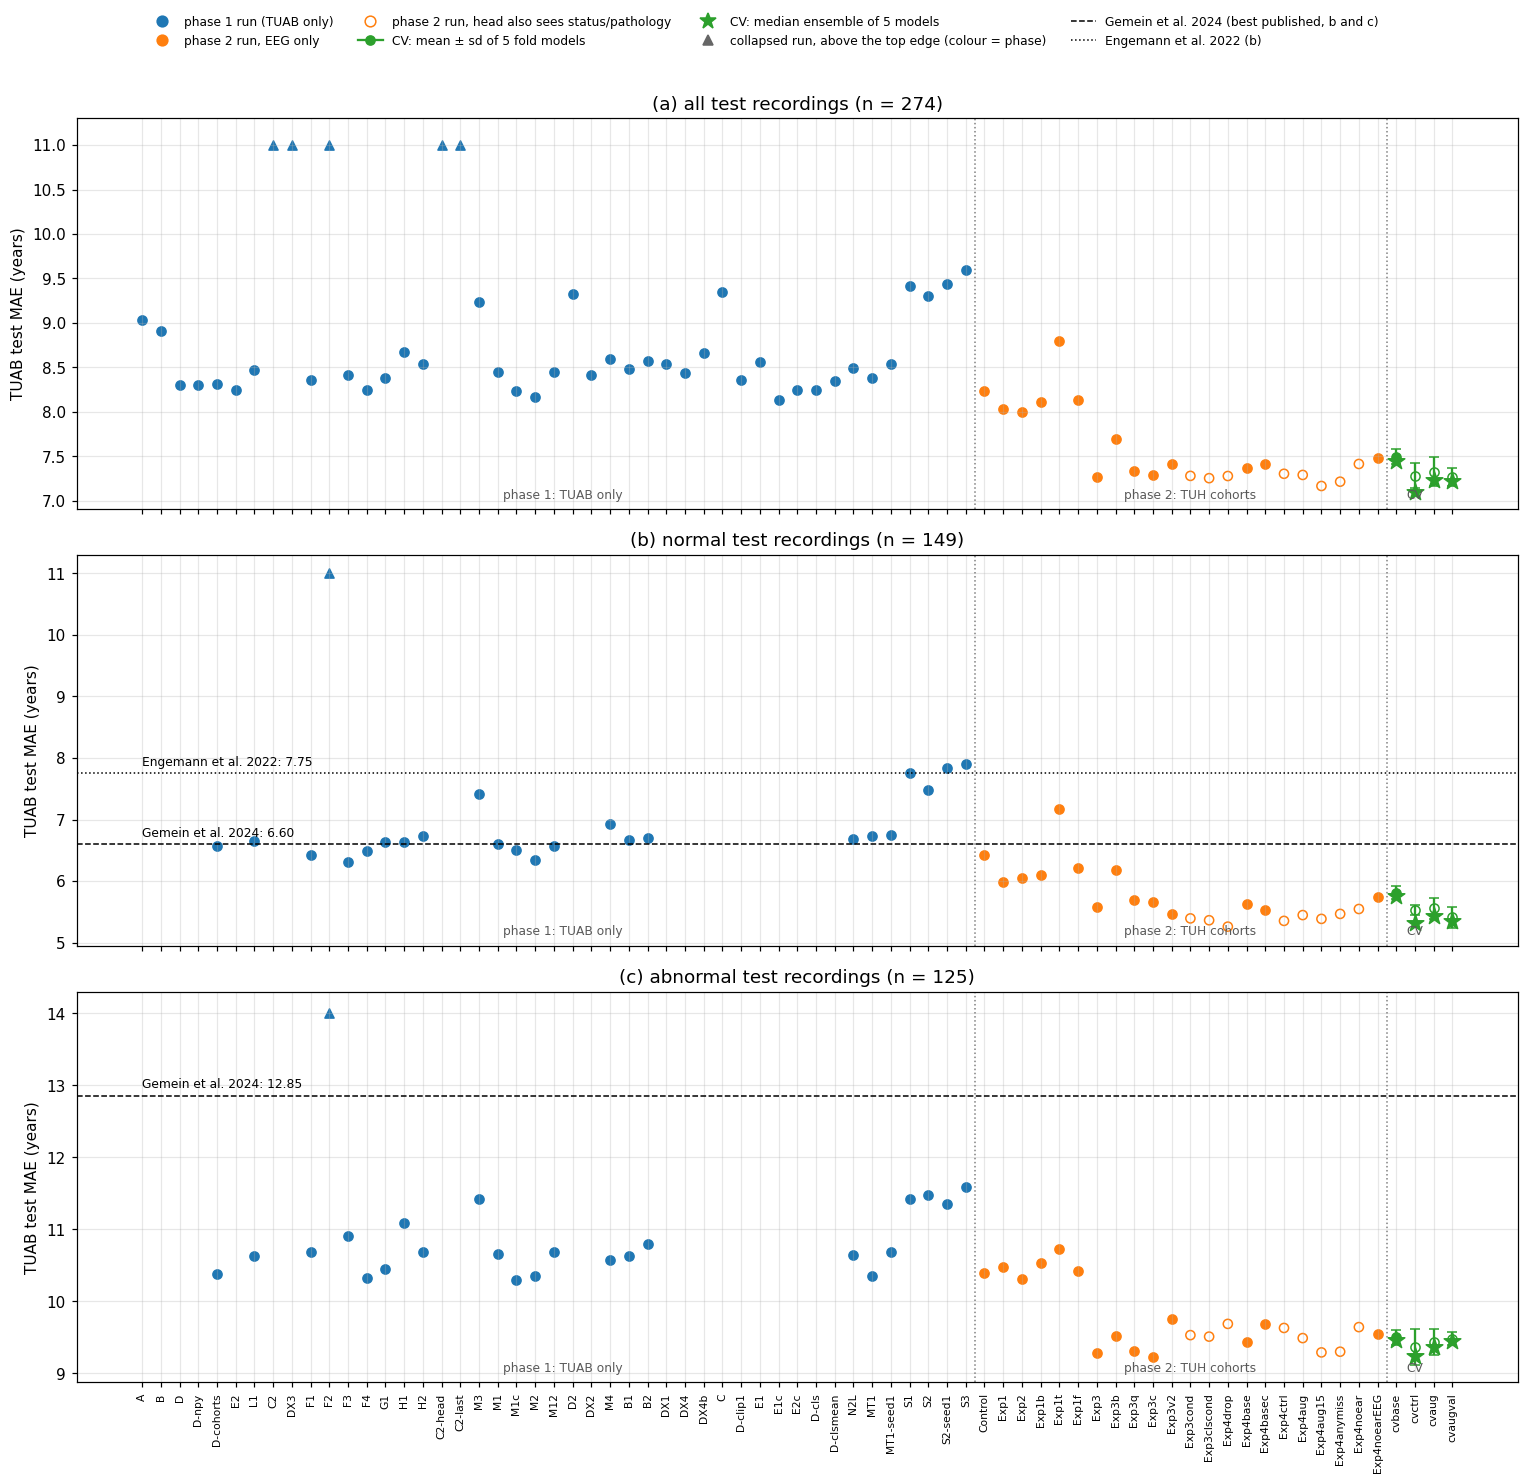

In [30]:
from matplotlib.lines import Line2D

SOTA = {  # published TUAB brain-age MAE (years): (label, value, line style)
    "normal": [("Gemein et al. 2024", 6.60, "--"), ("Engemann et al. 2022", 7.75, ":")],
    "abnormal": [("Gemein et al. 2024", 12.85, "--")],
}
PANELS = (("all", 2, 11.0, "all test recordings (n = 274)"),
          ("normal", 3, 11.0, "normal test recordings (n = 149)"),
          ("abnormal", 4, 14.0, "abnormal test recordings (n = 125)"))
fig, axes = plt.subplots(3, 1, figsize=(14, 13.5), sharex=True)
pts = ([("1", r.run, r.test, r.test_normal, r.test_abnormal, False) for r in reg.itertuples()] +
       [("2", n, t22.loc[n, "test all"], t22.loc[n, "normal"], t22.loc[n, "abnormal"], rs.EXPERIMENTS[n].conditions)
        for n in P2_RUNS])
colors = {"1": "tab:blue", "2": "tab:orange", "3": "tab:green"}
cv_exps = ("cvbase", "cvctrl", "cvaug", "cvaugval")
n1 = sum(p[0] == "1" for p in pts)
for ax, (cohort, col, ymax, title) in zip(axes, PANELS):
    for x, p in enumerate(pts):
        y = p[col]
        if np.isnan(y):
            continue
        ax.scatter(x, min(y, ymax), s=36, marker="^" if y > ymax else "o",
                   facecolors="none" if p[5] else colors[p[0]], edgecolors=colors[p[0]])
    for j, exp in enumerate(cv_exps):
        x = len(pts) + j
        m, sd, _ = fold_stats(exp, "heldout", "TUAB", cohort)
        hollow = rs.EXPERIMENTS[exp].conditions
        ax.errorbar(x, m, yerr=sd, fmt="o", color=colors["3"], mfc="none" if hollow else colors["3"], capsize=3)
        if preds is not None and STATUS:
            ax.scatter(x, ens_mae(exp, cohort), marker="*", s=130, color=colors["3"], zorder=3)
    for label, value, ls in SOTA.get(cohort, []):
        ax.axhline(value, ls=ls, color="k", lw=1)
        ax.text(0, value + 0.08, f"{label}: {value:.2f}", fontsize=8, va="bottom")
    for xb in (n1 - 0.5, len(pts) - 0.5):                      # phase separators
        ax.axvline(xb, ls=":", color="0.5", lw=1)
    for xm, label in ((n1 / 2, "phase 1: TUAB only"), ((n1 + len(pts)) / 2, "phase 2: TUH cohorts"),
                      (len(pts) + 1, "CV")):
        ax.text(xm, 0.02, label, transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=8,
                color="0.35")
    ax.set_ylim(top=ymax + 0.3)
    ax.set_ylabel("TUAB test MAE (years)")
    ax.set_title(title)
names = [p[1] for p in pts] + list(cv_exps)
axes[-1].set_xticks(range(len(names)), names, rotation=90, fontsize=7)

dot = dict(marker="o", ls="none", markersize=7)
handles = [
    Line2D([], [], color=colors["1"], mfc=colors["1"], label="phase 1 run (TUAB only)", **dot),
    Line2D([], [], color=colors["2"], mfc=colors["2"], label="phase 2 run, EEG only", **dot),
    Line2D([], [], color=colors["2"], mfc="none", label="phase 2 run, head also sees status/pathology", **dot),
    Line2D([], [], color=colors["3"], mfc=colors["3"], marker="o", ls="-", label="CV: mean ± sd of 5 fold models"),
    Line2D([], [], color=colors["3"], marker="*", ls="none", markersize=11, label="CV: median ensemble of 5 models"),
    Line2D([], [], color="0.4", mfc="0.4", marker="^", ls="none", markersize=7,
           label="collapsed run, above the top edge (colour = phase)"),
    Line2D([], [], color="k", ls="--", lw=1, label="Gemein et al. 2024 (best published, b and c)"),
    Line2D([], [], color="k", ls=":", lw=1, label="Engemann et al. 2022 (b)"),
]
fig.legend(handles=handles, loc="upper center", ncol=4, fontsize=8, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.95))
panel_labels(axes)
assert_max_columns(fig)
plt.show()

### Table 2.9. The runs around the best result

The 12 runs with the lowest TUAB test MAE across all phases (Tables 2.2–2.7):
* `kind`:
  * `single split`: one run;
  * `CV mean`: mean over 5 fold models;
  * `CV ensemble`: median of 5 fold models.
* `run`: linked to its ClearML experiment (for CV: the project of its folds).
* `feature space` (Eq. (2.13)): what the head reads; EEG-only rows have no `path_label`.
* `test all` / `normal` / `abnormal`: MAE (Eq. (0.1)) on the **TUAB test set only**, all 274 recordings
  and its 149 normal / 125 abnormal ones. The same set is used in every kind of row: for the CV rows it
  is the held-out TUAB test set, which no fold trains on (Table 2.7). The status is TUAB's own
  normal/abnormal label.

TUEG columns (MAE, Eq. (0.1), years, on **TUEG recordings only**, those outside TUAB, that the run never
trained on):
* `TUEG all` / `TUEG normal` / `TUEG abnormal`: all of them, and by status (Eq. (1.2));
* one column per NEDC diagnosis group of the pathology vector (Eq. (2.13), Table 1.9). A recording counts in
  every group it is flagged with, so groups overlap: `cl. seiz.` / `el. seiz.` clinical / electrographic
  seizure, `epil.` epilepsy, `stroke`, `TBI`, `subst.` substance use, `bipol.` bipolar, `anx.` anxiety,
  `depr.` depression, `schiz.` schizophrenia, `dement.` dementia (with Alzheimer's), `MS`, `other`
  (Parkinson's, ADHD).

Where the recordings come from:
* **Single-split run:** its own **validation** split, re-scored from its checkpoint (`scripts/eval_runs.py`).
  That is about 1.2–2.9K TUEG recordings, depending on the cohort.
* **CV row:** the out-of-fold predictions of the whole CV pool (26,685 TUEG recordings): the test folds,
  or for `cvaugval` its val folds, which also chose its epoch. The `CV mean` and
  `CV ensemble` rows therefore show the same TUEG values.
* **Phase-1 run:** trained and validated on TUAB only, so it has no TUEG numbers ("–").
* A group with fewer than 20 recordings for a run is "–". Many diagnosis groups are that small in a single
  validation split, while the CV pool has 36–2,064 per group.
* The single-split validation sets differ between cohorts, so their TUEG columns compare only within a
  cohort. The CV columns compare across the CV experiments.

The table is shown in two parts with the same rows: the TUAB test and TUEG status columns first, then
the TUEG diagnosis-group columns.

Rows: the 12 lowest `test all`, listed single-split runs first, then the CV rows, each block ranked on
`test all`. The best EEG-only run of each kind is marked `◆`. Source:
`docs/data/tueg_pathology_mae.csv`.

In [31]:
rows = [{"run": r.run, "kind": "single split", "phase": "1", "feature space": rs.feature_space(r.run), "test all": r.test,
         "normal": r.test_normal, "abnormal": r.test_abnormal} for r in reg.itertuples()]
rows += [{"run": n, "kind": "single split", "phase": "2", "feature space": rs.feature_space(n),
          "test all": t22.loc[n, "test all"], "normal": t22.loc[n, "normal"], "abnormal": t22.loc[n, "abnormal"]}
         for n in P2_RUNS]
for exp in cv_exps:
    fs = rs.feature_space(exp)
    rows.append({"run": exp, "kind": "CV mean", "phase": "3", "feature space": fs,
                 **{k: fold_stats(exp, "heldout", "TUAB", c)[0] for k, c in
                    (("test all", "all"), ("normal", "normal"), ("abnormal", "abnormal"))}})
    if preds is not None and STATUS:
        rows.append({"run": exp, "kind": "CV ensemble", "phase": "3", "feature space": fs,
                     "test all": ens_mae(exp), "normal": ens_mae(exp, "normal"), "abnormal": ens_mae(exp, "abnormal")})
allruns = pd.DataFrame(rows)
top = allruns.sort_values("test all").head(12).copy()
# MAE on each run's held-out TUEG recordings (val for a single split, out-of-fold for CV), by status and
# NEDC diagnosis group; groups with fewer than 20 recordings are left out (docs/data/tueg_pathology_mae.csv).
TUEG_MIN_N = 20
_tp = pd.read_csv(os.path.join(REPO, "docs/data/tueg_pathology_mae.csv"))
_tp.loc[_tp.n < TUEG_MIN_N, "MAE"] = np.nan
TUEG_COLS = list(dict.fromkeys(_tp.group))
top = top.join(_tp.pivot(index="run", columns="group", values="MAE")[TUEG_COLS], on="run")
KIND_ORDER = {"single split": 0, "CV mean": 1, "CV ensemble": 2}
top = top.sort_values(["kind", "test all"], key=lambda s: s.map(KIND_ORDER) if s.name == "kind" else s)
for kind in top.kind.unique():
    k = allruns[(allruns.kind == kind) & allruns["feature space"].isin(EEG_ONLY)].sort_values("test all")
    if len(k) and k.index[0] in top.index:
        top.loc[k.index[0], "run"] = "◆ " + top.loc[k.index[0], "run"]
top["run"] = [rs.clearml_link(r, cml.url.get(r.replace("◆ ", ""), "")) for r in top.run]
top = top.set_index("run")
_status = ["kind", "phase", "feature space", "test all", "normal", "abnormal", "TUEG all", "TUEG normal", "TUEG abnormal"]
display(numbered_table(top[_status], "2.9", "The runs around the best result"))
display(numbered_table(top[["kind"] + [c for c in TUEG_COLS if c not in _status]], "2.9",
                       "The runs around the best result: TUEG MAE by diagnosis group"))

,kind,phase,feature space,test all,normal,abnormal,TUEG all,TUEG normal,TUEG abnormal
run,,,,,,,,,
Exp4aug15,single split,2,cls_token + path_label,7.17,5.38,9.29,7.84,7.26,8.24
Exp4anymiss,single split,2,cls_token + path_label,7.21,5.47,9.30,7.78,7.25,8.12
Exp3clscond,single split,2,cls_token + path_label,7.25,5.36,9.51,7.98,7.47,8.22
◆ Exp3,single split,2,patch_tokens,7.26,5.57,9.28,7.82,6.91,8.08
Exp4drop,single split,2,patch_tokens + path_label,7.28,5.26,9.68,7.72,6.97,8.27
Exp3cond,single split,2,patch_tokens + path_label,7.28,5.39,9.53,7.90,7.35,8.20
Exp3c,single split,2,patch_tokens,7.29,5.66,9.22,7.84,6.94,8.10
cvaugval,CV mean,3,cls_token + path_label,7.26,5.41,9.48,7.99,7.36,8.32
cvctrl,CV mean,3,cls_token + path_label,7.28,5.53,9.37,8.17,7.51,8.50


,kind,cl. seiz.,el. seiz.,epil.,stroke,TBI,subst.,bipol.,anx.,depr.,schiz.,dement.,MS,other
run,,,,,,,,,,,,,,
Exp4aug15,single split,7.07,–,8.46,7.21,8.53,8.42,7.48,–,–,–,–,–,–
Exp4anymiss,single split,7.02,–,8.35,7.08,8.84,7.60,7.46,–,–,–,–,–,–
Exp3clscond,single split,7.43,–,8.43,7.49,10.25,7.78,–,–,–,–,–,–,–
◆ Exp3,single split,6.70,8.58,5.93,9.79,10.49,9.20,–,–,–,–,–,–,–
Exp4drop,single split,7.03,–,9.08,7.76,11.09,8.32,6.77,–,–,–,–,–,–
Exp3cond,single split,7.13,–,8.49,7.89,10.52,7.33,–,–,–,–,–,–,–
Exp3c,single split,6.68,9.29,6.07,9.63,10.65,9.23,–,–,–,–,–,–,–
cvaugval,CV mean,7.31,8.36,7.85,8.69,10.03,7.38,5.98,6.17,7.16,8.39,7.88,10.26,7.14
cvctrl,CV mean,7.44,9.19,7.91,8.85,10.38,7.65,5.79,6.17,7.63,8.63,7.45,11.64,7.38


## 3. The best experiment

**Which run is best.** Single-split runs were compared on the TUAB test set itself (Section 0). Only
the CV runs have an error bar, and their CV test / TUEG out-of-fold errors were never used for
selection. So "best" is decided among the CV runs:

* **Best overall: `cvctrl`** (= Exp4ctrl cross-validated). It has the lowest TUAB test MAE, as a single
  fold model and as a 5-model ensemble (Table 2.7).
  * `cvaug` adds T1/T2 channel-dropout augmentation and ties with it: the differences are within noise
    in Table 5.2 (C2).
  * The simpler `cvctrl` is therefore the recommended configuration.
* **Best EEG-only: `cvbase`.** Its head sees only the EEG. `cvctrl` and `cvaug` also see the
  recording's status (normal / abnormal / no label) and 13 diagnosis flags from the clinical sheet. A
  deployed brain-age model would not have these, and published TUAB results do not use them. `cvbase` is
  therefore the number to compare with the literature (Table 3.3).

Both are LaBraM-base fine-tuned on `all_both_v3` with the M1 recipe. They differ in three settings
(Table 3.2): class-token vs mean pooling, the condition vector, and 10 vs 5 epochs.

### What the model computes

**Input and target.** The raw EEG $u$ (µV) of a 10 s window is scaled to $x = u / 100$ and cut into 1 s
patches $x_{c,a,t}$:
* channel $c = 1..C$, with $C = 23$ minus the missing T1/T2 of that recording;
* patch $a = 1..10$, sample $t = 1..200$.

The common average reference removes what all channels share (`labram/data/preprocess.py::common_average_reference`):

$$ \tilde x_{c,a,t} = x_{c,a,t} - \frac{1}{C}\sum_{c'=1}^{C} x_{c',a,t} \tag{3.1} $$

The age $y$ (years) is z-scored with the training windows' mean $\mu$ and standard deviation $\sigma$
(`labram/data/tuh_datasets.py::TUABAgeLoader._age_target`):

$$ z = \frac{y - \mu}{\sigma} \tag{3.2} $$

**Mixup.** Each training batch is blended with a permuted copy of itself, using one
$\lambda \sim \mathrm{Beta}(\alpha, \alpha)$ per batch with $\alpha = 0.4$ (`labram/train/mixup.py::mixup_batch`).
The condition vector $c$ travels with the target, so it is blended too:

$$ \bar x = \lambda x + (1-\lambda)\,x_{\pi}, \qquad \bar z = \lambda z + (1-\lambda)\,z_{\pi}, \qquad
   \bar c = \lambda c + (1-\lambda)\,c_{\pi} \tag{3.3} $$

**Loss.** Huber loss (Eq. (2.3)) with $\delta = 1$ on the z-scored residual $r = \hat z - \bar z$
(`labram/losses/regression.py::build_regression_criterion`):

$$ \ell_\delta(r) = \begin{cases} \tfrac12 r^2 & \lvert r\rvert \le \delta \\
   \delta\,(\lvert r\rvert - \tfrac12\delta) & \text{otherwise} \end{cases} \tag{3.4} $$

**Encoder and head.** $f_\theta$ is the 12-block LaBraM-base transformer, initialized from the
released `labram-base.pth`. Its output is $h \in \mathbb R^{200}$:
* the final LayerNorm's class token (`cvctrl`, `cvaug`);
* the mean over patch tokens (`cvbase`).

$$ h = f_\theta(\tilde x) \tag{3.5} $$

The linear head reads $h$, concatenated with a 32-d projection of the 17-d condition vector
$c \in \{0,1\}^{17}$ (3 one-hot status + 14 multi-hot pathology groups, `conditions_v1.npz`) when
conditions are on (`labram/models/neural_transformer.py`, `model.session_features=head`):

$$ \hat z = w^\top \begin{bmatrix} h \\ W_c\,c \end{bmatrix} + b, \qquad W_c \in \mathbb R^{32\times 17} \tag{3.6} $$

**Optimizer and schedule.** AdamW with weight decay 0.05. Layer-wise lr decay $\rho = 0.65$ gives block
$l$ of $L = 12$ the rate $\mathrm{lr}\cdot\rho^{\,L+1-l}$ (`labram/optim_factory.py::LayerDecayValueAssigner`).
The rate warms up linearly, then follows a cosine down to $10^{-6}$ (`labram/utils/training.py`).

**Scoring.** A recording's prediction is the de-normalized mean over its evaluation windows $W_i$ (the
first 5 minutes after the trim, 30 windows; `evaluation.agg_windows=mean`):

$$ \hat y_i = \mu + \sigma\,\frac{1}{\lvert W_i\rvert}\sum_{w\in W_i}\hat z_w \tag{3.7} $$

The fold ensemble takes the median over the $K = 5$ fold models (`labram/eval/cv_compare.py::ensemble`):

$$ \hat y_i^{\mathrm{ens}} = \operatorname{median}_{k=1..K}\,\hat y_{i,k} \tag{3.8} $$

### Table 3.1. The best configuration (`cvctrl`), step by step

One row per stage of the pipeline:
* `setting`: the configuration field;
* `cvctrl`: its value, read from the configuration rebuilt by `rs.resolve_config`
  (`finetune_tuab_age.json` + the run's overrides, exactly as the trainer builds it);
* `cvbase`: the EEG-only variant's value, where it differs;
* `equation`: where the setting appears above.

In [32]:
best = rs.resolve_config(AGE_JSON, rs.experiment_overrides(rs.EXPERIMENTS["cvctrl"]))
eeg_only = rs.resolve_config(AGE_JSON, rs.experiment_overrides(rs.EXPERIMENTS["cvbase"]))
paper = rs.resolve_config(PAPER_JSON)
fb, fe = rs.flatten(best.as_dict()), rs.flatten(eeg_only.as_dict())
STEPS = [
    ("data", "cohort", "data.data_path", ""),
    ("data", "5-fold CV, grouped by", "cross_validation.split_by", ""),
    ("data", "CV pool", "cross_validation.pool", ""),
    ("windows", "window length (s)", "data.window_sec", ""),
    ("windows", "trim start / end (s)", ("data.trim_start_sec", "data.trim_end_sec"), ""),
    ("windows", "train minutes per recording per epoch", "data.train_minutes_per_epoch", ""),
    ("windows", "eval minutes per recording", "data.eval_minutes", "(3.7)"),
    ("channels", "channels left out where missing", "channel_drop.channels", ""),
    ("channels", "T1/T2 dropout probability (augmentation)", "channel_drop.prob", ""),
    ("input", "common average reference", "labram_plus.common_average_reference", "(3.1)"),
    ("input", "per-patch z-scoring", "labram_plus.z_score_patches", ""),
    ("encoder", "model", "model.model", "(3.5)"),
    ("encoder", "initial weights", "finetune_checkpoint.finetune", ""),
    ("encoder", "drop path", "model.drop_path", ""),
    ("encoder", "fused attention (speed only)", "model.fused_attention", ""),
    ("head", "mean pooling (False = class token)", "model.use_mean_pooling", "(3.5)"),
    ("head", "condition vector", ("model.session_features", "data.session_features"), "(3.6)"),
    ("head", "condition projection size", "model.session_head_dim", "(3.6)"),
    ("head", "output init scale", "model.init_scale", ""),
    ("target", "task", "model.task", "(3.2)"),
    ("loss", "regression loss / δ", ("loss.regression_loss", "loss.huber_delta"), "(3.4)"),
    ("augmentation", "mixup α (on)", ("mixup.alpha", "mixup.enabled"), "(3.3)"),
    ("optimizer", "AdamW lr / batch", ("optimizer.lr", "trainer.batch_size"), ""),
    ("optimizer", "weight decay / layer decay", ("optimizer.weight_decay", "optimizer.layer_decay"), ""),
    ("schedule", "epochs / warmup", ("trainer.epochs", "optimizer.warmup_epochs"), ""),
    ("schedule", "min lr", "optimizer.min_lr", ""),
    ("selection", "checkpoint", None, "lowest val MAE (recording level)"),
    ("scoring", "window aggregation / case unit", ("evaluation.agg_windows", "evaluation.agg_case_by"), "(3.7)"),
]


def value(flat, keys):
    keys = keys if isinstance(keys, tuple) else (keys,)
    vals = [flat[k] for k in keys]
    vals = [os.path.basename(str(v).rstrip("/")) if k.endswith(("data_path", "finetune")) else v
            for k, v in zip(keys, vals)]
    return " / ".join(rs._show(v) for v in vals)


rows = []
for stage, what, keys, eq in STEPS:
    if keys is None:
        rows.append({"stage": stage, "what": what, "setting": "–", "cvctrl": eq, "cvbase": "", "equation": ""})
        continue
    vb, ve = value(fb, keys), value(fe, keys)
    rows.append({"stage": stage, "what": what, "setting": " / ".join(keys if isinstance(keys, tuple) else (keys,)),
                 "cvctrl": vb, "cvbase": "" if ve == vb else ve, "equation": eq})
numbered_table(pd.DataFrame(rows).set_index(["stage", "what"]), "3.1", "The best configuration")

### Table 3.2. The three cross-validated configurations

Every configuration field on which `cvbase`, `cvctrl` and `cvaug` disagree
(`labram/eval/research_summary.py::config_diff`, bookkeeping fields excluded).

In [33]:
cfgs = {e: rs.flatten(rs.resolve_config(AGE_JSON, rs.experiment_overrides(rs.EXPERIMENTS[e])).as_dict())
        for e in CV3}
keys = sorted(k for k in cfgs["cvbase"] if not k.startswith(rs.NON_SCIENTIFIC)
              and len({rs._show(c.get(k)) for c in cfgs.values()}) > 1)
t32 = pd.DataFrame({e: [rs._show(c.get(k)) for k in keys] for e, c in cfgs.items()}, index=pd.Index(keys, name="field"))
numbered_table(t32, "3.2", "The three cross-validated configurations")

,cvbase,cvctrl,cvaug
field,,,
channel_drop.consistency_weight,0,0,0.1
channel_drop.prob,0,0,0.2
data.session_features,,conditions_v1.npz,conditions_v1.npz
model.session_features,off,head,head
model.use_mean_pooling,True,False,False
optimizer.warmup_epochs,1,3,3
trainer.epochs,5,10,10


### Table 3.3. Results of the best experiment by evaluation set and cohort

`cvctrl` (best overall) and `cvbase` (best EEG-only), mean ± sample sd over the 5 fold models of the
MAE (Eq. (0.1)) and the mean $R^2$ (Eq. (0.2)), per evaluation set and status cohort:
* `CV val`, `CV test`: the fold's own held-out folds, TUAB and TUEG recordings together;
* `TUEG test`: the TUEG recordings of each fold's test fold;
* `TUAB test`: the official test set, $n = 274$.

$R^2$ is relative to each cohort's own age spread, so it does not compare across cohorts. The last row
gives the median ensemble (Eq. (3.8)) on the TUAB test set when the per-recording predictions are
available. For reference, the best published TUAB normal-recording result is MAE 6.60, $R^2$ 0.73
(Gemein et al. 2024, trained on TUAB normal recordings only, on its own patient-wise re-split of TUAB).

In [34]:
rows = []
for label, split, source in (("CV val", "val", "all"), ("CV test", "test", "all"), ("TUEG test", "test", "TUEG"),
                             ("TUAB test", "heldout", "TUAB")):
    for cohort in ("all", "normal", "abnormal"):
        r = {"set": label, "cohort": cohort}
        for exp in ("cvctrl", "cvbase"):
            s = cv[(cv.exp == exp) & (cv.split == split) & (cv.source == source) & (cv.cohort == cohort)]
            s = s.drop_duplicates("fold")
            r[f"{exp} MAE"] = f"{s.MAE.mean():.2f} ± {s.MAE.std(ddof=1):.2f}"
            r[f"{exp} R²"] = round(float(s.R2.mean()), 2)
        rows.append(r)
if preds is not None and STATUS:
    for cohort in ("all", "normal", "abnormal"):
        r = {"set": "TUAB test, ensemble", "cohort": cohort}
        for exp in ("cvctrl", "cvbase"):
            e = ensemble(exp)
            e = e if cohort == "all" else e[e.status == cohort]
            m = cc.metrics(e.pred, e.true)
            r[f"{exp} MAE"] = f"{m['MAE']:.2f}"
            r[f"{exp} R²"] = round(m["R2"], 2)
        rows.append(r)
numbered_table(pd.DataFrame(rows).set_index(["set", "cohort"]), "3.3", "Results of the best experiment")

### Table 3.4. Predicted versus true age by subcohort and status

The three cross-validated models, scored per recording on three sets of recordings
(`rs.prediction_sets`, from the per-recording CV predictions):
* `TUAB test, ensemble`: the 274 TUAB test recordings, predicted by the median of the 5 fold models
  (Eq. (3.8)).
* `TUAB out-of-fold`: the TUAB recordings of the CV pool (TUAB train + val), each predicted by the one fold
  model that never saw its patient.
* `TUEG out-of-fold`: the same for the pool's TUEG recordings that are not in TUAB.

`status` is the recording's normal / abnormal / no-label status (Eq. (1.2)), and `all` is every
recording of the set. Per model, the columns are:
* `MAE` (Eq. (0.1), years);
* `bias` = mean(predicted − true) (Eq. (0.3), years): the signed drift. It is negative when the model
  predicts too young and positive when too old, so closer to 0 is better;
* $R^2$ (Eq. (0.2));
* the bias slope $\beta$ (Eq. (0.5)).

All come from `rs.prediction_metrics`. Needs the
per-recording CV predictions and the TUH index.

In [35]:
if preds is not None and HAVE_TUEG:
    psets = rs.prediction_sets(preds, tueg)
    pm = rs.prediction_metrics(psets[psets.exp.isin(CV3)])
    t34 = pm.pivot_table(index=["set", "status"], columns="exp", values=["MAE", "bias", "R²", "β"], sort=False)
    t34 = t34.swaplevel(axis=1).reindex(columns=pd.MultiIndex.from_product([CV3, ["MAE", "bias", "R²", "β"]]))
    n = pm.drop_duplicates(["set", "status"]).set_index(["set", "status"]).n
    t34.insert(0, ("", "n"), n.reindex(t34.index))
    order = {s: k for k, s in enumerate(rs.PREDICTION_SETS)}
    t34 = t34.sort_index(key=lambda ix: ix.map(order) if ix.name == "set" else
                         ix.map({s: k for k, s in enumerate(("all", *rs.STATUS))}))
    display(numbered_table(t34, "3.4", "Predicted versus true age by subcohort and status"))
else:
    print("Per-recording CV predictions or the TUH index not found: Table 3.4 and Figure 3.1 skipped.")

### Figure 3.1. Predicted versus true age, per model and subcohort

Predicted age $\hat y_i$ against true age $y_i$ (years), one point per recording; the data of Table 3.4.
One row per cross-validated model, and two subcohorts per row:
* left column: the 274 TUAB test recordings, predicted by the 5-model median ensemble;
* right column: the TUEG out-of-fold recordings ($n$ = 26,685), each predicted by the fold model that
  held it out.

The panels are:
* (a), (b) `cvbase`, the best EEG-only model;
* (c), (d) `cvctrl`, the best overall;
* (e), (f) `cvaug`.

**Colour = status** (Eq. (1.2)): green normal, red abnormal, grey no label. The no-label group occurs only
in TUEG.
* **Dashed black diagonal:** a perfect prediction, $\hat y = y$.
* **Coloured lines:** least-squares fits of $\hat y$ on $y$ per status. A fit flatter than the diagonal
  is the regression to the mean that $\beta$ measures: the fit's slope is $1 + \beta$ (Eq. (0.5)).
* **Box in each panel:** $n$, MAE and $\beta$ per status, and for all recordings together.

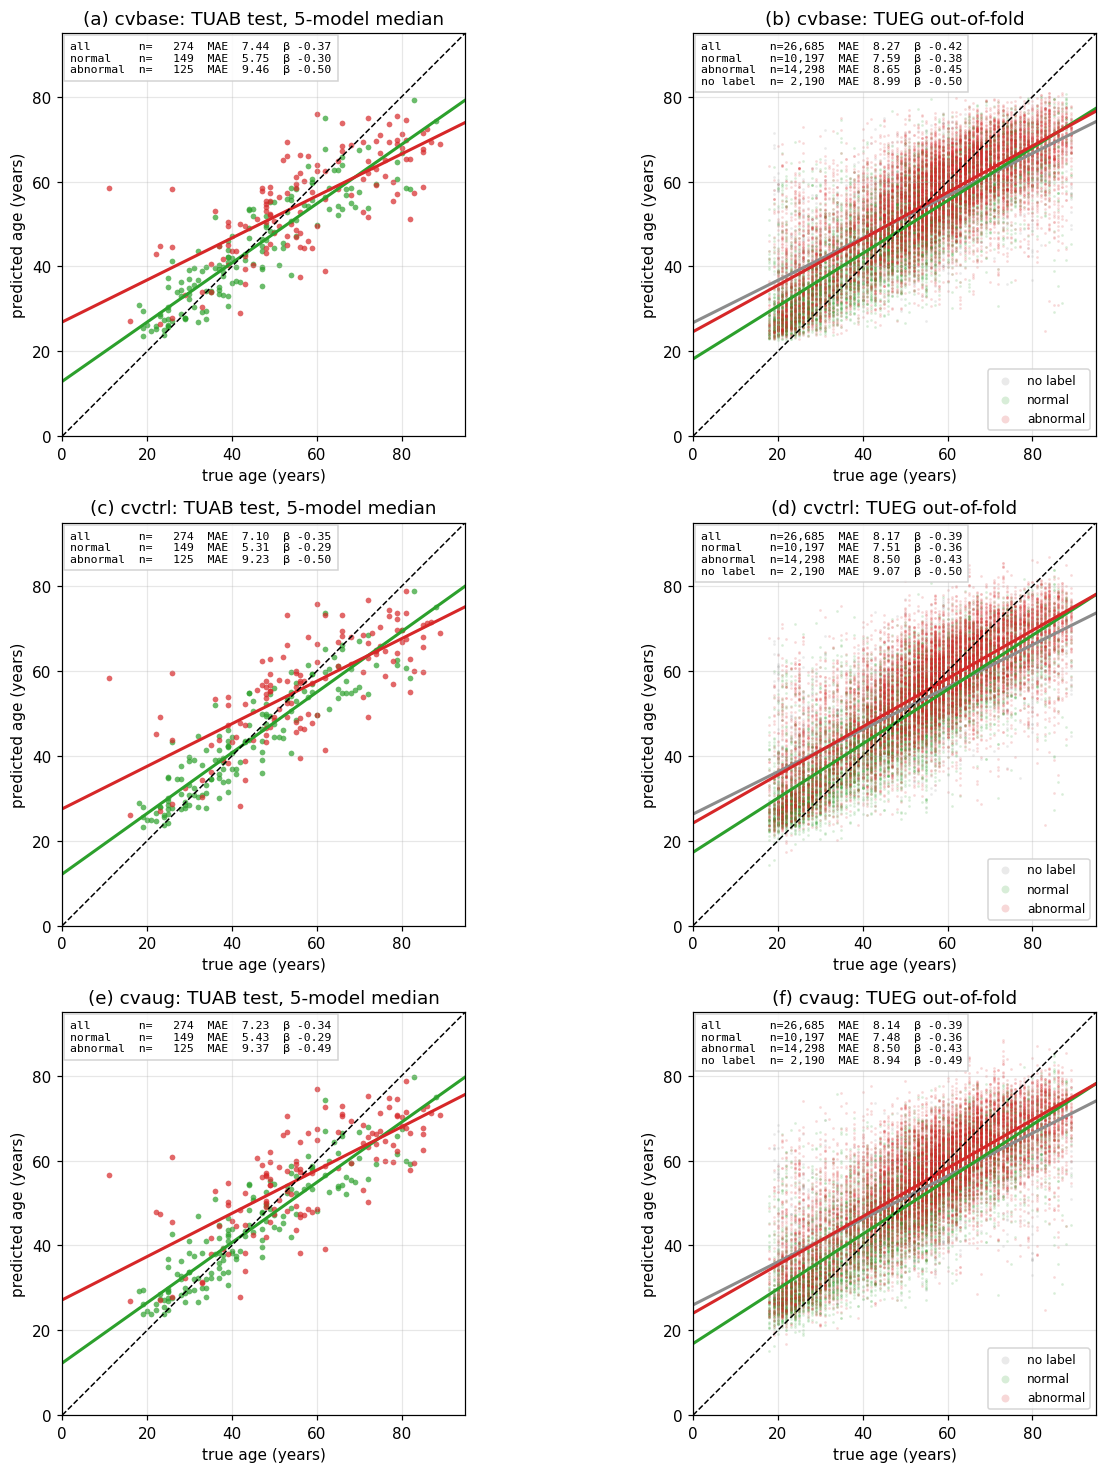

In [36]:
if preds is not None and HAVE_TUEG:
    SCOL = {"normal": "tab:green", "abnormal": "tab:red", "no label": "0.55"}
    shown = (rs.PREDICTION_SETS[0], rs.PREDICTION_SETS[2])
    fig, axes = plt.subplots(len(CV3), 2, figsize=(12.5, 4.5 * len(CV3)))  # fits one PDF page
    grid = np.linspace(0, 95, 2)
    for r, exp in enumerate(CV3):
        for c, name in enumerate(shown):
            ax = axes[r, c]
            g = psets[(psets.exp == exp) & (psets.set == name)]
            big = len(g) > 2000
            lines = []
            for status in ("no label", "normal", "abnormal"):          # abnormal drawn last, on top
                s = g[g.status == status]
                if not len(s):
                    continue
                ax.scatter(s.true, s.pred, s=3 if big else 14, alpha=0.18 if big else 0.7, color=SCOL[status],
                           lw=0, rasterized=True, label=status)
                k, b = np.polyfit(s.true, s.pred, 1)
                ax.plot(grid, k * grid + b, color=SCOL[status], lw=2)
            for status in ("all", "normal", "abnormal", "no label"):
                s = g if status == "all" else g[g.status == status]
                if len(s):
                    m = rs.age_fit_metrics(s.pred, s.true)
                    lines.append(f"{status:9s} n={m['n']:>6,}  MAE {m['MAE']:5.2f}  β {m['β']:+.2f}")
            ax.plot(grid, grid, ls="--", color="k", lw=1)
            ax.text(0.02, 0.98, "\n".join(lines), transform=ax.transAxes, va="top", ha="left", fontsize=7.5,
                    family="monospace", bbox=dict(facecolor="white", alpha=0.85, edgecolor="0.8"))
            ax.set_xlim(0, 95)
            ax.set_ylim(0, 95)
            ax.set_aspect("equal")
            ax.set_xlabel("true age (years)")
            ax.set_ylabel("predicted age (years)")
            what = "TUAB test, 5-model median" if c == 0 else "TUEG out-of-fold"
            ax.set_title(f"{exp}: {what}")
            if c == 1:
                ax.legend(loc="lower right", fontsize=8, markerscale=3)
    fig.tight_layout()
    panel_labels(list(axes.ravel()))
    assert_max_columns(fig)
    plt.show()

**Reading Table 3.4 and Figure 3.1.**
* **Abnormal recordings are harder in every set.**
  * On TUAB test, their MAE is 3.7–3.9 years above the normal recordings'.
  * In TUEG out-of-fold the gap is about 1 year (0.99–1.06). The no-label recordings are the hardest there
    (MAE 8.9–9.1).
* **Every model regresses to the mean** ($\beta \approx -0.3$ to $-0.5$). The fit lines in Figure 3.1
  are visibly flatter than the diagonal: old patients are predicted too young and young ones too old.
  The effect is strongest for the abnormal and no-label recordings ($\beta \approx -0.43$ to $-0.50$).
* **Bias.** The overall drift is small: within ±1.2 years on TUAB test and ±0.3 on TUEG. But the
  EEG-only `cvbase` predicts abnormal TUAB test recordings 2.0 years too young on average, against
  0.9–1.0 for `cvctrl` / `cvaug`.
* **TUEG is harder than TUAB.** TUEG out-of-fold MAE is 8.1–8.3, against 7.1–7.2 for the TUAB recordings
  of the same pool. Its normal recordings are worse too: 7.5–7.6 against 6.4–6.6. TUEG's status comes
  from report text rather than TUAB's curated folders. It also covers a broad clinical population: 38 %
  of its recordings in the clinical sheet list a sedating drug (Table 1.9).
* **cvctrl and cvaug beat cvbase on the TUAB test ensemble** by 0.2–0.35 years. Their gain is larger on
  normal recordings (0.3–0.4 years) than on abnormal ones (0.1–0.2).

### Table 3.5. TUAB test MAE before and after age-bias correction, and published / classical methods

**Every other number in this notebook is before bias correction.** That includes the MAEs of Sections 0–5
and Figure 2.1, except the `cal.` columns of Tables 2.5–2.7, which use Eq. (3.11) below. They score the
model's raw prediction $\hat y_i$. Brain-age studies often also report a *bias-corrected* error. Gemein et
al. 2024 does: its 6.60 / 12.85 are after correction, and its raw normal MAE was 6.48. This table puts our
CV models on that footing, and lists the other methods evaluated on the TUAB test set.

**How a correction is made: three steps, and what each one sees.**
1. **Predict.** Each CV experiment's 5 fold models predict every TUAB test recording, and the ensemble is
   their median (Eq. (3.8)). The TUAB test set is in no fold. No fold model trained on it or chose its
   epoch on it (the epoch is chosen on the fold's val fold).
2. **Fit, on out-of-fold predictions only.** Each recording of the CV pool (TUAB train + val, TUEG
   train + val; 29,035 recordings of 13,550 patients) is predicted by the one fold model whose in-pool
   **test fold** held it out. These are the out-of-fold predictions. They are not the val folds that chose
   the epoch. The correction is fitted on them with *their* true ages, which is allowed: none of them is a
   TUAB test recording and none shares a patient with one (Table 3.6). `normal` in a column name means the
   fit uses only the normal out-of-fold recordings, as Gemein et al. do.
3. **Apply to the TUAB test predictions.** This is where the methods differ:
   * **Recalibration** (Eq. (3.11)) and **Cole** (Eq. (3.10)) map each prediction $\hat y_i$ to a corrected
     one using $\hat y_i$ alone. They never read a TUAB test true age, so their MAE is a valid test error.
   * The **gap correction** (Eq. (3.9)) subtracts the fitted age trend *evaluated at the test recording's
     true age* $y_i$. It **does use the TUAB test labels** (Table 3.6: permuting them changes the corrected
     predictions by more than 25 years). Its MAE is therefore not a prediction error. It is the size of the
     brain-age gap after its age trend is removed, the quantity Gemein et al. and much of the brain-age
     literature call "corrected MAE". It is shown only to compare with them, marked †, and is used nowhere
     else in the notebook.

The three corrections (`rs.bias_corrected_test`, `rs.cole_corrected_test`, `rs.recalibrated_test`):

$$ e_i = \hat y_i - y_i \approx p(y_i), \qquad \hat y^{c}_i = \hat y_i - p(y_i) \tag{3.9} $$

where $p$ is a linear or quadratic polynomial fitted by least squares on the out-of-fold pairs
$(y_j, e_j)$ and evaluated at the test recording's true age $y_i$;

$$ \hat y'_i = (\hat y_i - c)\,/\,a, \qquad (a, c) = \arg\min \textstyle\sum_j (\hat y_j - a\,y_j - c)^2 \tag{3.10} $$

the inverse of the out-of-fold line $\hat y \approx a\,y + c$ (Cole et al.);

$$ \hat y''_i = a'\,\hat y_i + b', \qquad (a', b') = \arg\min \textstyle\sum_j (y_j - a'\,\hat y_j - b')^2 \tag{3.11} $$

the least-squares map from prediction to age over the out-of-fold recordings $j$. Eq. (3.11) gives the best
linear estimate of the age from the prediction. It lowers the error, but it does not remove the age trend
of the gap (it shrinks predictions further toward the mean). Eq. (3.10) removes that trend but amplifies the
noise of the prediction by $1/a$.

**Which CV experiments** (each name links to its ClearML project; Table 2.7):
* **`cvbase`, `cvctrl`, `cvaug`** use the scheme with an in-pool test fold: for fold $k$, test = fold $k$,
  val = fold $k+1$, and three folds train. Their out-of-fold predictions, and so the fit set, are the
  test-fold predictions. These recordings never trained a model and never chose an epoch.
* **`cvaugval`** uses the val-only scheme: val = fold $k$, the other four folds train, and the test set is
  TUAB. Its out-of-fold predictions, and so its fit set, are the **val-fold** predictions
  (`rs.CV_OOF_SPLIT`). They are its best checkpoint's, so the same recordings also chose its epoch (epoch 7
  in four folds, the last epoch, 9, in one). That makes the fit set slightly optimistic, but it still holds
  no TUAB test recording or patient (Table 3.6).

**`gap quad, normal †`, step by step** (with `cvctrl`'s numbers):
1. **Fit set.** The out-of-fold predictions of the **normal** recordings of the CV pool: 11,455 recordings
   of 6,387 patients. None is a TUAB test recording and none shares a patient with one (Table 3.6).
2. **Fit the age trend of the error.** Least squares of the error $e_j = \hat y_j - y_j$ on a quadratic in
   the true age over that set: $p(y) = q_2 y^2 + q_1 y + q_0$. For `cvctrl` this gives $q_2 = -0.00257$,
   $q_1 = -0.102$, $q_0 = 11.36$. So $p(30) = +6.0$ and $p(75) = -10.8$: even on normal recordings, the model
   predicts 30-year-olds 6 years too old and 75-year-olds 11 years too young. That is regression to the
   mean, the trend the correction removes.
3. **Apply it with the test recording's true age**, Eq. (3.9): $\hat y^{c}_i = \hat y_i - p(y_i)$. Example: an
   abnormal TUAB test recording with true age 75 is predicted 70.4 (raw error −4.6). Then
   $\hat y^c = 70.4 - p(75) = 70.4 + 10.8 = 81.2$, a corrected gap of **+6.2 years**: this brain looks 6 years
   older than the model's prediction for a typical normal 75-year-old.
4. **Score:** MAE (Eq. (0.1)) of the corrected predictions, on all, normal or abnormal TUAB test
   recordings.

**Why this is not a data leak, and why it is still marked †.**
* **Nothing about TUAB test is fitted.** The fold models, their epoch choice and $p$ are all fitted without
  any TUAB test recording or patient (Table 3.6: 0 and 0).
* **The true age is used the way a brain-age study uses it.** In brain-age work the chronological age is
  always known, also when the model is applied to a new patient. The quantity of interest is the
  **brain-age gap** $\hat y - y$ (does this brain look older than it is?), not an estimate of the age.
  Step 3 removes from the gap the part that age alone explains. This is standard practice (Smith et al.
  2019; de Lange & Cole 2020). **Gemein et al. 2024** do exactly this: a quadratic fitted on normal
  recordings, applied with the true ages. Their 6.60 (normal) / 12.85 (abnormal) are of this kind, which
  is why the `gap quad, normal †` column is the one to compare with them.
* **But it is no longer an age prediction.** $\hat y^c$ uses $y_i$, so its MAE measures the remaining gap.
  It compares only with other gap-corrected numbers (Gemein's), never with a raw MAE or with the leak-free
  recalibration. Table 3.6 shows this directly: permuting the test ages moves these predictions, and
  moves no other column.

**Columns.** TUAB test MAE (Eq. (0.1), years) per model and status:
* `raw`: no correction (as in Table 3.4);
* `recal, normal`: Eq. (3.11), fitted on the normal out-of-fold recordings. No test label;
* `cole, normal`: Eq. (3.10), fitted on the normal out-of-fold recordings. No test label;
* `gap lin, all †` / `gap quad, normal †`: Eq. (3.9), linear on all out-of-fold recordings or quadratic on
  the normal ones (Gemein et al.'s choice). † = **uses the TUAB test true age**;
* `bias, gap quad normal †`: the mean gap (Eq. (0.3)) after that correction. A positive value means the
  recordings look older than they are.

**Other methods**, with each source's own numbers; "–" means the source does not report it:
* **Gemein et al. 2024:** a TCN ensemble trained on TUEG normal recordings, scored on TUAB's evaluation
  set. Raw normal 6.48; after their quadratic gap correction (Eq. (3.9), so with the test ages), 6.60
  normal and 12.85 abnormal.
* **Engemann et al. 2022:** the M/EEG brain-age benchmark. Best model 7.75 on TUAB normal recordings,
  raw, 10-fold CV on the TUAB normal training recordings (not the official evaluation set).
* **Handcrafted features + ridge** (this repo, `notebooks/eeg_feature_extraction_tuab.ipynb` §10). This
  is the classical approach of Engemann et al.: filterbank-Riemann, spectral, wavelet and other EEG
  features with a ridge regression. It is scored raw on **the same 274 TUAB test recordings**, and
  trained either on TUAB normal recordings only (the standard brain-age setup) or on all TUAB
  recordings.


In [37]:
if preds is not None and HAVE_TUEG:
    CORRECTIONS = {  # name -> corrected TUAB test rows; † = applied with the test recording's true age
        "raw": lambda s: s[s.set == rs.PREDICTION_SETS[0]],
        "recal, normal": lambda s: rs.recalibrated_test(s, fit_status=("normal",)),          # Eq. (3.11)
        "cole, normal": lambda s: rs.cole_corrected_test(s, fit_status=("normal",)),         # Eq. (3.10)
        "gap lin, all †": lambda s: rs.bias_corrected_test(s, 1),                            # Eq. (3.9)
        "gap quad, normal †": lambda s: rs.bias_corrected_test(s, 2, fit_status=("normal",)),
    }
    variants = {name: fn(psets) for name, fn in CORRECTIONS.items()}
    rows = []
    for exp in cv_exps:
        for status in ("all", "normal", "abnormal"):
            r = {"model": exp, "status": status}
            for name, d in variants.items():
                g = d[d.exp == exp]
                g = g if status == "all" else g[g.status == status]
                m = rs.age_fit_metrics(g.pred, g.true)
                r[name] = m["MAE"]
                if name == "gap quad, normal †":
                    r["bias, gap quad normal †"] = m["bias"]
            rows.append(r)
    OTHER = [  # (method, status, raw, gap quad normal)  -- numbers as published / as executed in the feature notebook
        ("Gemein et al. 2024 (TCN, TUEG normal)", "normal", 6.48, 6.60),
        ("Gemein et al. 2024 (TCN, TUEG normal)", "abnormal", np.nan, 12.85),
        ("Engemann et al. 2022 (TUAB normal, 10-fold CV)", "normal", 7.75, np.nan),
        ("features + ridge, trained on TUAB normal", "all", 9.70, np.nan),
        ("features + ridge, trained on TUAB normal", "normal", 7.21, np.nan),
        ("features + ridge, trained on TUAB normal", "abnormal", 12.67, np.nan),
        ("features + ridge, trained on all TUAB", "all", 8.53, np.nan),
        ("features + ridge, trained on all TUAB", "normal", 6.95, np.nan),
        ("features + ridge, trained on all TUAB", "abnormal", 10.41, np.nan),
    ]
    rows += [{"model": m, "status": s, "raw": raw, "gap quad, normal †": qn} for m, s, raw, qn in OTHER]
    t35 = pd.DataFrame(rows)
    t35["model"] = [rs.clearml_link(m, cml.url[m]) if m in cml.url.index else m for m in t35.model]   # CV: ClearML project
    t35 = t35.set_index(["model", "status"])
    display(numbered_table(t35, "3.5", "TUAB test MAE before and after age-bias correction"))


### Table 3.6. Leakage check: does a correction see the TUAB test labels?

Two checks per correction of Table 3.5 (`rs.correction_leak_check`), over the four CV experiments:
* **Fit set.** **fit ∩ test recordings** / **fit ∩ test patients**: how many of the out-of-fold recordings the
  correction is fitted on are TUAB test recordings, or belong to a patient with a TUAB test recording
  (the patient is the first field of the recording name). Both must be 0. The `normal` fits use a subset
  of these recordings. The fit set is the whole CV pool, which is also everything the fold models trained
  on, so 0 shared patients also means no fold model ever saw a TUAB test patient.
* **Application.** The TUAB test true ages are randomly permuted within each experiment and the correction
  is run again on the same predictions. A correction that never reads the test ages returns identical
  corrected predictions. `max change (years)` is the largest difference over all experiments and test
  recordings, and `uses TUAB test true age` is "yes" when it is above zero.

The `raw` row is the reference: it applies no correction, so it cannot change.


In [38]:
if preds is not None and HAVE_TUEG:
    leak = rs.correction_leak_check(psets, CORRECTIONS).set_index("method")
    assert (leak[["fit ∩ test recordings", "fit ∩ test patients"]] == 0).all().all(), "a fit set touches TUAB test"
    assert (leak.loc[["raw", "recal, normal", "cole, normal"], "uses TUAB test true age"] == "no").all()
    display(numbered_table(leak, "3.6", "Leakage check of the bias corrections"))


,fit ∩ test recordings,fit ∩ test patients,max change (years),uses TUAB test true age
method,,,,
raw,0,0,0.00,no
"recal, normal",0,0,0.00,no
"cole, normal",0,0,0.00,no
"gap lin, all †",0,0,26.52,yes
"gap quad, normal †",0,0,26.34,yes


**Reading Tables 3.5 and 3.6.**
* **No TUAB test recording or patient is in any fit set** (Table 3.6: 0 and 0). The fold models, their
  epoch choice and every correction fit are independent of the TUAB test set.
* **Only the gap correction reads the test labels**, when it is applied. Permuting the TUAB test ages
  leaves `recal` and `cole` unchanged (max change 0) but moves the gap-corrected predictions by more
  than 25 years. Its numbers (†) are brain-age-gap sizes, not test errors.
* **Leak-free, recalibration helps a little.** Eq. (3.11) lowers the MAE from 7.10–7.44 to 6.98–7.28 overall,
  5.31–5.75 → 5.16–5.58 on normal and 9.23–9.46 → 9.11–9.31 on abnormal recordings. It is used for the
  `cal.` columns of Tables 2.5–2.7.
* **The Cole correction makes the error worse** (`cole, normal`): 7.10–7.44 raw becomes 8.68–9.09 overall.
  Removing the age trend this way spreads out the predictions, and their noise with them.
* **With the test ages (†), the gap shrinks a lot.** A quadratic fitted on normal recordings (Gemein's
  choice) gives 4.48–4.77 on normal and 6.60–6.93 on abnormal recordings, against Gemein's 6.60 / 12.85
  with the same correction. Much of the raw abnormal error is regression to the mean ($\beta \approx -0.5$,
  Table 3.4), and Eq. (3.9) undoes it with the true age. These numbers compare only with other gap-corrected
  numbers, never with a raw or recalibrated MAE.
* **Abnormal recordings look older.** After the normal-fit gap correction they keep a positive gap of
  +1.8 to +3.0 years (`bias, gap quad normal †`), and normal recordings a negative one. This is the
  brain-age-gap effect Gemein et al. report: −4 years between normal and pathological subjects.
* **Against the other methods, raw on the same test set.** The EEG-only `cvbase` scores 7.44 all /
  5.75 normal / 9.46 abnormal. The classical feature-ridge model scores 8.53 / 6.95 / 10.41 when trained
  on all of TUAB, and 9.70 / 7.21 / 12.67 trained on normal recordings only. Engemann et al.'s best is
  7.75 on normal recordings (CV, not the evaluation set). The foundation model trained on TUAB + TUEG is
  better on every cohort. Against the feature model trained on all of TUAB it is 0.95–1.5 years ahead
  (smallest on abnormal recordings). Against the normal-only feature model it is 1.5–3.2 years ahead,
  most on abnormal recordings, where normal-only models fail (12.67 here, 12.85 for Gemein et al.).


### Table 3.7. Agreement between experiments on the TUAB test set

How similar are the models' predictions, recording by recording? The comparison covers two kinds of
pair:
* every pair of experiment ensembles (cvbase / cvctrl / cvaug: the CV runs with an in-pool test fold;
  the val-only `cvaugval` is compared in Tables 2.7 and 3.5);
* as a reference, the 10 pairs of fold models *within* each experiment. These pairs share the
  configuration but differ in training data and seed.

For two predictors $a$ and $b$ on the same recordings, with errors $e^a_i = \hat y^a_i - y_i$
(`labram/eval/cv_compare.py::pairwise`):

$$ \mathrm{agree}_\tau = \frac{1}{n}\sum_i \mathbb 1\big[\lvert \hat y^a_i - \hat y^b_i\rvert \le \tau\big], \qquad
   \mathrm{sign} = \frac{1}{n}\sum_i \mathbb 1\big[\operatorname{sgn} e^a_i = \operatorname{sgn} e^b_i\big] \tag{3.12} $$

Columns, per status (all 274, normal 149, abnormal 125):
* `r_pred`, `r_err`: the Pearson correlation of the two models' predictions and of their errors.
  `r_err` near 1 means they make the same mistakes on the same recordings.
* `agree_2y`, `agree_5y`: $\mathrm{agree}_\tau$ for $\tau$ = 2 and 5 years.
* `sign_agree`: Eq. (3.11, right). The share of recordings where both models err in the same direction
  (both predict too old, or both too young).
* `dMAE`: $\mathrm{MAE}_a - \mathrm{MAE}_b$ (Eq. (0.4)) for an ensemble pair; the mean $\lvert\Delta\mathrm{MAE}\rvert$
  over the 10 pairs for a fold-model row.

In [39]:
if preds is not None and HAVE_TUEG:
    wide = rs.test_predictors(preds[preds.exp.isin(CV3)])
    test_true = preds[preds.split == "heldout"].groupby("stem").true.first()
    test_status = tueg.drop_duplicates("stem").set_index("stem").status
    t36 = rs.agreement_summary(wide, test_true, test_status, CV3).set_index(["status", "pair"])
    display(numbered_table(t36, "3.7", "Agreement between experiments on the TUAB test set", precision=3))

### Figure 3.2. Error correlation between all TUAB-test predictors

The Pearson correlation of the errors $e_i = \hat y_i - y_i$ between every pair of the 18 predictors of
the TUAB test set: each experiment's 5 fold models (`f0`–`f4`) and its median ensemble (`ens`).
* (a) The 149 normal recordings.
* (b) The 125 abnormal recordings.

The colour scale runs from 0.85 (lighter) to 1 (darker). The thin white lines separate the three
experiments.

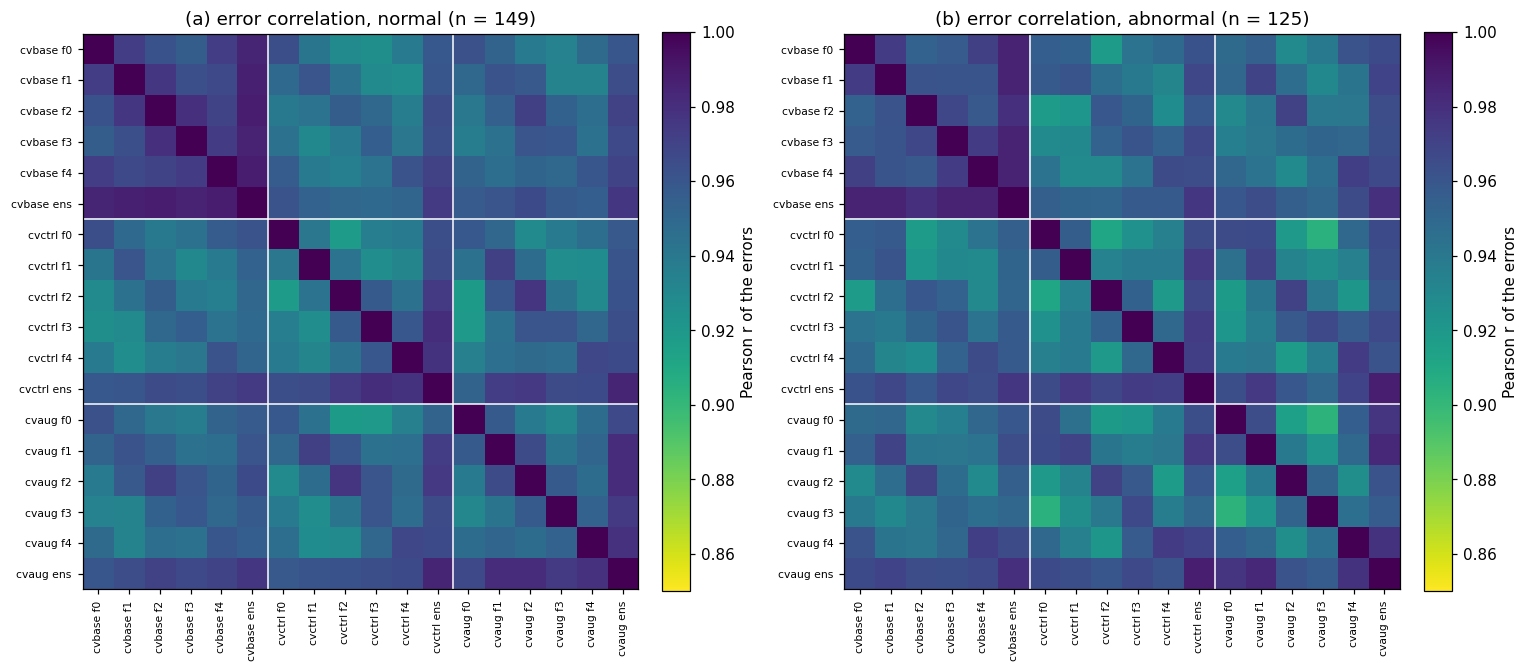

In [40]:
if preds is not None and HAVE_TUEG:
    fig, axes = plt.subplots(1, 2, figsize=(14, 6.4))
    err = wide.sub(test_true.loc[wide.index], axis=0)
    for ax, status in zip(axes, ("normal", "abnormal")):
        idx = wide.index[test_status.loc[wide.index] == status]
        r = err.loc[idx].corr()
        im = ax.imshow(r.to_numpy(), vmin=0.85, vmax=1.0, cmap="viridis_r")
        ax.set_xticks(range(len(r)), r.columns, rotation=90, fontsize=7)
        ax.set_yticks(range(len(r)), r.index, fontsize=7)
        for k in (6, 12):
            ax.axhline(k - 0.5, color="w", lw=1)
            ax.axvline(k - 0.5, color="w", lw=1)
        ax.grid(False)
        ax.set_title(f"error correlation, {status} (n = {len(idx)})")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Pearson r of the errors")
    fig.tight_layout()
    panel_labels(list(axes))
    assert_max_columns(fig)
    plt.show()

### Figure 3.3. Per-recording agreement of the three experiments

TUAB test recordings, coloured by status: green normal, red abnormal. Errors $e = \hat y - y$ are in
years.
* (a)–(c) The error of one experiment's ensemble against another's, for each pair of experiments. A
  point on the dashed diagonal means both models made the same error. A point in the upper-right or
  lower-left quadrant means both erred in the same direction.
* (d) **Disagreement per recording:** the sample standard deviation of the 15 fold models'
  predictions (3 experiments × 5 folds), against the true age.

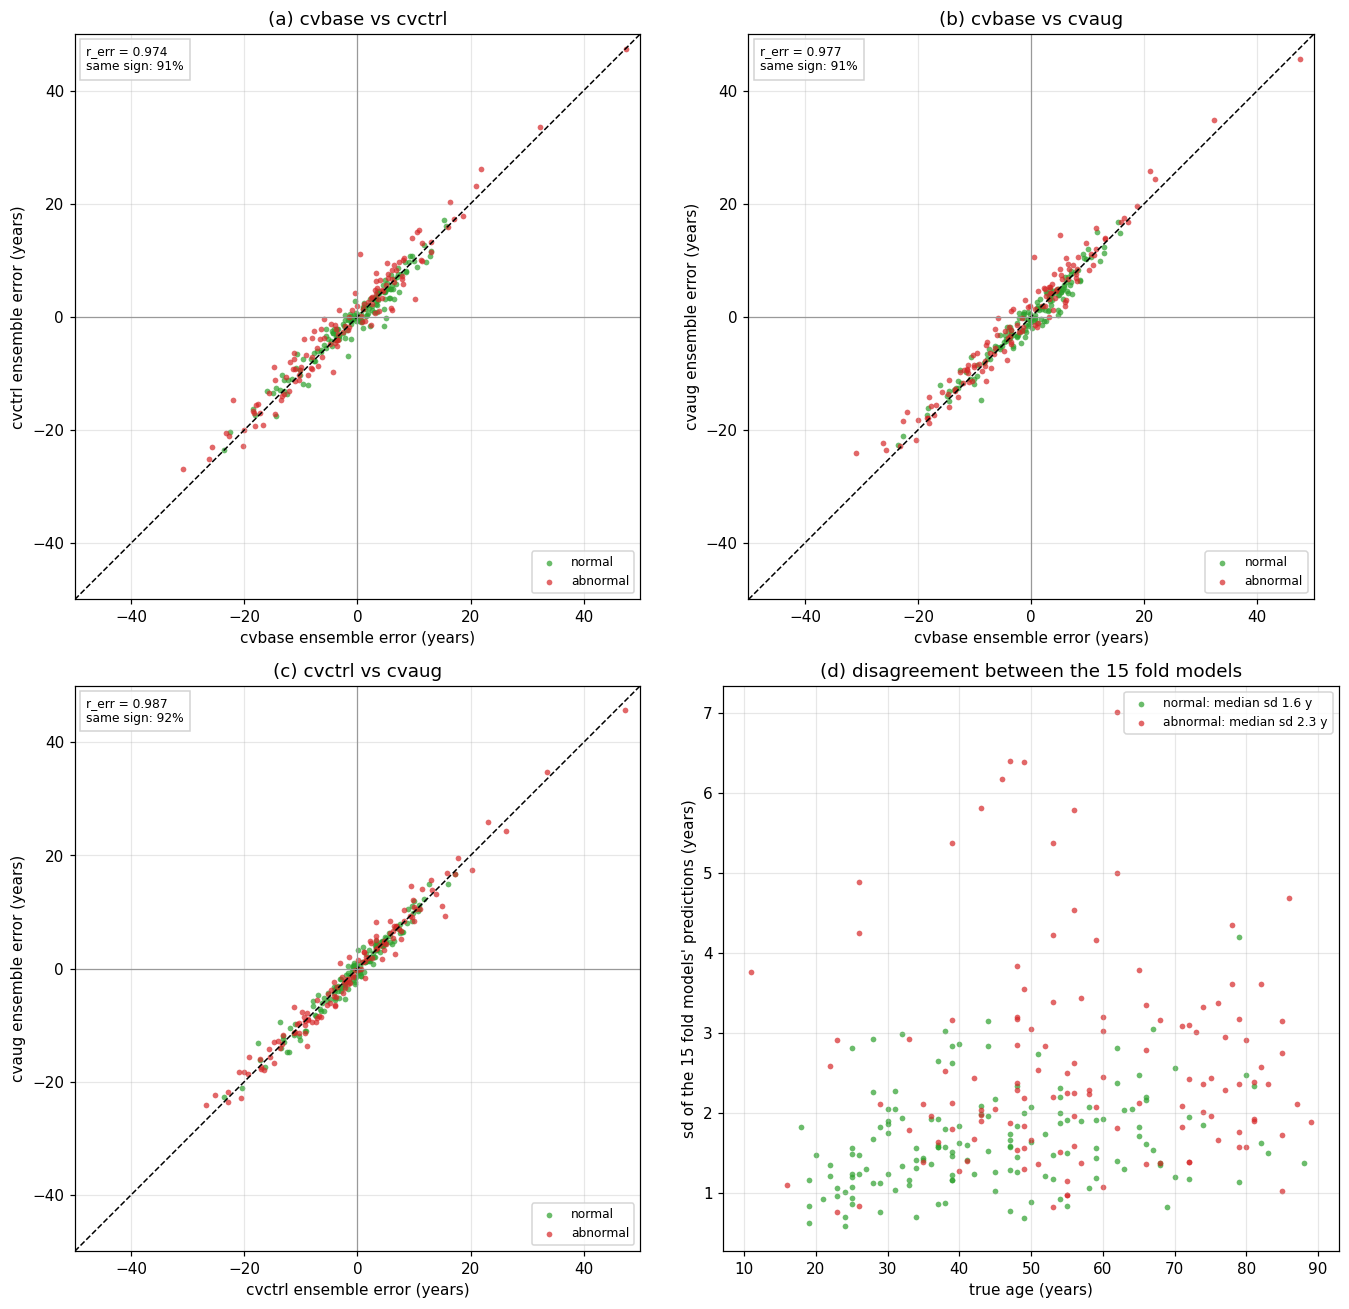

In [41]:
if preds is not None and HAVE_TUEG:
    SCOL = {"normal": "tab:green", "abnormal": "tab:red"}
    fig, axes = plt.subplots(2, 2, figsize=(12.5, 12))
    pairs = [("cvbase", "cvctrl"), ("cvbase", "cvaug"), ("cvctrl", "cvaug")]
    st = test_status.loc[wide.index]
    for ax, (a, b) in zip(axes.ravel()[:3], pairs):
        ea, eb = err[f"{a} ens"], err[f"{b} ens"]
        for status, col in SCOL.items():
            m = st == status
            ax.scatter(ea[m], eb[m], s=14, alpha=0.7, color=col, lw=0, label=status)
        lim = float(np.ceil(max(ea.abs().max(), eb.abs().max()) / 5) * 5)
        ax.plot([-lim, lim], [-lim, lim], ls="--", color="k", lw=1)
        ax.axhline(0, color="0.6", lw=0.8)
        ax.axvline(0, color="0.6", lw=0.8)
        ax.set_xlim(-lim, lim)
        ax.set_ylim(-lim, lim)
        ax.set_aspect("equal")
        r = float(np.corrcoef(ea, eb)[0, 1])
        ax.text(0.02, 0.98, f"r_err = {r:.3f}\nsame sign: {np.mean(np.sign(ea) == np.sign(eb)):.0%}",
                transform=ax.transAxes, va="top", fontsize=8,
                bbox=dict(facecolor="white", alpha=0.85, edgecolor="0.8"))
        ax.set_xlabel(f"{a} ensemble error (years)")
        ax.set_ylabel(f"{b} ensemble error (years)")
        ax.set_title(f"{a} vs {b}")
        ax.legend(loc="lower right", fontsize=8)
    ax = axes[1, 1]
    folds = wide[[c for c in wide.columns if " f" in c]]
    spread = folds.std(axis=1, ddof=1)
    for status, col in SCOL.items():
        m = st == status
        ax.scatter(test_true.loc[wide.index][m], spread[m], s=14, alpha=0.7, color=col, lw=0,
                   label=f"{status}: median sd {spread[m].median():.1f} y")
    ax.set_xlabel("true age (years)")
    ax.set_ylabel("sd of the 15 fold models' predictions (years)")
    ax.set_title("disagreement between the 15 fold models")
    ax.legend(fontsize=8)
    fig.tight_layout()
    panel_labels(list(axes.ravel()))
    assert_max_columns(fig)
    plt.show()

**Reading Table 3.7 and Figures 3.2 and 3.3.**
* **The three experiments make almost the same errors.** Their ensembles' errors correlate at
  r = 0.974–0.987 (Figure 3.2, Figure 3.3(a)–(c)). On 91–92 % of the recordings both err in the same
  direction, and on 96–99 % they predict within 5 years of each other. The differences in MAE between
  them (Table 2.7) come from small shifts, not from different recordings going wrong.
* **The ensembles agree more than single fold models do.** The ensemble pairs agree more closely across
  experiments (r_err 0.97–0.99, within 2 years on 69–82 % of recordings) than two fold models of the same
  experiment (r_err 0.94–0.97, 52–67 %). Averaging five models removes much of the fold-to-fold noise,
  which is why the ensemble beats a single model (Table 5.2, C3).
* **Abnormal recordings: shared errors, more disagreement.** The models agree on the error direction
  more often on abnormal recordings: 93–96 % same sign, against 89–90 % on normal ones. But their
  predictions spread more there, with fewer abnormal recordings within 2 years (56–73 %, against
  81–90 %). The fold models also disagree more on abnormal recordings (Figure 3.3(d)).
* **The largest errors are shared.** In Figure 3.3(a)–(c), the points far from the origin lie near the
  diagonal: the recordings that one model gets badly wrong, all models get badly wrong. Of the 20
  largest `cvctrl` test errors, 16 are abnormal recordings (46 % of the test set is abnormal), and
  17 are patients under 30 or over 70. These recordings are the main lever left for improving the
  MAE.

## 4. Changes versus the LaBraM recipe

The reference is **LaBraM as published for TUAB**, `labram/configs/defaults/finetune_tuab_paper.json`:
* LaBraM-base fine-tuned for normal/abnormal classification, the recipe of the paper and the README;
* lr $5\cdot10^{-4}$, batch 64, 50 epochs with 5 warmup, layer decay 0.65, drop path 0.1;
* no input re-referencing;
* a 50 Hz notch in preprocessing (`dataset_maker/make_TUAB.py`).

Table 4.1 lists every configuration field the best configuration changes. Table 4.2 lists the changes
that live in the data or the code rather than the configuration. Section 5 then tests which of them
moved the error.

### Table 4.1. Configuration changes: LaBraM TUAB recipe → best configuration

Every field on which `finetune_tuab_paper.json` and `cvctrl` (Table 3.1) differ, computed by
`labram/eval/research_summary.py::config_diff`. Excluded:
* bookkeeping fields (paths, logging, infrastructure);
* fields a regression run never reads (`INERT_FOR_REGRESSION`);
* fields of a section that is off in both.

Columns:
* `group`: the part of the pipeline;
* `meaning`: what the change does;
* `evidence`: the rows of Table 5.2 that test it, where one does.

In [42]:
MEANING = {
    "data.dataset": ("task", "age regression on TUH (TUAB_AGE loader) instead of normal/abnormal", ""),
    "data.data_format": ("data", "storage only: one float32 npy per recording, windows bit-identical to the pickles", ""),
    "model.task": ("task", "scalar regression head (Huber on z-scored age, Eqs. (3.2), (3.4))", ""),
    "labram_plus.enabled": ("input", "turns on the LaBraM++ input block (Eq. (3.1))", "P1"),
    "labram_plus.z_score_patches": ("input", "LaBraM++ block with CAR only, no per-patch z-scoring", "P1"),
    "data.trim_start_sec": ("windows", "drop the first 60 s of every recording", ""),
    "data.trim_end_sec": ("windows", "drop the last 60 s of every recording", ""),
    "data.eval_minutes": ("windows", "score each recording on its first 5 minutes after the trim", "P26"),
    "data.train_minutes_per_epoch": ("windows", "5 minutes per recording per epoch, redrawn each epoch (speed)", "Q14"),
    "evaluation.agg_windows": ("scoring", "one prediction per recording = mean of its windows (Eq. (3.7))", ""),
    "mixup.enabled": ("augmentation", "mixup α 0.4 (Eq. (3.3))", "P3"),
    "optimizer.lr": ("optimizer", "2e-4 at batch 128 = 1e-4 at batch 64, linearly scaled", "Q14"),
    "trainer.batch_size": ("optimizer", "batch 128 (speed; lr scaled with it)", "Q14"),
    "optimizer.warmup_epochs": ("schedule", "3 warmup epochs", "P2, Q6, C1"),
    "trainer.epochs": ("schedule", "10 epochs instead of 50 (best epoch is early)", "P2, Q6, C1"),
    "model.use_mean_pooling": ("head", "head on the class token instead of the mean patch token", "P22, Q13, C1"),
    "model.session_features": ("head", "status + pathology vector concatenated to the feature (Eq. (3.6))", "Q12, C1"),
    "data.session_features": ("head", "the condition vectors' file (conditions_v1.npz)", "Q12, C1"),
    "channel_drop.enabled": ("channels", "per-sample handling of missing T1/T2 (needed for cohort v3)", "Q14"),
    "channel_drop.channels": ("channels", "T1/T2 are the channels that may be missing", "Q14"),
    "channel_drop.max_drop": ("channels", "up to both of T1/T2", "Q14"),
    "channel_drop.prob": ("channels", "0: no channel-dropout augmentation in cvctrl", "Q17, C2"),
    "channel_drop.consistency_weight": ("channels", "0: no consistency loss in cvctrl", "Q17, C2"),
    "cross_validation.enabled": ("protocol", "5-fold patient-grouped cross-validation", "C3"),
    "model.fused_attention": ("speed", "fused attention kernel, numerically the same model", ""),
}
t41 = rs.config_diff(paper, best, ("LaBraM recipe", "best (cvctrl)"),
                     ignore=rs.NON_SCIENTIFIC + rs.INERT_FOR_REGRESSION)
t41["group"] = t41.field.map(lambda f: MEANING.get(f, ("?", "", ""))[0])
t41["meaning"] = t41.field.map(lambda f: MEANING.get(f, ("", "(not annotated)", ""))[1])
t41["evidence"] = t41.field.map(lambda f: MEANING.get(f, ("", "", ""))[2])
missing = sorted(set(t41.field) - set(MEANING))
assert not missing, f"annotate these fields in MEANING: {missing}"
t41 = t41.sort_values(["group", "field"]).set_index(["group", "field"])
numbered_table(t41, "4.1", "Configuration changes versus the LaBraM TUAB recipe")

### Table 4.2. Changes outside the configuration

Changes in the training data, the preprocessing, the split and the code, with the Table 5.2 rows that
test them.

| change | LaBraM recipe | this study | evidence |
|---|---|---|---|
| training data | TUAB train, 2,145 recordings (≈1.6k patients) | TUAB + TUEG, 25,613 recordings (≈12k patients, `all_both_v3`) | Q1, Q3 |
| mains interference | 50 Hz notch (TUH is recorded at 60 Hz, so the line stays in) | 50 + 60 Hz spectrum interpolation | L1 |
| channels | 23 fixed channels | 23; TUEG recordings missing only T1/T2 kept, with those channels left out per sample | Q14 |
| validation split | TUAB's train split, which leaks 16 patients between train and val | patient-disjoint, seeded; one TUEG patient split shared by all cohorts; TUAB-test patients removed from TUEG | Q11 |
| label | normal/abnormal | age from the EDF header (18–89 in the TUH cohorts) | – |
| unit of evaluation | 10 s window | recording (Eq. (3.7)), first 5 minutes after the trim | P26 |
| per-patient cap | none | at most 10 train/val recordings per patient | – |
| reported model | one run | median of 5 fold models (Eq. (3.8)) | C3 |
| reproducibility | ClearML silently reseeded every tracked run to 1337 | fixed: `distributed.seed` is honoured (commit `7b9a5fe`) | – |

## 5. Which changes mattered

**Noise floor.** Two runs of the same configuration with different seeds do not give the same MAE. The
line-removal A/B study ran each of 3 preprocessing recipes $r$ with 3 seeds $s$, and each run is read
at its best-validation epoch. The pooled within-recipe sample standard deviation of a metric $m$
(`labram/eval/research_summary.py::seed_noise`) is

$$ \hat\sigma_m^2 = \frac{1}{N - R}\sum_{r}\sum_{s}\big(m_{r,s} - \bar m_r\big)^2 \tag{5.1} $$

with $N = 9$ runs and $R = 3$ recipes.

**Significance rule.** Each row of Table 5.2 compares a baseline with a variant that changes one thing
(or a named bundle), using whichever evidence exists:

* **One run each** (phases 1 and 2). The difference of two single runs has standard deviation
  $\sqrt2\,\hat\sigma$, so a change counts only if (`rs.pair_threshold`)

  $$ \lvert\Delta\mathrm{MAE}\rvert > \tau = 1.96\,\sqrt2\,\hat\sigma_{\text{test}}. \tag{5.2} $$

* **Three seeds each** (line removal, L1/L2):

  $$ \lvert \bar\Delta \rvert > 1.96\,\hat\sigma_{\text{test}}\,\sqrt{2/3}. \tag{5.3} $$

* **Five paired folds** (CV, C1/C2). Fold $k$ gives $\Delta_k$ on the same TUAB test recordings, and
  the 95 % interval is

  $$ \bar\Delta \pm t_{0.975,\,4}\,\frac{s_\Delta}{\sqrt5}, \qquad t_{0.975,\,4} = 2.776, \tag{5.4} $$

  where $\bar\Delta$ and $s_\Delta$ are the mean and sample sd of the $\Delta_k$. The change counts if
  the interval excludes 0.

* **Ensemble vs single model** (C3). A paired bootstrap over recordings (2,000 resamples,
  `cv_compare.py::bootstrap_delta_mae`) of the ensemble's absolute error against the fold models' mean
  absolute error. The change counts if its 95 % interval excludes 0.

The verdict is `improves` / `hurts` / `n.s.` (`rs.verdict`). It is judged on the TUAB test MAE of all
274 recordings, the one set every run shares; the val and cohort columns are context.

**Limits.**
* $\hat\sigma$ is measured on one configuration, the E2 recipe on TUAB (Table 5.1), and assumed to hold
  for the others.
* A single-split row with $\lvert\Delta\rvert$ just under $\tau$ is not evidence of no effect, only of
  no detectable one.
* Several rows change more than one thing at once; they are marked *bundle*.

### Table 5.1. Seed-to-seed spread

**The model.** All 9 runs train the same model with the same recipe, **E2**: scenario D
(`finetune_tuab_age.json`) on the short schedule. Read from each run's ClearML configuration:
* **Encoder:** LaBraM-base (`labram_base_patch200_200`, 12 transformer blocks), initialized from the
  released `labram-base.pth`, all layers fine-tuned.
* **Input and head:** CAR input (Eq. (3.1)), mean patch-token pooling and a linear head.
* **Loss and optimizer:** Huber $\delta = 1$ on the z-scored age (Eq. (2.3)), no mixup. AdamW with lr
  $10^{-4}$, batch 64, weight decay 0.05, layer decay 0.65 and drop path 0.1.
* **Schedule and evaluation:** 4 epochs with 1 warmup, scored on the first 5 minutes of each recording
  after the 60 s trims.

**What varies.** The data is TUAB v3.0.1, on the same recordings and the same subject-disjoint split as
phase 1 (Table 1.5). Only two things change:
* **Preprocessing:** the mains-interference removal, 3 variants. A is the 50 Hz notch (LaBraM as
  published), B a 60 Hz notch, C 50 + 60 Hz spectrum interpolation.
* **Seed:** 3 seeds per variant, which change the head initialization, the batch order, dropout and drop
  path. Seed 0 ran on a local g5.2xlarge; seeds 1 and 2 ran as SageMaker jobs on ml.g5.2xlarge
  (`scripts/submit_line_removal_ab.sh`).

Within a variant, the three runs differ only by the seed, which is what Eq. (5.1) pools. Each run is
read at its best-validation epoch (`docs/data/line_removal_ab.json`). The table then gives the pooled
standard deviation of Eq. (5.1) per metric and the single-pair threshold $\tau$ of Eq. (5.2).

Columns:
* `val_mae`: the TUAB validation split.
* `test_mae`, `test_normal_mae`, `test_abnormal_mae`: TUAB test, overall and per cohort.


In [43]:
ab_runs, SD = rs.seed_noise(AB_JSON)
TAU = rs.pair_threshold(SD["test_mae"])
display(numbered_table(ab_runs.set_index(["variant", "seed"]), "5.1", "Seed-to-seed spread"))
print("pooled seed sd (years): " + ", ".join(f"{k} {v:.3f}" for k, v in SD.items()))
print(f"single-pair threshold τ on TUAB test (Eq. 5.2): {TAU:.2f} years; "
      f"3-vs-3-seed threshold (Eq. 5.3): {1.96 * SD['test_mae'] * (2 / 3) ** 0.5:.2f} years")

pooled seed sd (years): val_mae 0.061, test_mae 0.138, test_normal_mae 0.100, test_abnormal_mae 0.194
single-pair threshold τ on TUAB test (Eq. 5.2): 0.38 years; 3-vs-3-seed threshold (Eq. 5.3): 0.22 years


### Table 5.2. Effect of each change

One row per tested change. Columns:
* `id`: the row's id, cited in Tables 4.1, 4.2 and 5.3.
* `phase`: 1 (registry, Table 2.2), 2 (Table 2.5), L (line-removal A/B, Table 5.1), C (CV, Table 2.7).
* `baseline → variant`: the two runs compared; `bundle` marks a change of several things at once.
* `Δ val`: Eq. (0.4) on the validation set the two runs share (phase 1: TUAB val; phase 2: TUEG val v2
  where both runs were scored on it).
* `Δ test`, `Δ normal`, `Δ abnormal`: Eq. (0.4) on TUAB test, overall and per cohort.
* `noise`: $\pm\tau$ (Eqs. (5.2), (5.3)) or the 95 % interval (Eq. (5.4) / bootstrap).
* `verdict`: the rule above, on `Δ test`.

In [44]:
EVIDENCE = [
    # id, phase, change, baseline, variant, bundle
    ("P1", "1", "common average reference on the input", "B", "D", False),
    ("P26", "1", "score the first 5 min instead of whole recordings", "A", "B", False),
    ("P2", "1", "4 epochs / 1 warmup instead of 15 / 2", "D", "E2", False),
    ("P3", "1", "mixup α 0.4", "E2", "M1", False),
    ("P4", "1", "C-Mixup (σ 5 y)", "E2", "M1c", False),
    ("P5", "1", "EMA weights for evaluation", "E2", "M2", False),
    ("P6", "1", "layer decay 0.5 (stronger)", "E2", "F1", False),
    ("P7", "1", "layer decay 0.75 (weaker)", "E2", "H1", False),
    ("P8", "1", "dropout 0.1", "E2", "F2", False),
    ("P9", "1", "drop path 0.2", "E2", "F3", False),
    ("P10", "1", "weight decay 0.1", "E2", "F4", False),
    ("P11", "1", "head init scale 1.0", "E2", "G1", False),
    ("P12", "1", "LoRA r16 instead of full fine-tuning", "E2", "M3", True),
    ("P13", "1", "L1 loss instead of Huber", "B", "D2", False),
    ("P14", "1", "Huber δ 2", "D", "DX2", False),
    ("P15", "1", "soft labels (σ 2.5 y)", "E2", "M4", False),
    ("P16", "1", "age-balanced loss (sqrt-inverse)", "E2", "B1", False),
    ("P17", "1", "codebook amplitude reconstruction", "D", "DX1", False),
    ("P18", "1", "codebook quantization term", "D", "DX4", False),
    ("P19", "1", "30 s windows instead of 10 s", "B", "C", False),
    ("P20", "1", "random crop", "D", "E1", False),
    ("P21", "1", "gradient clipping 1.0", "D", "D-clip1", False),
    ("P22", "1", "class token instead of mean pooling", "D", "D-cls", False),
    ("P23", "1", "[mean ; class token] concatenated", "D", "D-clsmean", False),
    ("P24", "1", "multi-task head (age + normal/abnormal)", "M1", "MT1", False),
    ("P25", "1", "pretrained LaBraM weights instead of training from scratch", "S1", "D", False),
    ("L1", "L", "50 + 60 Hz interpolation instead of 50 Hz notch", "A_notch50", "C_interp5060", False),
    ("L2", "L", "60 Hz notch instead of 50 Hz notch", "A_notch50", "B_notch60", False),
    ("Q1", "2", "add every TUEG recording (~10x data)", "Control", "Exp3", False),
    ("Q2", "2", "train on normal recordings only (TUAB + TUEG)", "Control", "Exp1", True),
    ("Q3", "2", "add abnormal + unlabelled recordings to normal-only", "Exp1", "Exp3", False),
    ("Q4", "2", "TUEG normal only (no TUAB in training)", "Exp1", "Exp2", False),
    ("Q5", "2", "10 / 3 epochs on the normal cohort", "Exp1", "Exp1b", False),
    ("Q6", "2", "10 / 3 epochs on the all cohort", "Exp3", "Exp3b", False),
    ("Q7", "2", "window rejection (±800 µV, flat channel)", "Exp3", "Exp3q", False),
    ("Q8", "2", "input clip ±800 µV", "Exp3", "Exp3c", False),
    ("Q9", "2", "classical features as transformer tokens", "Exp1", "Exp1t", False),
    ("Q10", "2", "classical features only, no EEG encoder", "Exp1", "Exp1f", False),
    ("Q11", "2", "shared TUEG patient split (v2)", "Exp3", "Exp3v2", False),
    ("Q12", "2", "status + pathology condition vectors", "Exp3v2", "Exp3cond", False),
    ("Q13", "2", "class token (with conditions)", "Exp3cond", "Exp3clscond", False),
    ("Q14", "2", "cohort v3 + missing-T1/T2 handling + speed settings", "Exp3v2", "Exp4base", True),
    ("Q15", "2", "compact copy of the cohort (reproduction)", "Exp4base", "Exp4basec", False),
    ("Q16", "2", "class token + conditions + 10 ep with early stopping", "Exp4base", "Exp4ctrl", True),
    ("Q17", "2", "T1/T2 dropout + consistency (6 vs 10 epochs)", "Exp4ctrl", "Exp4aug", True),
    ("Q18", "2", "T1/T2 dropped everywhere (21 channels) + cohort v3", "Exp3cond", "Exp4drop", True),
    ("Q19", "2", "15 / 5 epochs with early stopping (aug)", "Exp4aug", "Exp4aug15", False),
    ("C1", "C", "class token + conditions + 10 / 3 epochs (CV)", "cvbase", "cvctrl", True),
    ("C2", "C", "T1/T2 dropout + consistency λ 0.1 (CV)", "cvctrl", "cvaug", False),
    ("C3", "C", "median of 5 fold models instead of one (cvctrl)", "cvctrl single", "cvctrl ensemble", False),
    ("C3b", "C", "median of 5 fold models instead of one (cvbase)", "cvbase single", "cvbase ensemble", False),
]
R = reg.set_index("run")
ab = ab_runs.groupby("variant")[["val_mae", "test_mae", "test_normal_mae", "test_abnormal_mae"]].mean()
T3 = 1.96 * SD["test_mae"] * (2 / 3) ** 0.5


def fold_deltas(a, b, split="heldout", source="TUAB", cohort="all"):
    def per_fold(e):
        s = cv[(cv.exp == e) & (cv.split == split) & (cv.source == source) & (cv.cohort == cohort)]
        return s.drop_duplicates("fold").set_index("fold").MAE
    d = (per_fold(b) - per_fold(a)).dropna()
    half = 2.776 * d.std(ddof=1) / np.sqrt(len(d))
    return float(d.mean()), float(d.mean() - half), float(d.mean() + half), int((d < 0).sum()), len(d)


rows = []
for eid, phase, change, a, b, bundle in EVIDENCE:
    r = {"id": eid, "phase": phase, "change": change + (" (bundle)" if bundle else ""), "baseline → variant": f"{a} → {b}"}
    lo = hi = None
    if phase == "1":
        r.update({"Δ val": R.loc[b, "val"] - R.loc[a, "val"], "Δ test": R.loc[b, "test"] - R.loc[a, "test"],
                  "Δ normal": R.loc[b, "test_normal"] - R.loc[a, "test_normal"],
                  "Δ abnormal": R.loc[b, "test_abnormal"] - R.loc[a, "test_abnormal"]})
        r["noise"], thr = f"± {TAU:.2f}", TAU
    elif phase == "L":
        r.update({"Δ val": ab.loc[b, "val_mae"] - ab.loc[a, "val_mae"], "Δ test": ab.loc[b, "test_mae"] - ab.loc[a, "test_mae"],
                  "Δ normal": ab.loc[b, "test_normal_mae"] - ab.loc[a, "test_normal_mae"],
                  "Δ abnormal": ab.loc[b, "test_abnormal_mae"] - ab.loc[a, "test_abnormal_mae"]})
        r["noise"], thr = f"± {T3:.2f}", T3
    elif phase == "2":
        g = lambda m, sp, so, c: cohort_metric(m, sp, so, c)
        r.update({"Δ val": g(b, "val_v2", "TUEG", "all") - g(a, "val_v2", "TUEG", "all"),
                  "Δ test": g(b, "test", "TUAB", "all") - g(a, "test", "TUAB", "all"),
                  "Δ normal": g(b, "test", "TUAB", "normal") - g(a, "test", "TUAB", "normal"),
                  "Δ abnormal": g(b, "test", "TUAB", "abnormal") - g(a, "test", "TUAB", "abnormal")})
        r["noise"], thr = f"± {TAU:.2f}", TAU
    elif eid in ("C1", "C2"):
        m, lo, hi, wins, k = fold_deltas(a, b)
        r.update({"Δ val": fold_deltas(a, b, "val", "all")[0], "Δ test": m,
                  "Δ normal": fold_deltas(a, b, cohort="normal")[0], "Δ abnormal": fold_deltas(a, b, cohort="abnormal")[0]})
        r["noise"], thr = f"[{lo:+.2f}, {hi:+.2f}], better in {wins}/{k} folds", None
    else:                                       # C3: ensemble vs the single fold models
        exp = a.split()[0]
        if preds is None or not STATUS:
            r.update({"Δ test": np.nan, "noise": "needs per-recording predictions"})
            rows.append(r)
            continue
        e = ensemble(exp).set_index("stem")
        single = preds[(preds.exp == exp) & (preds.split == "heldout")].assign(ae=lambda x: x.err.abs())
        mean_ae = single.groupby("stem").ae.mean().loc[e.index]
        bs = cc.bootstrap_delta_mae(e.err.to_numpy(), mean_ae.to_numpy())
        def by(c):
            m = e.status == c
            return float(e.err[m].abs().mean() - mean_ae[m].mean())
        r.update({"Δ test": bs["dMAE"], "Δ normal": by("normal"), "Δ abnormal": by("abnormal")})
        lo, hi = bs["lo"], bs["hi"]
        r["noise"], thr = f"[{lo:+.2f}, {hi:+.2f}] (bootstrap)", None
    r["verdict"] = rs.verdict(r["Δ test"], thr if thr is not None else 0.0, lo, hi)
    rows.append(r)
t52 = pd.DataFrame(rows).set_index("id")
numbered_table(t52, "5.2", "Effect of each change")

,phase,change,baseline → variant,Δ val,Δ test,Δ normal,Δ abnormal,noise,verdict
id,,,,,,,,,
P1,1,common average reference on the input,B → D,-0.63,-0.61,–,–,± 0.38,improves
P26,1,score the first 5 min instead of whole recordings,A → B,0.11,-0.12,–,–,± 0.38,n.s.
P2,1,4 epochs / 1 warmup instead of 15 / 2,D → E2,-0.09,-0.05,–,–,± 0.38,n.s.
P3,1,mixup α 0.4,E2 → M1,-0.22,0.20,–,–,± 0.38,n.s.
P4,1,C-Mixup (σ 5 y),E2 → M1c,-0.14,-0.02,–,–,± 0.38,n.s.
P5,1,EMA weights for evaluation,E2 → M2,-0.10,-0.08,–,–,± 0.38,n.s.
P6,1,layer decay 0.5 (stronger),E2 → F1,0.06,0.11,–,–,± 0.38,n.s.
P7,1,layer decay 0.75 (weaker),E2 → H1,0.03,0.42,–,–,± 0.38,hurts
P8,1,dropout 0.1,E2 → F2,5.57,6.92,–,–,± 0.38,hurts


### Figure 5.1. Effect sizes

**What is plotted.** One row per tested change (Table 5.2). The point is how much that change moved the
TUAB test MAE, Eq. (0.4):

$$ \Delta\mathrm{MAE} = \mathrm{MAE}(\text{run with the change}) - \mathrm{MAE}(\text{run without it}), $$

in years, on all 274 test recordings. The two runs are named in brackets in the row label
(baseline → variant).

This is a **difference of two errors, not a prediction error**. A point at −0.5 means the change made
the model 0.5 years more accurate. It does not mean the model predicts ages 0.5 years too low.
* **Left of 0:** the change lowered the error, so it helped. Further left is better.
* **At 0:** no effect.
* **Right of 0:** the change raised the error, so it hurt.

**Bars and colours.**
* The horizontal bar is the noise band: how far two runs differing only by chance would land apart.
  It is $\pm\tau$ (Eq. (5.2)) for single runs and 3-seed pairs, and the 95 % interval (Eq. (5.4) or
  the bootstrap) for CV and ensemble rows.
* **Green (`improves`):** the whole band lies left of 0, so the gain is larger than seed noise.
* **Red (`hurts`):** the whole band lies right of 0.
* **Grey (`n.s.`):** the band crosses 0. The effect cannot be told apart from noise.

Changes beyond ±2 years (collapsed runs) are drawn at the edge, with their value written next to
them. Panels:
* (a) Phase 1, TUAB-only runs.
* (b) Line removal, phase 2 and CV.

The signed drift of the predictions themselves, mean(predicted − true), where closer to 0 is better,
is the bias of Eq. (0.3). It is shown per model and status in Table 3.4 (`bias`) and in Figure 3.1.

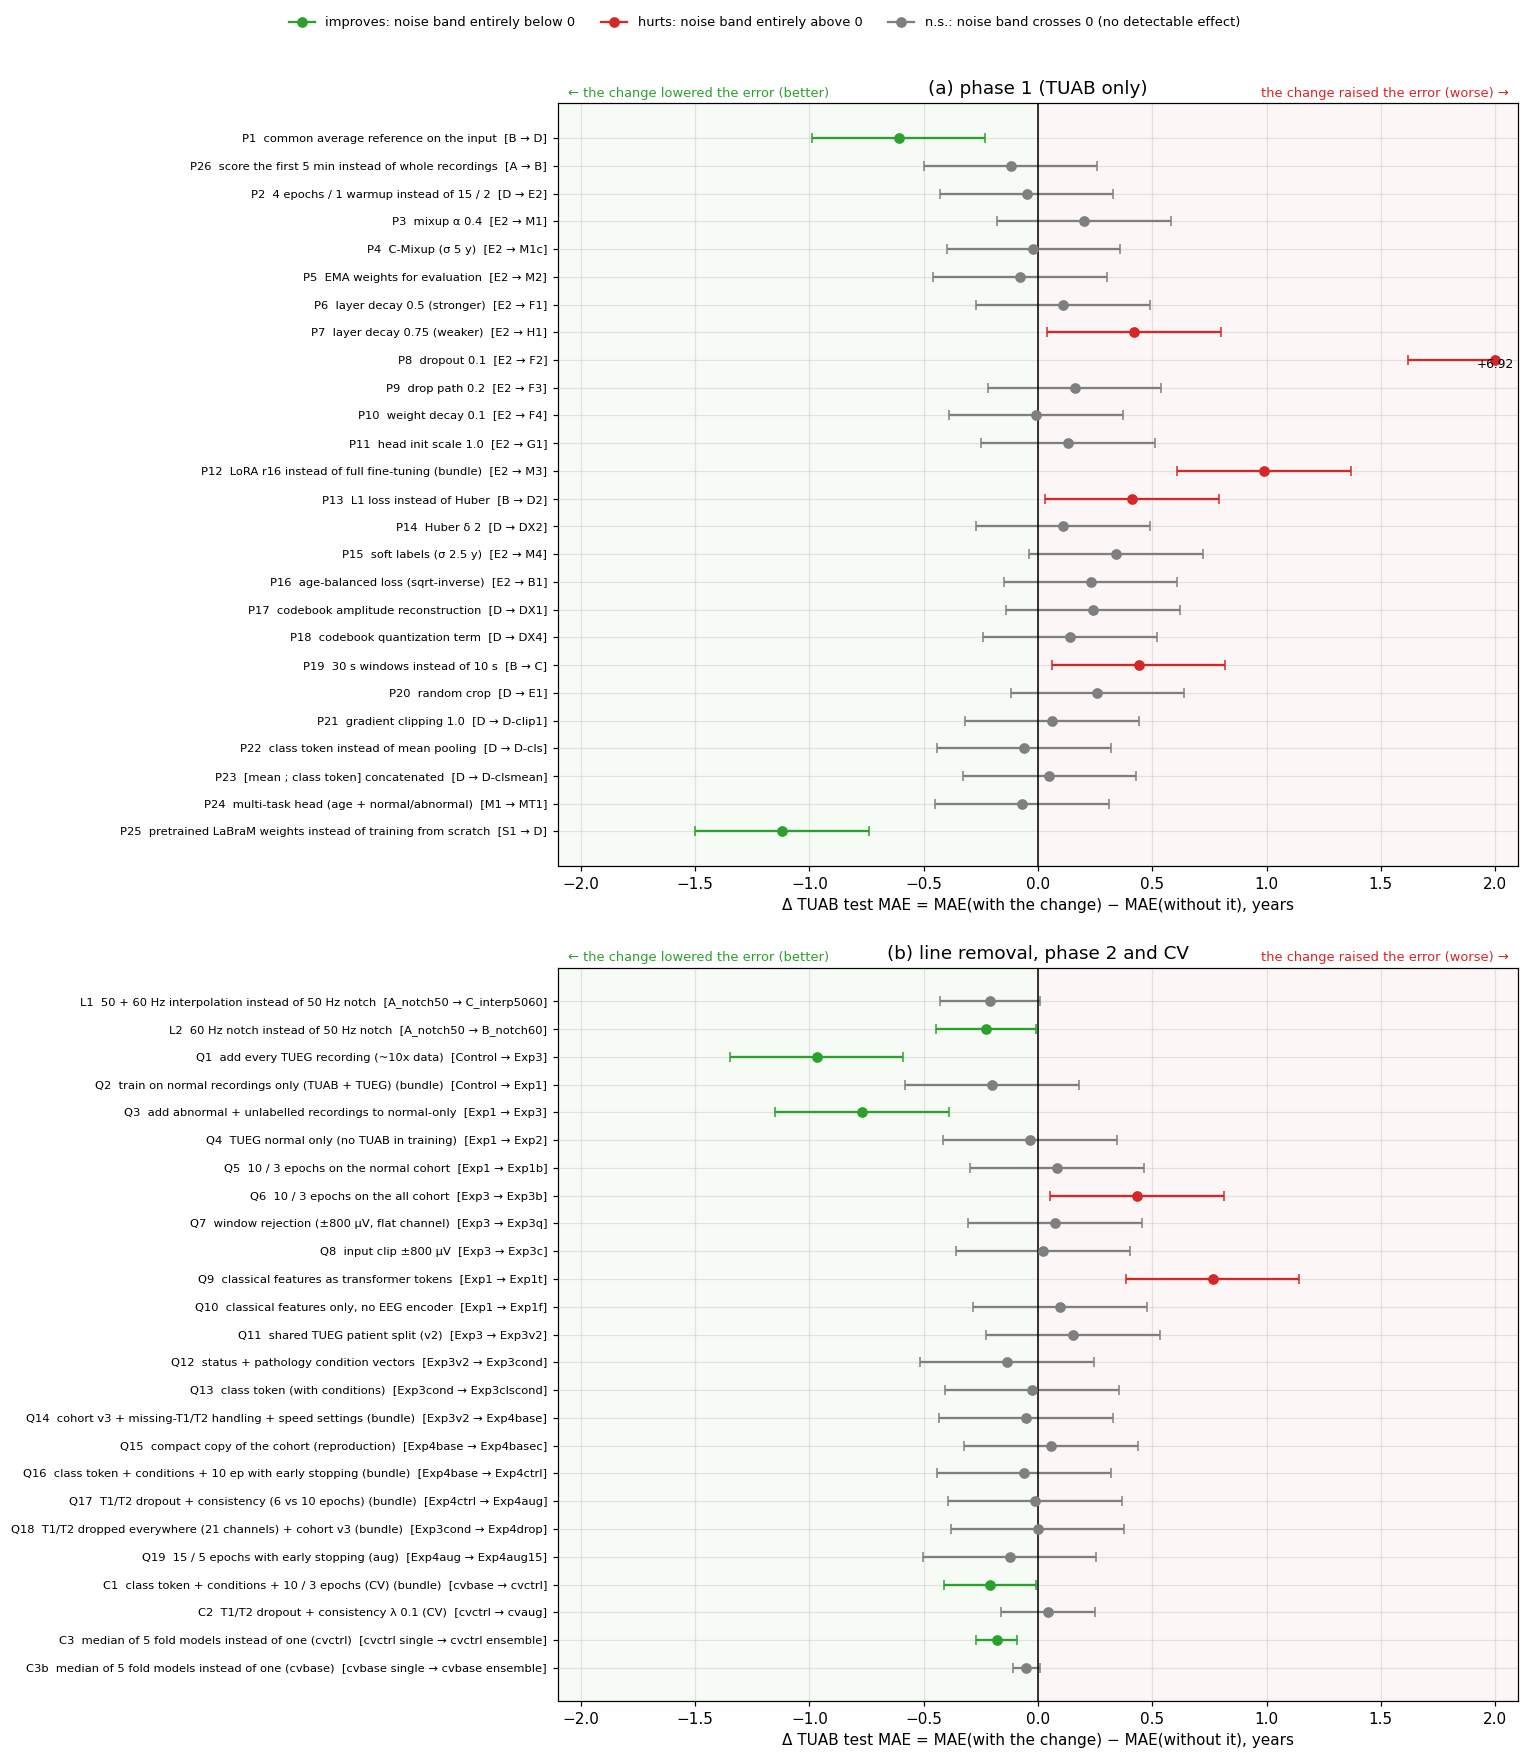

In [45]:
from matplotlib.lines import Line2D


def band(row):
    s = row["noise"]
    if isinstance(s, str) and s.startswith("["):
        lo, hi = (float(v) for v in s[1:s.index("]")].split(","))
        return row["Δ test"] - lo, hi - row["Δ test"]
    w = float(s.split()[-1]) if isinstance(s, str) and s.startswith("±") else 0.0
    return w, w


COL = {"improves": "tab:green", "hurts": "tab:red", "n.s.": "tab:gray", "–": "tab:gray"}
LIM = 2.0
fig, axes = plt.subplots(2, 1, figsize=(14, 16), gridspec_kw={"height_ratios": [26, 25]})
for ax, phases, title in ((axes[0], ("1",), "phase 1 (TUAB only)"), (axes[1], ("L", "2", "C"), "line removal, phase 2 and CV")):
    sub = t52[t52.phase.isin(phases) & t52["Δ test"].notna()]
    ax.axvspan(-LIM - 0.1, 0, color="tab:green", alpha=0.04)
    ax.axvspan(0, LIM + 0.1, color="tab:red", alpha=0.04)
    for y, (eid, row) in enumerate(sub.iterrows()):
        d = row["Δ test"]
        lo, hi = band(row)
        x = float(np.clip(d, -LIM, LIM))
        ax.errorbar(x, y, xerr=[[min(lo, x + LIM)], [min(hi, LIM - x)]], fmt="o", color=COL[row.verdict], capsize=3)
        if abs(d) > LIM:
            ax.text(x, y + 0.3, f"{d:+.2f}", fontsize=8, ha="center")
    ax.set_yticks(range(len(sub)), [f"{i}  {c}  [{bv}]" for i, c, bv in
                                    zip(sub.index, sub.change, sub["baseline → variant"])], fontsize=7.5)
    ax.invert_yaxis()
    ax.axvline(0, color="k", lw=1)
    ax.set_xlim(-LIM - 0.1, LIM + 0.1)
    ax.set_xlabel("Δ TUAB test MAE = MAE(with the change) − MAE(without it), years")
    ax.text(0.01, 1.005, "← the change lowered the error (better)", transform=ax.transAxes, ha="left",
            va="bottom", fontsize=8.5, color="tab:green")
    ax.text(0.99, 1.005, "the change raised the error (worse) →", transform=ax.transAxes, ha="right",
            va="bottom", fontsize=8.5, color="tab:red")
    ax.set_title(title, pad=16)
handles = [Line2D([], [], color=COL[v], marker="o", ls="-", label=lab) for v, lab in
           (("improves", "improves: noise band entirely below 0"), ("hurts", "hurts: noise band entirely above 0"),
            ("n.s.", "n.s.: noise band crosses 0 (no detectable effect)"))]
fig.legend(handles=handles, loc="upper center", ncol=3, fontsize=8.5, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.975))
panel_labels(axes)
assert_max_columns(fig)
plt.show()

### Table 5.3. Changes versus LaBraM: which mattered

The summary the study was after. One row per change from the LaBraM TUAB recipe to the best
configuration (Tables 4.1 and 4.2), with:
* `estimate`: the Table 5.2 row that isolates the change best and its $\Delta$ test;
* `verdict`: that row's verdict;
* `in best config`: whether the change is part of `cvctrl`.

`not isolated` means no run changes it alone, so its effect is not known.

In [46]:
SUMMARY = [
    ("training data: TUAB → TUAB + TUEG (~10x recordings)", "Q1", "yes"),
    ("abnormal and unlabelled recordings in training", "Q3", "yes"),
    ("pretrained LaBraM weights (vs from scratch)", "P25", "yes"),
    ("common average reference on the input", "P1", "yes"),
    ("mains: 50 + 60 Hz interpolation instead of 50 Hz notch", "L1", "yes"),
    ("ensemble: median of the 5 fold models", "C3", "yes"),
    ("class token + condition vectors + 10 epochs (bundle)", "C1", "yes"),
    ("condition vectors alone (single split)", "Q12", "yes"),
    ("class-token pooling alone (TUAB / TUH)", "P22", "yes"),
    ("short schedule (4–10 epochs instead of 15–50)", "P2", "yes"),
    ("mixup α 0.4", "P3", "yes"),
    ("cohort v3 + missing-T1/T2 handling + speed settings (bundle)", "Q14", "yes"),
    ("5-minute evaluation window", "P26", "yes"),
    ("T1/T2 channel-dropout augmentation", "C2", "no (cvaug)"),
    ("longer schedule on the full cohort (10 epochs)", "Q6", "no"),
    ("dropout 0.1", "P8", "no"),
    ("weaker layer decay 0.75", "P7", "no"),
    ("LoRA instead of full fine-tuning", "P12", "no"),
    ("30 s windows", "P19", "no"),
    ("classical features as tokens", "Q9", "no"),
    ("L1 loss", "P13", "no"),
    ("weight decay, drop path, layer decay 0.5, head init", "P10", "no"),
    ("loss shape: Huber δ 2, soft labels, age-balanced", "P16", "no"),
    ("codebook regularization", "P18", "no"),
    ("signal QC: window rejection / ±800 µV clip", "Q7", "no"),
    ("multi-task head", "P24", "no"),
    ("trim 60 s at both ends; lr 1e-4 (vs 5e-4); batch 128", None, "yes"),
]
rows = []
for change, eid, used in SUMMARY:
    if eid is None:
        rows.append({"change vs LaBraM": change, "estimate": "–", "Δ test": np.nan, "verdict": "not isolated",
                     "in best config": used})
        continue
    r = t52.loc[eid]
    rows.append({"change vs LaBraM": change, "estimate": f"{eid}: {r['baseline → variant']}", "Δ test": r["Δ test"],
                 "verdict": r["verdict"], "in best config": used})
t53 = pd.DataFrame(rows).set_index("change vs LaBraM")
numbered_table(t53, "5.3", "Changes versus LaBraM: which mattered")

,estimate,Δ test,verdict,in best config
change vs LaBraM,,,,
training data: TUAB → TUAB + TUEG (~10x recordings),Q1: Control → Exp3,-0.97,improves,yes
abnormal and unlabelled recordings in training,Q3: Exp1 → Exp3,-0.77,improves,yes
pretrained LaBraM weights (vs from scratch),P25: S1 → D,-1.12,improves,yes
common average reference on the input,P1: B → D,-0.61,improves,yes
mains: 50 + 60 Hz interpolation instead of 50 Hz notch,L1: A_notch50 → C_interp5060,-0.21,n.s.,yes
ensemble: median of the 5 fold models,C3: cvctrl single → cvctrl ensemble,-0.18,improves,yes
class token + condition vectors + 10 epochs (bundle),C1: cvbase → cvctrl,-0.21,improves,yes
condition vectors alone (single split),Q12: Exp3v2 → Exp3cond,-0.14,n.s.,yes
class-token pooling alone (TUAB / TUH),P22: D → D-cls,-0.06,n.s.,yes


## 6. Conclusions

Generated from the tables above, so they stay in step with the data when the notebook is re-run.

In [47]:
v = t52.verdict
imp, hurt = t52[v == "improves"], t52[v == "hurts"]
m = lambda exp, c="all": fold_stats(exp, "heldout", "TUAB", c)
lines = [
    f"* **Noise floor.** Seed-to-seed sd of the TUAB test MAE is {SD['test_mae']:.2f} years (Table 5.1), so two "
    f"single runs must differ by more than {TAU:.2f} years to count (Eq. (5.2)). Of {len(t52)} tested changes, "
    f"{len(imp)} improve, {len(hurt)} hurt and {int((v == 'n.s.').sum())} are within noise (Table 5.2).",
    "* **What improved the error (Table 5.2):** " + "; ".join(
        f"{i} {r.change} ({r['Δ test']:+.2f})" for i, r in imp.sort_values("Δ test").iterrows()) + ".",
    "* **What hurt:** " + "; ".join(f"{i} {r.change} ({r['Δ test']:+.2f})" for i, r in hurt.sort_values("Δ test").iterrows()) + ".",
    f"* **Best configuration: `cvctrl`.** TUAB test MAE {m('cvctrl')[0]:.2f} ± {m('cvctrl')[1]:.2f} per fold model "
    f"(normal {m('cvctrl', 'normal')[0]:.2f}, abnormal {m('cvctrl', 'abnormal')[0]:.2f}; Table 3.3). Its head is given "
    "the status/pathology vector.",
    f"* **Best EEG-only: `cvbase`.** {m('cvbase')[0]:.2f} ± {m('cvbase')[1]:.2f} per fold model, normal recordings "
    f"{m('cvbase', 'normal')[0]:.2f}, against 6.60 for the best published TUAB normal result (Gemein et al. 2024, "
    "different split and training data).",
]
if preds is not None and STATUS:
    lines.append(f"* **Ensembles.** The median of the 5 fold models scores {ens_mae('cvctrl'):.2f} (`cvctrl`) and "
                 f"{ens_mae('cvbase'):.2f} (`cvbase`) on the TUAB test, normal {ens_mae('cvbase', 'normal'):.2f} (`cvbase`).")
lines += [
    "* **Most of the gain over LaBraM comes from data.** The largest effects are:",
    "  * more and more varied training recordings (Q1, Q3);",
    "  * pretrained weights (P25);",
    "  * the common average reference (P1).",
    "  Architecture, loss and regularization changes are within noise or harmful (Table 5.3).",
    "* **The abnormal cohort carries the error.** Abnormal recordings stay about 4 years worse than normal "
    "ones in every configuration (Tables 2.5, 3.3).",
]
display(Markdown("\n".join(lines)))

* **Noise floor.** Seed-to-seed sd of the TUAB test MAE is 0.14 years (Table 5.1), so two single runs must differ by more than 0.38 years to count (Eq. (5.2)). Of 51 tested changes, 7 improve, 7 hurt and 37 are within noise (Table 5.2).
* **What improved the error (Table 5.2):** P25 pretrained LaBraM weights instead of training from scratch (-1.12); Q1 add every TUEG recording (~10x data) (-0.97); Q3 add abnormal + unlabelled recordings to normal-only (-0.77); P1 common average reference on the input (-0.61); L2 60 Hz notch instead of 50 Hz notch (-0.23); C1 class token + conditions + 10 / 3 epochs (CV) (bundle) (-0.21); C3 median of 5 fold models instead of one (cvctrl) (-0.18).
* **What hurt:** P13 L1 loss instead of Huber (+0.41); P7 layer decay 0.75 (weaker) (+0.42); Q6 10 / 3 epochs on the all cohort (+0.43); P19 30 s windows instead of 10 s (+0.44); Q9 classical features as transformer tokens (+0.76); P12 LoRA r16 instead of full fine-tuning (bundle) (+0.99); P8 dropout 0.1 (+6.92).
* **Best configuration: `cvctrl`.** TUAB test MAE 7.28 ± 0.14 per fold model (normal 5.53, abnormal 9.37; Table 3.3). Its head is given the status/pathology vector.
* **Best EEG-only: `cvbase`.** 7.49 ± 0.09 per fold model, normal recordings 5.81, against 6.60 for the best published TUAB normal result (Gemein et al. 2024, different split and training data).
* **Ensembles.** The median of the 5 fold models scores 7.10 (`cvctrl`) and 7.44 (`cvbase`) on the TUAB test, normal 5.75 (`cvbase`).
* **Most of the gain over LaBraM comes from data.** The largest effects are:
  * more and more varied training recordings (Q1, Q3);
  * pretrained weights (P25);
  * the common average reference (P1).
  Architecture, loss and regularization changes are within noise or harmful (Table 5.3).
* **The abnormal cohort carries the error.** Abnormal recordings stay about 4 years worse than normal ones in every configuration (Tables 2.5, 3.3).

**Caveats.**
* **Selection on test:** phases 1 and 2 chose among configurations on the TUAB test set, so their best
  single-split numbers are optimistic. The CV and TUEG out-of-fold numbers are not.
* **Bundles:** C1, Q14, Q16, Q17 and Q18 change several things at once, so their parts are not
  separately known.
* **Condition vectors:** `cvctrl` and `cvaug` use the status/pathology vector at test time. Only `cvbase`
  is comparable with EEG-only brain-age models.
* **Noise floor scope:** it comes from one configuration, the E2 recipe on TUAB (Table 5.1), and is assumed to transfer
  to the larger cohorts.